<a href="https://colab.research.google.com/github/zhixuanqin417/cs294-158-sp24-Deep-Unsupervised-Learning/blob/main/%E2%80%9C_Homework_1_Autoregressive_Models_(Solutions)_ipynb%E2%80%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Getting Started

## Overview
This semester, all homeworks will be conducted through Google Colab notebooks. All code for the homework assignment will be written and run in this notebook. Running in Colab will automatically provide a GPU, but you may also run this notebook locally by following [these instructions](https://research.google.com/colaboratory/local-runtimes.html) if you wish to use your own GPU.

You will save images in the notebooks to use and fill out a given LaTeX template which will be submitted to Gradescope, along with your notebook code.

## Using Colab
On the left-hand side, you can click the different icons to see a Table of Contents of the assignment, as well as local files accessible through the notebook.

Make sure to go to **Runtime -> Change runtime type** and select **GPU** as the hardware accelerator. This allows you to use a GPU. Run the cells below to get started on the assignment. Note that a session is open for a maximum of 12 hours, and using too much GPU compute may result in restricted access for a short period of time. Please start the homework early so you have ample time to work.

**If you load this notebook by clicking "Open in Colab" from github, you will need to save it to your own Google Drive to keep your work.**

## General Tips
In each homework problem, you will implement autoregressive models and run it on various datasets. Oftentime you will run it on two datasets (dataset 1 and dataset 2). In these cases, the expected outputs for dataset 1 are already provided to help as a sanity check.

Feel free to print whatever output (e.g. debugging code, training code, etc) you want, as the graded submission will be the submitted pdf with images.

After you complete the assignment, download all of the images outputted in the results/ folder and upload them to the figure folder in the given latex template.

There is a lot of freedom in this homework to design write and design your own models. Hyperparameters are given as a guide to show what worked for us, but feel free to explore and use what you find is best!

Run the cells below to download and load up the starter code.

In [3]:
!if [ -d deepul ]; then rm -Rf deepul; fi
!git clone https://github.com/rll/deepul.git
!unzip -qq deepul/homeworks/hw1/data/hw1_data.zip -d deepul/homeworks/hw1/data/
!pip install ./deepul

Cloning into 'deepul'...
remote: Enumerating objects: 270, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 270 (delta 51), reused 32 (delta 32), pack-reused 188 (from 2)
Receiving objects: 100% (270/270), 94.71 MiB | 20.98 MiB/s, done.
Resolving deltas: 100% (100/100), done.
Processing ./deepul
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepul: filename=deepul-0.1.0-py3-none-any.whl size=22752 sha256=d7c6c44912a48b04ac666d6f70d1354846289d8c831e2a91fe2b4cb5f3aebca0
  Stored in directory: /tmp/pip-ephem-wheel-cache-2zll2ooh/wheels/c6/11/96/9d09a4cd223b25989843669b43b3d34c4306cdeb8b562740cc
Successfully built deepul


In [4]:
import numpy as np
from deepul.hw1_helper import (
    # Q1
    visualize_q1_data,
    q1_sample_data_1,
    q1_sample_data_2,
    q1_save_results,
    # Q2
    q2a_save_results,
    q2b_save_results,
    visualize_q2a_data,
    visualize_q2b_data,
    # Q3
    q3ab_save_results,
    q3c_save_results,
    # Q4
    q4a_save_results,
    q4b_save_results,
    # Q5
    visualize_q5_data,
    q5a_save_results,
    # Q6
    visualize_q6_data,
    q6a_save_results,
)

# Question 1: 1D Data

In this question, we will train simple generative models on discrete 1D data.

Execute the cell below to visualize our datasets

Dataset 1


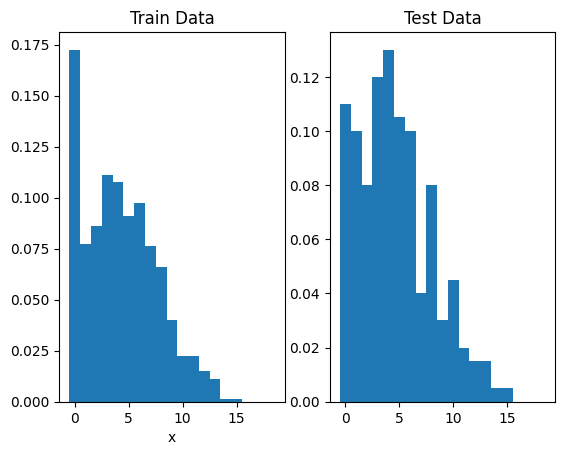

Dataset 2


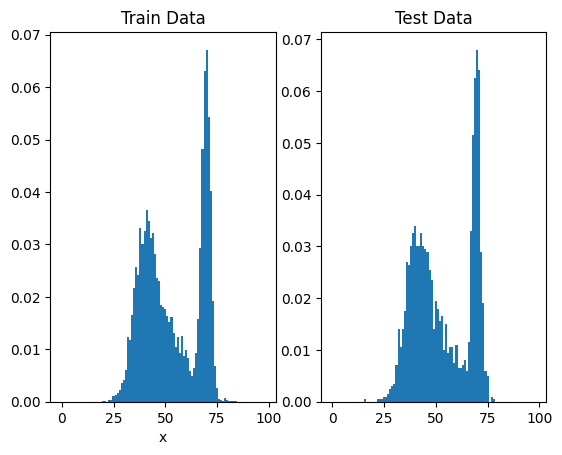

In [ ]:
visualize_q1_data(dset_type=1)
visualize_q1_data(dset_type=2)

## Part (a) Fitting a Histogram

Let $\theta = (\theta_0, \dots, \theta_{d-1}) \in \mathbb{R}^{d}$ and define the model $p_\theta(x) = \frac{e^{\theta_x}}{\sum_{x'}e^{\theta_{x'}}}$

Fit $p_\theta$ with maximum likelihood via stochastic gradient descent on the training set, using $\theta$ initialized to zero. Use your favorite version of stochastic gradient descent, and optimize your hyperparameters on a validation set of your choice.

**You will provide these deliverables**


1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. Plot the model probabilities in a bar graph with $\{0,\dots,d-1\}$ on the x-axis and a real number in $[0,1]$ on the y-axis.




Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
def q1_a(train_data, test_data, d, dset_id):
  """
  train_data: An (n_train,) numpy array of integers in {0, ..., d-1}
  test_data: An (n_test,) numpy array of integers in {0, .., d-1}
  d: The number of possible discrete values for random variable x
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
             used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (d,) of model probabilities
  """
  theta = np.zeros(d)
  epochs, batch_size, lr = 30, max(1, len(train_data) // 10), 0.1

  def nll(data):
    return np.logaddexp.reduce(theta) - np.mean(theta[data])

  train_losses, test_losses = [], [nll(test_data)]
  for _ in range(epochs):
    data = np.random.permutation(train_data)
    for i in range(0, len(data), batch_size):
      batch = data[i:i + batch_size]
      train_losses.append(nll(batch))

      probs = np.exp(theta - np.logaddexp.reduce(theta))
      grad = probs - np.bincount(batch, minlength=d) / len(batch)
      theta -= lr * grad

    test_losses.append(nll(test_data))

  distribution = np.exp(theta - np.logaddexp.reduce(theta))

  return train_losses, test_losses, distribution

### Results

Once you've implemented `q1_a`, execute the cells below to visualize and save your results



Final Test Loss: 2.6224


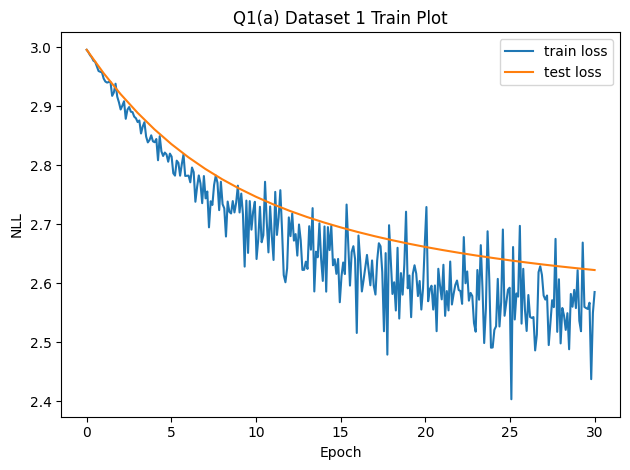

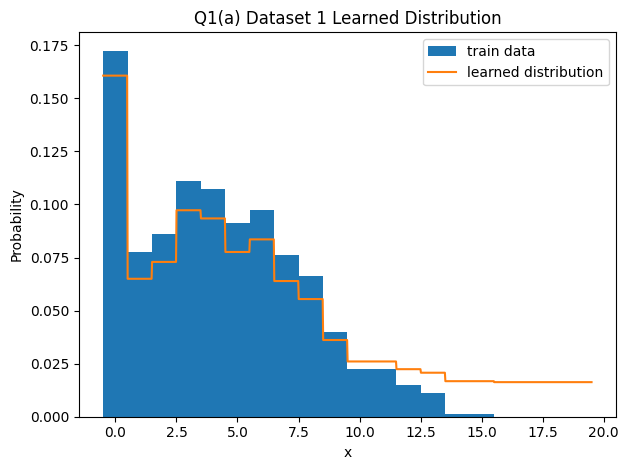

In [ ]:
q1_save_results(1, 'a', q1_a)

Final Test Loss: 4.1481


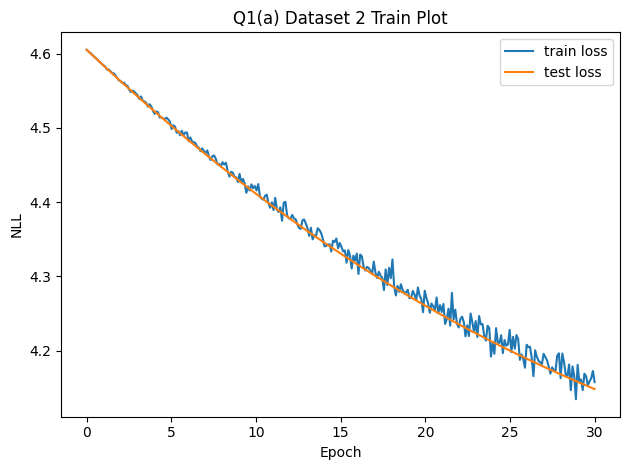

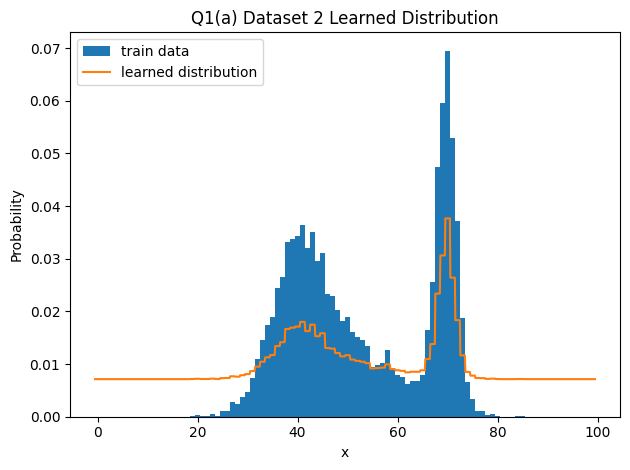

In [ ]:
q1_save_results(2, 'a', q1_a)

## Part (b) Fitting Discretized Mixture of Logistics

Let us model $p_\theta(x)$ as a **discretized** mixture of 4 logistics such that $p_\theta(x) = \sum_{i=1}^4 \pi_i[\sigma((x+0.5 - \mu_i)/s_i) - \sigma((x-0.5-\mu_i)/s_i)]$

For the edge case of when $x = 0$, we replace $x-0.5$ by $-\infty$, and for $x = 99$, we replace $x+0.5$ by $\infty$.

You may find the [PixelCNN++](https://arxiv.org/abs/1701.05517) helpful for more information on discretized mixture of logistics.

**Provide the same set of corresponding deliverables as part (a)**

Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
class DiscretizedMixtureLogistic(nn.Module):
  def __init__(self, d, num_mixtures=4):
    super().__init__()

    self.d = d
    self.num_mixtures = num_mixtures

    # Mixture weights: pi
    self.logits_pi = nn.Parameter(
        torch.zeros(num_mixtures)
    )

    # Initialize center position
    self.mu = nn.Parameter(
        torch.linspace(0, d - 1, num_mixtures)
    )

    # Initialize scales to positive values
    initial_scale = max(d / 4, 1.0)

    self.raw_scale = nn.Parameter(
        torch.full(
          (num_mixtures, ),
          float(np.log(np.expm1(initial_scale)))
        )
    )


  def log_prob(self, x):

    x = x.to(device=self.mu.device, dtype=self.mu.dtype).unsqueeze(-1)

    log_pi = F.log_softmax(self.logits_pi, dim=0)

    s = F.softplus(self.raw_scale) + 1e-6

    upper = (x + 0.5 - self.mu) / s
    lower = (x - 0.5 - self.mu) / s

    log_mass = (
        F.logsigmoid(upper)
        + F.logsigmoid(-lower)
        + torch.log(-torch.expm1(-1.0 / s))
    )

    # (-∞, 0.5)
    log_mass = torch.where(
        x == 0,
        F.logsigmoid(upper),
        log_mass
    )

    # [d - 1.5, +∞)
    log_mass = torch.where(
        x == self.d - 1,
        F.logsigmoid(-lower),
        log_mass
    )

    # [B]
    return torch.logsumexp(log_pi + log_mass, dim=-1)

  def forward(self, x):

    return self.log_prob(x).exp()

  def nll(self, x):

    return -self.log_prob(x).mean()

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader

def q1_b(train_data, test_data, d, dset_id):
  """
  train_data: An (n_train,) numpy array of integers in {0, ..., d-1}
  test_data: An (n_test,) numpy array of integers in {0, .., d-1}
  d: The number of possible discrete values for random variable x
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (d,) of model probabilities
  """
  num_epoches = 100
  batch_size = 128
  learning_rate = 1e-2

  device = torch.device(
      "cuda" if torch.cuda.is_available() else "cpu"
  )

  # numpy -> tensor
  train_tensor = torch.as_tensor(
      train_data, dtype=torch.long
  )
  test_tensor = torch.as_tensor(
      test_data, dtype=torch.long
  )

  train_loader = DataLoader(
      train_tensor,
      batch_size=batch_size,
      shuffle=True,
      drop_last=False
  )

  test_loader = DataLoader(
      test_tensor,
      batch_size=4096,
      shuffle=False
  )

  # initailize model and optimizer
  model = DiscretizedMixtureLogistic(d, 4).to(device)

  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  # evaluate test dataset
  @torch.no_grad()
  def evaluate_test_loss():
    model.eval()
    total_nll = 0.0

    # accumulate loss of every sample
    for x_batch in test_loader:
      x_batch = x_batch.to(device)

      total_nll += (-model.log_prob(x_batch)).sum().item()
    # return mean loss of batch size samples
    return total_nll / len(test_tensor)

  train_losses = []

  # record test loss before training
  test_losses = [evaluate_test_loss()]

  # training
  for epoch in range(num_epoches):
    model.train()

    for x_batch in train_loader:
      x_batch = x_batch.to(device)

      optimizer.zero_grad()

      loss = model.nll(x_batch)
      loss.backward()

      optimizer.step()

      # every minibatch
      train_losses.append(loss.item())

    # record a test loss after a epoch
    test_losses.append(evaluate_test_loss())

  # calculate model probablity
  model.eval()

  with torch.no_grad():
    all_x = torch.arange(d, dtype=torch.long)

    distribution = model(all_x).cpu().numpy()

  return train_losses, test_losses, distribution

### Results

Once you've implemented `q1_b`, execute the cells below to visualize and save your results



Final Test Loss: 2.5492


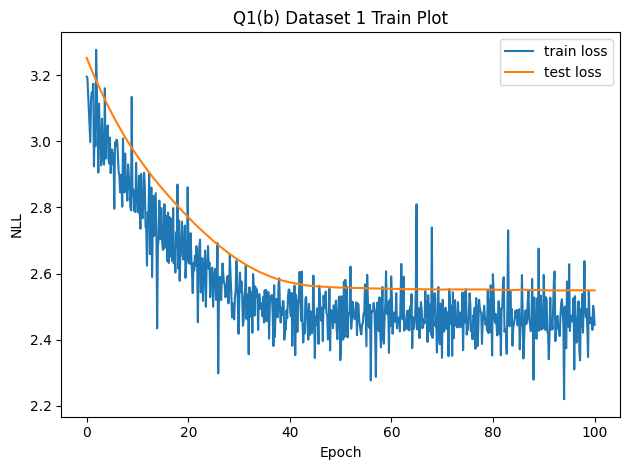

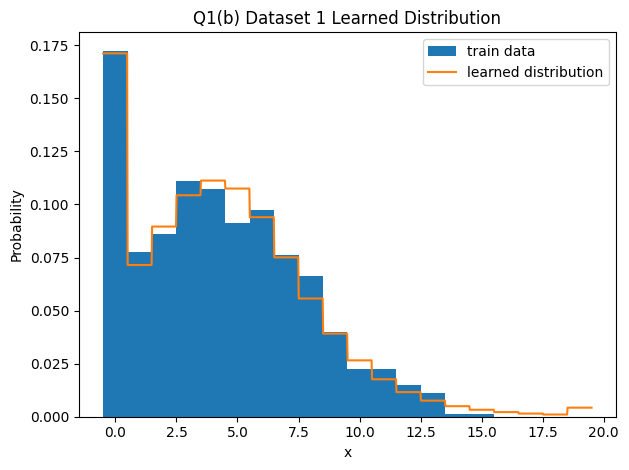

In [ ]:
q1_save_results(1, 'b', q1_b)

In [ ]:
q1_save_results(2, 'b', q1_b)

KeyboardInterrupt: 

# Question 2 PixelCNNs

Now, you will train more powerful PixelCNN models on the shapes dataset and MNIST. In addition, we will extend to modeling colored datasets.

Run the cell below to visualize the two datasets binary datasets

In [ ]:
visualize_q2a_data(1)
visualize_q2a_data(2)

## Part (a) PixelCNN on Shapes and MNIST
In this part, implement a simple PixelCNN architecture to model binary MNIST and shapes images (same as Q2(b), but with a PixelCNN).

We recommend the following network design:
* A $7 \times 7$ masked type A convolution
* $5$ $7 \times 7$ masked type B convolutions
* $2$ $1 \times 1$ masked type B convolutions
* Appropriate ReLU nonlinearities in-between
* 64 convolutional filters

And the following hyperparameters:
* Batch size 128
* Learning rate $10^{-3}$
* 10 epochs
* Adam Optimizer (this applies to all PixelCNN models trained in future parts)

Your model should output logits, after which you could apply a sigmoid over 1 logit, or a softmax over two logits (either is fine). It may also help to scale your input to $[-1, 1]$ before running it through the network.

Training on the shapes dataset should be quick, and MNIST should take around 10 minutes

Checkout the Paper for more details: https://arxiv.org/abs/1601.06759

**You will provide these deliverables**


1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. 100 samples from the final trained model



Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
class MaskedConv2d(nn.Conv2d):
  def __init__(self, in_channels, out_channels, kernel_size, mask_type):
    assert mask_type in ("A", "B")
    assert kernel_size % 2 == 1

    super().__init__(
      in_channels, out_channels, kernel_size,
      padding=kernel_size // 2
    )

    mask = torch.ones_like(self.weight)
    center = kernel_size // 2

    # make 0 pixels
    mask[:, :, center + 1:, :] = 0
    mask[:, :, center, center + 1:] = 0

    # make 0 pixels of special type Conv2d
    if mask_type == "A":
      mask[:, :, center, center] = 0

    self.register_buffer("mask", mask)

  def forward(self, x):
    weight = self.weight * self.mask
    return F.conv2d(
      x, weight, self.bias,
      self.stride, self.padding,
      self.dilation, self.groups
    )

In [ ]:
conv_a = MaskedConv2d(1, 64, 7, "A")
conv_b = MaskedConv2d(64, 64, 7, "B")

print("Type A mask:")
print(conv_a.mask[0, 0])

print("\nType B mask:")
print(conv_b.mask[0, 0])


In [ ]:
class PixelCNN(nn.Module):
  def __init__(self, hidden_channels=64):
    super().__init__()

    layers = []

    # layer 1: type A
    layers.append(
      MaskedConv2d(1, hidden_channels, 7, "A")
    )
    layers.append(nn.ReLU())

    # (layers 2:6): type B
    for _ in range(5):
      layers.append(
        MaskedConv2d(
          hidden_channels, hidden_channels, 7, "B"
        )
      )
      layers.append(nn.ReLU())

    # (layer 7:8) : type B
    for _ in range(2):
      layers.append(
          MaskedConv2d(
            hidden_channels, hidden_channels, 1, "B"
          )
      )
      layers.append(nn.ReLU())

    self.features = nn.Sequential(*layers)

    # map hidden_channels to one logit
    self.output = nn.Conv2d(
      hidden_channels, 1, kernel_size = 1
    )

  def forward(self, x):
    h = self.features(x)
    logits = self.output(h)
    return logits


In [ ]:

model = PixelCNN(hidden_channels=64)

# 模拟 2 张 28×28 的二值图像
x = torch.randint(0, 2, (2, 1, 28, 28)).float()

logits = model(x)

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Parameter count:",
      sum(p.numel() for p in model.parameters()))
print("Output range:", logits.min().item(), logits.max().item())


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
def q2_a(train_data, test_data, image_shape, dset_id):
  """
  train_data: A (n_train, H, W, 1) uint8 numpy array of binary images with values in {0, 1}
  test_data: A (n_test, H, W, 1) uint8 numpy array of binary images with values in {0, 1}
  image_shape: (H, W), height and width of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (100, H, W, 1) of samples with values in {0, 1}
  """
  H, W = image_shape
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  # 1. Convert NHWC to PyTorch's NCHW format
  train_tensor = torch.as_tensor(
      train_data, dtype=torch.float32
  ).permute(0, 3, 1, 2).contiguous()

  test_tensor = torch.as_tensor(
      test_data, dtype=torch.float32
  ).permute(0, 3, 1, 2).contiguous()

  train_loader = DataLoader(
      TensorDataset(train_tensor), batch_size=128, shuffle=True
  )
  test_loader = DataLoader(
      TensorDataset(test_tensor), batch_size=128, shuffle=False
  )

  # 2. Initialize model, loss and optimizer
  model = PixelCNN(hidden_channels=64).to(device)
  criterion = nn.BCEWithLogitsLoss(reduction="sum")
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

  epochs = 10

  train_losses = []
  test_losses = []

  # 3. Evaluation function
  def evaluate():
    model.eval()

    total_loss = 0.0
    total_pixels = 0

    with torch.no_grad():
      for (x,) in test_loader:
        x = x.to(device)

        # scale input from [0,1] to [-1,1]
        x_input = x * 2.0 - 1.0

        logits = model(x_input)

        loss = criterion(logits, x)

        total_loss += loss.item()
        total_pixels += x.numel()

    return total_loss / total_pixels

  # Evaluate before training
  test_losses.append(evaluate())

  # 4. Training
  for epoch in range(epochs):
    model.train()

    for (x,) in train_loader:

      x = x.to(device)

      # Scale input to [-1, 1]
      x_input = x * 2.0 - 1.0

      # Forward pass
      logits = model(x_input)

      # Average NLL per pixel
      loss_sum = criterion(logits, x)
      loss = loss_sum / x.numel()

      # Backpropagation
      optimizer.zero_grad()

      loss.backward()

      optimizer.step()

      # Record training loss for this minibatch
      train_losses.append(loss.item())

    # Evaluate after each epoch
    test_loss = evaluate()
    test_losses.append(test_loss)

    print(
      f"Epoch [{epoch + 1}/{epochs}] "
      f"Train NLL: {np.mean(train_losses[-len(train_loader):]):.4f} "
      f"Test NLL: {test_loss:.4f}"
    )


  # 5. Autoregressive sampling
  model.eval()

  num_samples = 100

  # Initialize all pixels to zero
  samples = torch.zeros(
      num_samples, 1, H, W,
      dtype = torch.float32,
      device=device
  )

  with torch.no_grad():

    # Raster scan: top to bottom, left to right
    for i in range(H):
      for j in range(W):

        # Scale current partially generated images
        x_input = samples * 2.0 - 1.0

        # Predict logits
        logits = model(x_input)

        # Get the probablity of pixel (i, j) being 1
        prob = torch.sigmoid(logits[:, 0, i, j])

        # Sample from Bernoulli distribution
        pixel = torch.bernoulli(prob)

        # Update the current pixel
        samples[:,0,i,j] = pixel

  # Convert NCHW back to NHWC
  samples = (
    samples.permute(0, 2, 3, 1)
    .cpu()
    .numpy()
    .astype(np.uint8)
  )


  # 6. Return results
  train_losses = np.array(train_losses)
  test_losses = np.array(test_losses)



  return train_losses, test_losses, samples

### Results

Once you've implemented `q2_a`, execute the cells below to visualize and save your results



In [ ]:
q2a_save_results(1, q2_a)

In [ ]:
q2a_save_results(2, q2_a)

## Part (b) PixelCNN on Colored Shapes and MNIST: Independent Color Channels

For the next part, we'll work with color images (shapes and MNIST). Run the cell below to visualize the dataset.

In [ ]:
visualize_q2b_data(1)
visualize_q2b_data(2)

Now, implement a PixelCNN to support RGB color channels (or augment your existing implementation). **First, implement a PixelCNN that assumes color channels as independent.** More formally, we model the following parameterized distribution:

$$p_\theta(x) = \prod_{i=1}^{HW}\prod_{c=1}^C p_\theta(x_i^c | x_{<i})$$

Here are some tips that you may find useful for designing and training these models:
* You will need a 4-way softmax for every prediction, as opposed to a 256-way softmax in the PixelCNN paper, since the dataset is quantized to two bits per color channel
* You can set the number of filters for each convolutions to 120. You can use the ReLU nonlinearity throughout.
* Use a stack of 8 residual block architecture from [Figure 5](https://arxiv.org/abs/1601.06759) but with 7 x 7 masked convolutions in the middle instead of 3 x 3 masked convolutions
* Consider using [layer normalization](https://arxiv.org/abs/1607.06450) to improve performance. However, be careful to maintain the autoregressive property.
* With a learning rate of $10^{-3}$ and a batch size of 128, it should take a few minutes to run on the shapes dataset, and about 50-60 minutes on MNIST.

**You will provide these deliverables**


1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. 100 samples from the final trained model



Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MaskedConv2d(nn.Conv2d):
  def __init__(self, mask_type, in_channels, out_channels, kernel_size, padding=0):
    if mask_type not in ("A", "B"):
      raise ValueError("kernel_size must be odd")

    # initialize weights and bias of normal conv2d
    super().__init__(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding)

    # create initial mask
    mask = torch.ones_like(self.weight)
    center = kernel_size // 2

    # make mask perfect
    mask[:, :, center + 1:, :] = 0
    mask[:, :, center, center+1: ] = 0

    if mask_type == "A":
      mask[:, :, center, center] = 0

    self.register_buffer("mask", mask)


  def forward(self, x):
    effective_weight = self.weight * self.mask

    return F.conv2d(x, effective_weight, self.bias, stride=self.stride, padding=self.padding)


In [ ]:
layer = MaskedConv2d(
    mask_type="A",
    in_channels=3,
    out_channels=120,
    kernel_size=7,
    padding=3
)

x = torch.randn(2, 3, 8, 8)
y = layer(x)

print(layer.weight.shape)
print(y.shape)
print(layer.mask[0, 0].int())

In [ ]:
class ResidualBlock(nn.Module):
  def __init__(self, channels=120):
    super().__init__()

    hidden_channels = channels // 2

    # kernel_size = 1
    self.conv1 = MaskedConv2d(mask_type="B", in_channels=channels, out_channels=hidden_channels, kernel_size=1, padding=0)

    # kernel_size = 7
    self.conv2 = MaskedConv2d(mask_type="B", in_channels=hidden_channels, out_channels=hidden_channels, kernel_size=7, padding=3)

    # kernel_size = 1
    self.conv3 = MaskedConv2d(mask_type="B", in_channels=hidden_channels, out_channels=channels, kernel_size=1, padding=0)

  def forward(self, x):
    residual = x

    out = F.relu(x)
    out = self.conv1(out)

    out = F.relu(out)
    out = self.conv2(out)

    out = F.relu(out)
    out = self.conv3(out)

    return residual + out


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RGBPixelCNN(nn.Module):
  def __init__(self):
    super().__init__()

    # 1. Initial Mask A Convolution
    self.input_conv = MaskedConv2d("A", in_channels=3, out_channels=120, kernel_size=7, padding=3)

    # 2. Stack 8 Residual Blocks
    self.res_blocks = nn.Sequential(*[ResidualBlock(channels=120) for _ in range(8)])

    # 3. Output Convolution
    # RGB channels * 3 classes = 12 output channels
    self.output_conv = nn.Conv2d(in_channels=120, out_channels=12, kernel_size=1)


  def forward(self, x):

    # x: [B, 3, H, W]

    # 1. Initial Mask A Convolution
    x = self.input_conv(x)

    # 2. Residual Blocks
    x = self.res_blocks(x)

    # 3. ReLu + Output Convolution
    x = F.relu(x)
    x= self.output_conv(x)

    # 4. Reshape output Logits
    B, _, H, W =x.shape

    x = x.reshape(B, 3, 4, H, W)

    # [B, 3, 4, H, W] -> [B, 4, 3, H, W]
    x = x.permute(0, 2, 1, 3, 4)

    return x


In [ ]:
model = RGBPixelCNN()

# initialize
x = torch.randn(2, 3, 28, 28)

# forward
logits = model(x)

print("input: ", x.shape)
print("output: ", logits.shape)

# check output
assert logits.shape == (2, 4, 3, 28, 28)

print("Forward pass successful!")


In [ ]:
def compute_loss(model, images):
  """
  Compute average negative log-likelihood

  Args:
    model: RGBPixerl
    images: [B, 3, H, W], quantized values in (0, 1, 2, 3)

  Returns:
    loss: scalar average NLL
  """

  # 1. Convert input to float for Conv2d
  x = images.float()

  # 2. Convert target to long for CrossEntropyLoss
  target = images.long()

  # 3. Forward
  logits = model(x)

  # logits: [B, 4, 3, H, W]
  # targets: [B, 3, H, W]

  # 4. Compute average nagative log-likelihood
  loss = F.cross_entropy(logits, target, reduction='mean')

  return loss


def evaluate(model, test_loader, device):

  model.eval()

  total_nll = 0.0
  total_dims = 0

  with torch.no_grad():

    for batch in test_loader:

      images = batch[0] if isinstance(batch, (tuple, list)) else batch

      images = images.to(device)

      x = images.float()
      target = images.long()

      logits = model(x)

      # sum all negative log-likelihoods

      loss = F.cross_entropy(logits, target, reduction='sum')

      total_nll += loss.item()

      total_dims += target.numel()


    # Average NLL per dimension
    test_nll = total_nll /total_dims

    return test_nll


def train_model(model, train_loader, test_loader, device, num_epochs):
  # 1. Move model to device
  model = model.to(device)

  # 2. Initialize Adam optimzier
  optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

  # record training and testing NLL
  train_nll_history = []
  test_nll_history = []

  # 3. start training
  for epoch in num_epochs:

    model.train()

    epoch_total_nll = 0.0
    epoch_total_dims = 0

    for batch in train_loader:
      # extract images

      images = batch[0] if isinstance(batch, (tuple, list)) else batch

      images = images.to(device)

      # Convert images to input and target
      x = image.float()
      target = images.long()

      # Clear previous gradients
      optimizer.zero_grad()

      # Forward pass
      logits = model(x)

      # Compute average NLL
      loss = F.cross_entropy(logits, target, reduction='mean')

      # Backward parameters
      loss.backward()

      # Update parameters
      optimizer.step()

      # Record NLL for every minibatch
      train_nll_history.append(loss.item())

      # Accumulate epoch statistics
      epoch_total_nll += loss.item() * target.numel()
      epoch_total_dims += target.numel()

    # Average training NLL for this epoch
    train_epoch_nll = epoch_total_nll / epoch_total_dims

    # Evaluate on the entire test set
    test_epoch_nll = evaluate(model, test_loader, device)

    test_nll_history.append(test_epoch_nll)

    print(
      f"Epoch [{epoch + 1}/{num_epochs}] "
      f"Train NLL: {train_epoch_nll:.4f} "
      f"Test NLL: {test_epoch_nll:.4f}"
    )
  return train_nll_history, test_nll_history




In [ ]:
# Create model
model = RGBPixelCNN()

# Create a random quantized RGB image
images = torch.randint(
    0, 4,
    (2, 3, 28, 28)
)

# Compute loss
loss = compute_loss(model, images)

print("Loss:", loss.item())
print("Loss shape:", loss.shape)

In [ ]:
def q2_b(train_data, test_data, image_shape, dset_id):
  """
  train_data: A (n_train, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  test_data: A (n_test, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  image_shape: (H, W, C), height, width, and # of channels of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (100, H, W, C) of samples with values in {0, 1, 2, 3}
  """

  def evaluate_pixelcnn(model, test_loader, device):
    """
    Assume test_loader's type is TensorDataset
    """
    model.eval()

    total_nll = 0.0
    total_dims = 0

    with torch.no_grad():
      for (images, ) in test_loader:

        images = images.to(device)
        x = images.float()
        targets = images.long()

        logits = model(x)

        loss = F.cross_entropy(logits, targets, reduction="sum")

        total_nll += loss.item()
        total_dims += targets.numel()
    return (total_nll / total_dims)

  def sample_pixelcnn(model, image_shape, device, n_samples=100):

    H, W, C = image_shape
    model.eval()

    model_device = next(model.parameters()).device

    # Initialize empty images
    generated = torch.zeros(n_samples, C, H, W, dtype=torch.float32, device=model_device)


    with torch.no_grad():
      for i in range(H):
        for j in range(W):

          logits = model(generated)

          # Extract current pixel logits
          # [N, 4, 3, H, W] -> [N, 4, 3]
          pixel_logits = logits[:, :, :, i, j]

          # [N, 4, 3] -> [N, 3, 4]
          # put the 4 classes in the lass dimension
          pixel_logits = pixel_logits.permute(0, 2, 1)

          # Sample R, G, B independtly
          pixel_samples = torch.distributions.Categorical(logits=pixel_logits).sample()

          # Check shape
          assert pixel_samples.shape == (n_samples, 3)

          # FIll in the generated pixel
          generated[:, :, i, j] = pixel_samples.float()


    # Convert NCHW -> NHWC
    samples = generated.permute(0, 2, 3, 1)

    return samples.cpu().numpy().astype(np.uint8)


  batch_size = 128
  learning_rate = 1e-3
  num_epochs = 10

  H, W, C = image_shape

  assert dset_id in [1, 2]
  assert C == 3

  assert tuple(train_data.shape[1:]) == tuple(image_shape)
  assert tuple(test_data.shape[1:]) == tuple(image_shape)

  assert train_data.min() >= 0 and train_data.max() <= 3
  assert test_data.min() >= 0 and test_data.max() <= 3

  # 2. Prepare Dataset

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  # NHWC -> NCHW

  train_tensor = torch.from_numpy(np.ascontiguousarray(train_data.transpose(0, 3, 1, 2)))

  test_tensor = torch.from_numpy(np.ascontiguousarray(test_data.transpose(0, 3, 1, 2)))

  train_loader = DataLoader(TensorDataset(train_tensor), batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=(device.type == "cuda"))

  test_loader = DataLoader(TensorDataset(test_tensor), batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=(device.type == "cuda"))

  # Initialize model
  model = RGBPixelCNN().to(device)

  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  # Evaluate Initial Test NLL

  test_losses = []

  initial_test_nll = evaluate_pixelcnn(model, test_loader, device)

  test_losses.append(initial_test_nll)

  print(f"Initial Test NLL: {initial_test_nll:.4f}")

  # Training
  train_losses = []

  for epoch in range(num_epochs):

    model.train()

    epoch_total_nll = 0.0
    epoch_total_dims = 0

    for (images, ) in train_loader:
      images = images.to(device, non_blocking=True)

      x = images.float()
      target = images.long()

      optimizer.zero_grad(set_to_none=True)

      logits = model(x)

      loss = F.cross_entropy(logits, target, reduction="mean")

      loss.backward()

      optimizer.step()

      train_losses.append(loss.item())

      epoch_total_nll += loss.item() * target.numel()
      epoch_total_dims += target.numel()


    # Average training NLL
    train_epoch_nll = (epoch_total_nll / epoch_total_dims)

    # Evaulate entire test set
    test_epoch_nll = evaluate_pixelcnn(model, test_loader, device)

    test_losses.append(test_epoch_nll)

    print(
      f"Epoch [{epoch + 1}/{num_epochs}] "
      f"Train NLL: {train_epoch_nll:.4f} "
      f"Test NLL: {test_epoch_nll:.4f}"
    )

  samples = sample_pixelcnn(
      model,
      image_shape,
      device,
      n_samples=100
  )

  train_losses = np.asarray(
      train_losses,
      dtype=np.float32
  )

  test_losses = np.asarray(
      test_losses,
      dtype=np.float32
  )

  return train_losses, test_losses, samples

### Results

Once you've implemented `q2_b`, execute the cells below to visualize and save your results



In [ ]:
q2b_save_results(1, 'b', q2_b)

In [ ]:
q2b_save_results(2, 'b', q2_b)

# Question 3: Causal Transformer - iGPT

Now we will move onto the current most popular and widespread autoregressive model, the transformer.

## Part (a) Autoregressive Transformer on Shapes and MNIST
In this part, implement a simple Autoregressive Transformer to model binary MNIST and shapes images (same as Q2(a), but with a Transformer).

Some additional notes about your transformer implementation:
 * iGPT uses learned positional encodings. We recommend to use those here as well. However, you may also use sinusoidal positional encodings if you wish (see the [Attention is All You Need](https://arxiv.org/abs/1706.03762) paper)
 * Autoregressive transformer always predicts the **next** token, give prior tokens. iGPT has a special **\<bos\>** or beginning of sequence token at the start of every sequence every image. Make sure to include this in your implementation as well. You can generate unconditional sample by conditioning with the **\<bos\>** token.
 * While dropout is a common feature in transformer models, you do not need to add it (but may if you wish!).
 * Prebuilt transformers exist in some frameworks (i.e. pytorch). Don't just use an off the shelf implementation as the point of the exercise is to better understand the transformer architecture. Building the transformer from the ground up (use primitives such as Linear/Dense layers, LayerNorm, GeLU, Embedding)
 * Learning rate warmup and cos learning rate decay are often used when training transformers to improve training stability and improve performance. See if this helps your model! Try 1000 steps of warmup with a cosine learning rate decay.

Paper references
* [Attention Is All You Need](https://arxiv.org/abs/1706.03762)
* [Generative Pretraining from Pixels](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)
* [Language Models are Unsupervised Multitask Learners](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)

We recommend the following network design parameters:
* $d_{model}$: 128
* heads: 4
* layers: 2
* GeLU nonlinearities

And the following hyperparameters:
* Batch size: 64 or 32 or 16 (whichever fits in your GPU)
* Learning rate: $10^{-3}$
* 15 epochs or more
* Adam Optimizer (this applies to all Transformers models trained in future parts)

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. 100 samples from the final trained model



In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

def prepare_data(date):
  """
  data: (N, H, W, 1), uint8, values in {0, 1}
  return (N, H*W), uint8
  """
  data = torch.from_numpy(data)

  data = data.reshape(data.shape[0], -1)

  return data

In [ ]:
def make_autoregressive_input(pixels, device):

    # 确保 pixels 在指定设备上
    pixels = pixels.to(
        device=device,
        dtype=torch.long
    )

    batch_size = pixels.shape[0]

    # BOS 也放在 pixels 所在的设备上
    bos = torch.full(
        (batch_size, 1),
        2,
        dtype=torch.long,
        device=pixels.device
    )

    # BOS + 原始像素（去掉最后一个）
    input_ids = torch.cat(
        [bos, pixels[:, :-1]],
        dim=1
    )

    targets = pixels

    return input_ids, targets

In [ ]:
pixels = torch.tensor([
    [1, 0, 0, 1],
    [0, 1, 1, 0]
])

input_ids, targets = make_autoregressive_input(
    pixels, device="cpu"
)

print("Input:")
print(input_ids)

print("Targets:")
print(targets)

Input:
tensor([[2, 1, 0, 0],
        [2, 0, 1, 1]])
Targets:
tensor([[1, 0, 0, 1],
        [0, 1, 1, 0]])


In [ ]:
class CausalSelfAttention(nn.Module):

  def __init__(self, d_model=128, num_heads=4, max_seq_len=784):
    super().__init__()

    assert d_model % num_heads == 0

    self.d_model = d_model
    self.num_heads = num_heads

    # single head
    self.head_dim = d_model // num_heads

    # Q, K, V
    self.q_proj = nn.Linear(d_model, d_model)
    self.k_proj = nn.Linear(d_model, d_model)
    self.v_proj = nn.Linear(d_model, d_model)

    # output head
    self.out_proj = nn.Linear(d_model, d_model)

    # mask
    mask = torch.triu(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool), diagonal=1)

    self.register_buffer("causal_mask", mask)

  def forward(self, x):

    B, L, D = x.shape

    # 1. Q, K, V
    q = self.q_proj(x)
    k = self.k_proj(x)
    v = self.v_proj(x)

    # 2.Multi-Head
    q = q.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    k = k.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    v = v.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    # 3. Calculate Attention Score
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)

    # 4. Add Mask
    mask = self.causal_mask[:L, :L]

    scores = scores.masked_fill(mask, float("-inf"))

    # 5. Softmax
    attn_weights = torch.softmax(scores, dim=-1)

    # 6. Attention Weight
    out = torch.matmul(attn_weights, v)

    # 7. Merge head
    out = out.transpose(1, 2).contiguous()

    out = out.view(B, L, D)

    # 8. outhead
    out = self.out_proj(out)

    return out




In [ ]:
B = 2
L = 784
D = 128

x = torch.randn(B, L, D)

attention = CausalSelfAttention(
    d_model=128,
    num_heads=4,
    max_seq_len=784
)

y = attention(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)

Input shape: torch.Size([2, 784, 128])
Output shape: torch.Size([2, 784, 128])


In [ ]:
class TransformerBlock(nn.Module):

  def __init__(self, d_model=128, num_heads=4, max_seq_len=784):
    super().__init__()

    self.ln1 = nn.LayerNorm(d_model)

    # Multi-Head Causal Self-Attention
    self.attention = CausalSelfAttention(d_model=d_model, num_heads=num_heads, max_seq_len=max_seq_len)

    self.ln2 = nn.LayerNorm(d_model)

    # FNN
    self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

  def forward(self, x):

    # 1. Pre-LN + Attention + Residual
    x = x + self.attention(self.ln1(x))

    # 2. Pre-LN + FFN + Residual
    x = x + self.mlp(self.ln2(x))

    return x

In [ ]:
# Test Transformer Block
B = 2
L = 784
D = 128

x = torch.randn(B, L, D)

block = TransformerBlock(
    d_model=128,
    num_heads=4,
    max_seq_len=784
)

y = block(x)

print("Input:", x.shape)
print("Output:", y.shape)

# Test gradient
x = torch.randn(
    2, 784, 128,
    requires_grad=True
)

y = block(x)

loss = y.mean()

loss.backward()

print("Input gradient exists:", x.grad is not None)
print(
    "Attention gradient exists:",
    block.attention.q_proj.weight.grad is not None
)

Input: torch.Size([2, 784, 128])
Output: torch.Size([2, 784, 128])
Input gradient exists: True
Attention gradient exists: True


In [ ]:
class AutoregressiveTransformer(nn.Module):

  def __init__(self, max_seq_len=784, d_model=128, num_heads=4, num_layers=2):

    super().__init__()

    self.max_seq_len = max_seq_len

    # Token Embedding
    self.token_embedding = nn.Embedding(num_embeddings=3, embedding_dim=d_model)

    # Learned Positional Embedding
    self.position_embedding = nn.Embedding(num_embeddings=max_seq_len, embedding_dim=d_model)

    # Transformer Blocks
    self.blocks = nn.ModuleList([TransformerBlock(d_model=d_model, num_heads=num_heads, max_seq_len=max_seq_len) for _ in range(num_layers)])

    # Final LayerNorm
    self.ln_f = nn.LayerNorm(d_model)

    # Output Head
    self.head = nn.Linear(d_model, 2)

  def forward(self, input_ids):

    B, L = input_ids.shape

    assert L <= self.max_seq_len

    # Token Embedding
    token_emb = self.token_embedding(input_ids)

    # Position Embedding
    positions = torch.arange(L, device=input_ids.device)
    pos_emb = self.position_embedding(positions)

    # Combine token and position embeddings
    x = token_emb + pos_emb

    # Transformer Blocks
    for block in self.blocks:
      x = block(x)

    # Final LayerNorm
    x = self.ln_f(x)

    # Output
    logits = self.head(x)

    return logits


In [ ]:
@torch.no_grad()
def evaluate_nll(model, test_loader, device):

  model.eval()

  total_nll = 0.0
  total_dim = 0

  for (pixels, ) in test_loader:

    pixels = pixels.to(device, dtype=torch.long)

    # Construct input
    input_ids, targets = make_autoregressive_input(pixels, device)

    # Forward
    logits = model(input_ids)

    # nll
    loss_sum = F.cross_entropy(
    logits.reshape(-1, 2),
    targets.reshape(-1),
    reduction="sum"
)

    total_nll += loss_sum.item()

    # dim
    total_dim += targets.numel()


  test_nll = total_nll / total_dim

  return test_nll


In [ ]:
def train_autoregressive_transformer(train_data, test_data, image_shape, num_epoch=15, batch_size=16, lr=1e-3, d_model=128, num_heads=4, num_layers=2):

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  max_seq_len = int(np.prod(image_shape))

  train_pixels = torch.as_tensor(train_data).reshape(len(train_data), -1).long()
  test_pixels = torch.as_tensor(test_data).reshape(len(test_data), -1).long()

  train_loader = DataLoader(TensorDataset(train_pixels), batch_size=batch_size, shuffle=True)

  test_loader = DataLoader(TensorDataset(test_pixels), batch_size=batch_size, shuffle=False)

  model = AutoregressiveTransformer(max_seq_len=max_seq_len, d_model=d_model, num_heads=num_heads, num_layers=num_layers).to(device)

  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  total_steps = num_epoch * len(train_loader)

  warmup_steps = min(1000, max(1, total_steps // 10))

  def lr_lambda(current_step):

    # Linear Warmup
    if current_step < warmup_steps:

        return float(current_step + 1) / float(warmup_steps)

    # Cosine Decay
    progress = (
        current_step - warmup_steps
    ) / max(
        1,
        total_steps - warmup_steps
    )


    progress = min(max(progress, 0.0), 1.0)

    return 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )

  scheduler = torch.optim.lr_scheduler.LambdaLR(
      optimizer,
      lr_lambda
  )


  # Evaluate
  test_losses = []

  initial_test_loss = evaluate_nll(
      model,
      test_loader,
      device
  )

  test_losses.append(initial_test_loss)

  print(
      f"Initial Test NLL: {initial_test_loss:.4f}"
  )


  # Training
  train_losses = []

  for epoch in range(num_epoch):

    model.train()

    for (pixels,) in train_loader:
      pixels = pixels.to(device=device, dtype=torch.long)

      # Construct input and target
      input_ids, targets = make_autoregressive_input(pixels, device)

      optimizer.zero_grad(set_to_none=True)

      # Forward
      logits = model(input_ids)

      # loss
      loss = F.cross_entropy(logits.reshape(-1, 2), target.reshape(-1), reduction="mean")

      # backward
      loss.backward()

      optimizer.steps()

      scheduler.step()

      train_losses.append(loss.item())

    test_loss = evaluate_nll(model, test_loader, device)

    test_losses.append(test_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Test NLL: {test_loss:.4f} "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    return (
        model,
        np.array(train_losses),
        np.array(test_losses)
    )


In [ ]:

@torch.no_grad()
def sample_images(
    model,
    num_samples,
    image_shape,
    device,
    sample_batch_size=8
):

    model.eval()

    H, W, C = image_shape

    seq_len = H * W * C

    all_samples = []

    # 分批生成，避免显存占用过大
    for start in range(0, num_samples, sample_batch_size):

        current_batch = min(
            sample_batch_size,
            num_samples - start
        )

        # 预分配序列空间
        # 第一个位置放 BOS，后面放生成的像素
        generated = torch.empty(
            current_batch,
            seq_len + 1,
            dtype=torch.long,
            device=device
        )

        generated[:, 0] = 2

        # 自回归生成
        for t in range(seq_len):

            # 只输入已经生成的前缀
            input_ids = generated[:, :t+1]

            # Transformer 前向传播
            logits = model(input_ids)

            # 取最后一个位置的预测
            next_logits = logits[:, -1, :]

            # 转换为概率
            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            # 随机采样下一个像素
            next_token = torch.multinomial(
                probs,
                num_samples=1
            )

            # 保存新生成的像素
            generated[:, t+1] = next_token.squeeze(1)

        # 删除 BOS
        pixels = generated[:, 1:]

        # 恢复图像形状
        images = pixels.reshape(
            current_batch,
            H,
            W,
            C
        )

        all_samples.append(
            images.cpu().numpy().astype(np.uint8)
        )

    return np.concatenate(
        all_samples,
        axis=0
    )


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
def q3_a(train_data, test_data, image_shape, dset_id):

    # =====================================
    # 1. Hyperparameters
    # =====================================

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    batch_size = 16
    num_epochs = 15

    d_model = 128
    num_heads = 4
    num_layers = 2

    lr = 1e-3

    # Sequence length
    max_seq_len = int(np.prod(image_shape))

    # =====================================
    # 2. Prepare data
    # =====================================

    train_pixels = torch.as_tensor(
        train_data,
        dtype=torch.long
    ).reshape(len(train_data), -1)

    test_pixels = torch.as_tensor(
        test_data,
        dtype=torch.long
    ).reshape(len(test_data), -1)

    # =====================================
    # 3. DataLoader
    # =====================================

    train_loader = DataLoader(
        TensorDataset(train_pixels),
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(test_pixels),
        batch_size=batch_size,
        shuffle=False
    )

    # =====================================
    # 4. Initialize model
    # =====================================

    model = AutoregressiveTransformer(
        max_seq_len=max_seq_len,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    ).to(device)

    # =====================================
    # 5. Optimizer
    # =====================================

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # =====================================
    # 6. Learning Rate Scheduler
    # =====================================

    total_steps = num_epochs * len(train_loader)

    warmup_steps = min(
        1000,
        max(1, total_steps // 10)
    )

    def lr_lambda(current_step):

        # Warmup
        if current_step < warmup_steps:

            return float(current_step + 1) / warmup_steps

        # Cosine Decay
        progress = (
            current_step - warmup_steps
        ) / max(
            1,
            total_steps - warmup_steps
        )

        progress = min(max(progress, 0.0), 1.0)

        return 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda
    )

    # =====================================
    # 7. Evaluate before training
    # =====================================

    test_losses = []

    initial_test_loss = evaluate_nll(
        model,
        test_loader,
        device
    )

    test_losses.append(initial_test_loss)

    print(
        f"Initial Test NLL: {initial_test_loss:.4f}"
    )

    # =====================================
    # 8. Training
    # =====================================

    train_losses = []

    for epoch in range(num_epochs):

        model.train()

        for (pixels,) in train_loader:

            pixels = pixels.to(
                device=device,
                dtype=torch.long
            )

            # Construct BOS input and targets
            input_ids, targets = make_autoregressive_input(
                pixels, device
            )

            # Clear gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward
            logits = model(input_ids)

            # Calculate NLL / dim
            loss = F.cross_entropy(
                logits.reshape(-1, 2),
                targets.reshape(-1),
                reduction="mean"
            )

            # Backward
            loss.backward()

            # Update parameters
            optimizer.step()

            # Update learning rate
            scheduler.step()

            # Record minibatch loss
            train_losses.append(loss.item())

        # =================================
        # 9. Evaluate after each epoch
        # =================================

        test_loss = evaluate_nll(
            model,
            test_loader,
            device
        )

        test_losses.append(test_loss)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train NLL: {np.mean(train_losses[-len(train_loader):]):.4f} "
            f"Test NLL: {test_loss:.4f}"
        )

    # =====================================
    # 10. Generate 100 samples
    # =====================================

    samples = sample_images(
        model=model,
        num_samples=100,
        image_shape=image_shape,
        device=device,
        sample_batch_size=8
    )

    # =====================================
    # 11. Return deliverables
    # =====================================

    train_losses = np.array(train_losses)
    test_losses = np.array(test_losses)

    return train_losses, test_losses, samples


### Results

Once you've implemented `q3_a`, execute the cells below to visualize and save your results

Initial Test NLL: 0.8124
Epoch [1/15] Train NLL: 0.1667 Test NLL: 0.0817
Epoch [2/15] Train NLL: 0.0658 Test NLL: 0.0587
Epoch [3/15] Train NLL: 0.0510 Test NLL: 0.0478
Epoch [4/15] Train NLL: 0.0462 Test NLL: 0.0446
Epoch [5/15] Train NLL: 0.0435 Test NLL: 0.0428
Epoch [6/15] Train NLL: 0.0416 Test NLL: 0.0412
Epoch [7/15] Train NLL: 0.0401 Test NLL: 0.0400
Epoch [8/15] Train NLL: 0.0389 Test NLL: 0.0392
Epoch [9/15] Train NLL: 0.0377 Test NLL: 0.0381
Epoch [10/15] Train NLL: 0.0366 Test NLL: 0.0372
Epoch [11/15] Train NLL: 0.0356 Test NLL: 0.0365
Epoch [12/15] Train NLL: 0.0346 Test NLL: 0.0359
Epoch [13/15] Train NLL: 0.0338 Test NLL: 0.0355
Epoch [14/15] Train NLL: 0.0333 Test NLL: 0.0353
Epoch [15/15] Train NLL: 0.0329 Test NLL: 0.0353
Final Test Loss: 0.0353


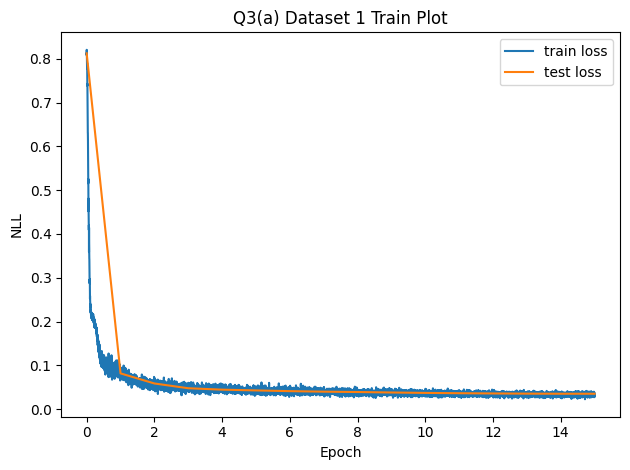

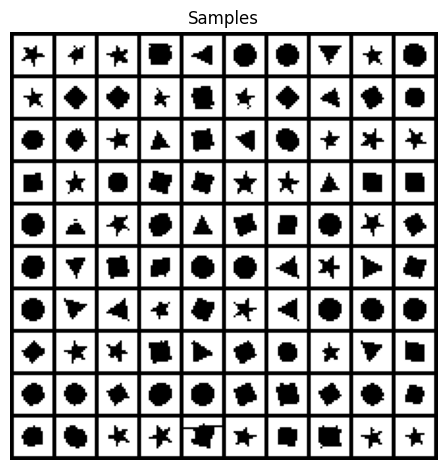

In [ ]:
q3ab_save_results(1, 'a', q3_a)

In [ ]:
q3ab_save_results(2, 'a', q3_a)

Initial Test NLL: 0.9423


KeyboardInterrupt: 

## Part (b) iGPT on Colored Shapes and MNIST

Now, implement an iGPT that models color. In order to reduce the length of token sequences, iGPT models each RGB pixel as a **single** token. This effectively reduces the context length from H*W*C to just H*W. iGPT does this through a k-means clustering approach. Because our images only each can only take on 4 values (2 bits) per channel, we can represent each pixel with 64 values (6 bits). Convert the dataset into an image of tokens and train iGPT on the colored shapes and MNIST dataset.

Checkout the iGPT paper for more details: [Generative Pretraining from Pixels](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)

Training times and hyperparameter settings should be the same as part (a), except train for longer (15 epochs)

**You will provide these deliverables**

1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. 100 samples from the final trained model


In [ ]:
import numpy as np
import torch
def images_to_tokens(image, device):
  """
  images: (N, H, W, C), uint8
  return: (N, H*W), torch.long
  """
  x = torch.as_tensor(image, dtype=torch.long, device=device)

  N, H, W, C = x.shape

  # every channel has {0, 1, 2, 3}
  assert x.min() >= 0 and x.max() <= 3

  # RGB: (R, G, B) has 0~63 integers map
  weights = torch.tensor([4 ** (C - 1 - i) for i in range(C)], device=device)

  tokens = (x * weights).sum(dim=-1)

  return tokens.reshape(N, H * W)


In [ ]:
import numpy as np
import torch

def tokens_to_images(tokens, image_shape):
    """
    Convert discrete image tokens back into the original images.

    Args:
        tokens: Token sequences with shape (N, H*W).
        image_shape: Tuple (H, W, C) describing the image dimensions.

    Returns:
        images: Reconstructed images with shape (N, H, W, C),
                represented as a numpy.uint8 array.
    """

    H, W, C = image_shape

    tokens = torch.as_tensor(tokens, dtype=torch.long)

    channels = []

    for i in range(C):

        # Calculate the positional divisor for each channel
        divisor = 4 ** (C - 1 - i)

        # Decode the corresponding channel value
        channel = (tokens // divisor) % 4

        channels.append(channel)

    # Stack channels along the last dimension
    images = torch.stack(channels, dim=-1)

    # Restore the original image dimensions
    images = images.reshape(-1, H, W, C)

    return images.detach().cpu().numpy().astype(np.uint8)



In [ ]:
# Test
toy_images = np.random.randint(
    0,
    4,
    size=(2, 4, 4, 3),
    dtype=np.uint8
)

# Images -> Token
toy_tokens = images_to_tokens(toy_images, "cpu")

# Token -> Images
reconstructed = tokens_to_images(
    toy_tokens,
    (4, 4, 3)
)

print("Original shape:", toy_images.shape)
print("Token shape:", toy_tokens.shape)
print("Reconstructed shape:", reconstructed.shape)

assert np.array_equal(toy_images, reconstructed)

print("Test passed!")

Original shape: (2, 4, 4, 3)
Token shape: torch.Size([2, 16])
Reconstructed shape: (2, 4, 4, 3)
Test passed!


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class CausalSelfAttention(nn.Module):

  def __init__(self, d_model=128, num_heads=4, max_seq_len=784):
    super().__init__()

    assert d_model % num_heads == 0

    self.d_model = d_model
    self.num_heads = num_heads
    self.head_dim = d_model // num_heads

    # Q, K, V
    self.q_proj = nn.Linear(d_model, d_model)
    self.k_proj = nn.Linear(d_model, d_model)
    self.v_proj = nn.Linear(d_model, d_model)

    self.out_proj = nn.Linear(d_model, d_model)

    # Mask
    mask = torch.triu(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool), diagonal=1)

    self.register_buffer("causal_mask", mask)


  def forward(self, x):

    B, L, D = x.shape

    # Q, K, V
    q = self.q_proj(x)
    k = self.k_proj(x)
    v = self.v_proj(x)

    # (B, L, D) -> (B, heads, L, head_dim)
    q = q.view(
        B, L, self.num_heads, self.head_dim
    ).transpose(1, 2)

    k = k.view(
        B, L, self.num_heads, self.head_dim
    ).transpose(1, 2)

    v = v.view(
        B, L, self.num_heads, self.head_dim
    ).transpose(1, 2)

    # Attention Score
    scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(self.head_dim)

    # Mask
    mask = self.causal_mask[:L, :L]

    scores = scores.masked_fill(mask, float("-inf"))

    # Softmax
    attn_weights = torch.softmax(scores, dim=-1)

    out = torch.matmul(attn_weights, v)

    # merge heads
    out = out.transpose(1, 2).contiguous()
    out = out.view(B, L, D)

    out = self.out_proj(out)

    return out



In [ ]:
class TransformerBlock(nn.Module):

  def __init__(
      self,
      d_model=128,
      num_heads=4,
      max_seq_len=784
  ):

    super().__init__()

    self.ln1 = nn.LayerNorm(d_model)

    self.attention = CausalSelfAttention(d_model=d_model, num_heads=num_heads, max_seq_len=max_seq_len)

    self.ln2 = nn.LayerNorm(d_model)

    # FFN
    self.mlp = nn.Sequential(nn.Linear(d_model, 4*d_model), nn.GELU(), nn.Linear(4*d_model, d_model))

  def forward(self, x):

    x = x + self.attention(self.ln1(x))

    x = x + self.mlp(self.ln2(x))

    return x



In [ ]:
class AutoregressiveTransformer(nn.Module):

  def __init__(
      self,
      max_seq_len,
      vocab_size,
      d_model=128,
      num_heads=4,
      num_layers=2
  ):
    super().__init__()

    self.max_seq_len = max_seq_len
    self.vocab_size = vocab_size

    self.bos_token = vocab_size

    # Token Embedding
    self.token_embedding = nn.Embedding(
      num_embeddings=vocab_size + 1,
      embedding_dim=d_model
    )

    # Learned Positional Embedding
    self.position_embedding = nn.Embedding(
        num_embeddings=max_seq_len,
        embedding_dim=d_model
    )

    # Transformer Blocks

    self.blocks = nn.ModuleList([
      TransformerBlock(
          d_model=d_model,
          num_heads=num_heads,
          max_seq_len=max_seq_len
      )
      for _ in range(num_layers)
    ])

    # Final LayerNorm
    self.ln_f = nn.LayerNorm(d_model)
    self.head = nn.Linear(
        d_model,
        vocab_size
    )


  def forward(self, input_ids):

      B, L = input_ids.shape

      assert L <= self.max_seq_len

      # 1. Token Embedding
      token_emb = self.token_embedding(input_ids)

      # 2. Position Embedding
      positions = torch.arange(
          L,
          device=input_ids.device
      )

      pos_emb = self.position_embedding(positions)

      # 3. Combine Embeddings
      x = token_emb + pos_emb

      # 4. Transformer Blocks
      for block in self.blocks:
          x = block(x)

      # 5. Final LayerNorm
      x = self.ln_f(x)

      # 6. Output Head
      logits = self.head(x)

      return logits

In [ ]:
def make_autoregressive_input(pixels, bos_token):
    """

    Args:
        pixels: (B, L)，真实图像 Token
        bos_token: BOS Token ID

    Returns:
        input_ids: (B, L)
        targets:   (B, L)
    """

    pixels = pixels.to(dtype=torch.long)

    B = pixels.shape[0]

    bos = torch.full(
        (B, 1),
        bos_token,
        dtype=torch.long,
        device=pixels.device
    )

    input_ids = torch.cat(
        [bos, pixels[:, :-1]],
        dim=1
    )

    targets = pixels

    return input_ids, targets

In [ ]:
def compute_nll_per_dim(logits, targets, vocab_size, channels):
    """
    Compute the average negative log-likelihood per image dimension.

    Args:
        logits: Model predictions with shape (B, L, V).
        targets: Ground-truth token IDs with shape (B, L).
        vocab_size: Number of possible image tokens.
        channels: Number of image channels.

    Returns:
        loss: Scalar tensor representing the average NLL in nats/dim.
    """

    # Merge batch and sequence dimensions
    logits = logits.reshape(-1, vocab_size)
    targets = targets.reshape(-1)

    # Compute the average cross-entropy loss
    loss = F.cross_entropy(
        logits,
        targets,
        reduction="mean"
    )

    # Normalize by the number of image channels
    loss = loss / channels

    return loss

In [ ]:
@torch.no_grad()
def evaluate_igpt_nll(
    model,
    test_loader,
    device,
    vocab_size,
    bos_token,
    channels
):
    """
    Evaluate the average negative log-likelihood per dimension
    over the entire test dataset.

    Args:
        model: The autoregressive image generation model.
        test_loader: DataLoader containing the test dataset.
        device: Device used for computation (CPU or CUDA).
        vocab_size: Number of possible image tokens.
        bos_token: Token ID used for the beginning-of-sequence token.
        channels: Number of image channels.

    Returns:
        test_nll: Average negative log-likelihood in nats/dim
                  over the entire test dataset.
    """

    model.eval()

    total_nll = 0.0
    total_dim = 0

    for (pixels,) in test_loader:

        pixels = pixels.to(
            device=device,
            dtype=torch.long
        )

        # Construct autoregressive inputs and targets
        input_ids, targets = make_autoregressive_input(
            pixels,
            bos_token
        )

        # Forward pass
        logits = model(input_ids)

        # Compute the sum of negative log-likelihoods
        loss_sum = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            targets.reshape(-1),
            reduction="sum"
        )

        total_nll += loss_sum.item()

        # Count the total number of image dimensions
        total_dim += targets.numel() * channels

    # Compute the average NLL per image dimension
    test_nll = total_nll / total_dim

    return test_nll

In [ ]:

def train_igpt(
    model,
    train_loader,
    test_loader,
    device,
    vocab_size,
    bos_token,
    channels,
    num_epochs=15,
    lr=1e-3
):
    """
    Train an autoregressive image generation model.

    Args:
        model: The autoregressive Transformer model.
        train_loader: DataLoader containing training tokens.
        test_loader: DataLoader containing testing tokens.
        device: Device used for computation (CPU or CUDA).
        vocab_size: Number of possible image tokens.
        bos_token: Token ID used for the beginning-of-sequence token.
        channels: Number of image channels.
        num_epochs: Number of training epochs.
        lr: Initial learning rate.

    Returns:
        model: The trained autoregressive Transformer.
        train_losses: Training NLL/dim recorded at every minibatch.
        test_losses: Test NLL/dim evaluated at initialization
                     and after each training epoch.
    """

    # =====================================
    # 1. Initialize Optimizer
    # =====================================

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # =====================================
    # 2. Initialize Learning Rate Scheduler
    # =====================================

    total_steps = num_epochs * len(train_loader)

    warmup_steps = min(
        1000,
        max(1, total_steps // 10)
    )

    def lr_lambda(current_step):

        # Linear Warmup
        if current_step < warmup_steps:
            return float(current_step + 1) / warmup_steps

        # Cosine Decay
        progress = (
            current_step - warmup_steps
        ) / max(
            1,
            total_steps - warmup_steps
        )

        progress = min(max(progress, 0.0), 1.0)

        return 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda
    )

    # =====================================
    # 3. Evaluate Before Training
    # =====================================

    test_losses = []

    initial_test_loss = evaluate_igpt_nll(
        model=model,
        test_loader=test_loader,
        device=device,
        vocab_size=vocab_size,
        bos_token=bos_token,
        channels=channels
    )

    test_losses.append(initial_test_loss)

    print(
        f"Initial Test NLL/dim: {initial_test_loss:.4f}"
    )

    # =====================================
    # 4. Training
    # =====================================

    train_losses = []

    for epoch in range(num_epochs):

        model.train()

        epoch_losses = []

        for (pixels,) in train_loader:

            pixels = pixels.to(
                device=device,
                dtype=torch.long
            )

            # Construct autoregressive inputs and targets
            input_ids, targets = make_autoregressive_input(
                pixels,
                bos_token
            )

            # Clear gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            logits = model(input_ids)

            # Compute average NLL per image dimension
            loss = compute_nll_per_dim(
                logits=logits,
                targets=targets,
                vocab_size=vocab_size,
                channels=channels
            )

            # Backward pass
            loss.backward()

            # Update model parameters
            optimizer.step()

            # Update learning rate
            scheduler.step()

            # Record minibatch training loss
            loss_value = loss.item()

            train_losses.append(loss_value)
            epoch_losses.append(loss_value)

        # =================================
        # 5. Evaluate After Each Epoch
        # =================================

        test_loss = evaluate_igpt_nll(
            model=model,
            test_loader=test_loader,
            device=device,
            vocab_size=vocab_size,
            bos_token=bos_token,
            channels=channels
        )

        test_losses.append(test_loss)

        # Compute average training loss for this epoch
        epoch_train_loss = np.mean(epoch_losses)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Train NLL/dim: {epoch_train_loss:.4f} "
            f"Test NLL/dim: {test_loss:.4f} "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    # =====================================
    # 6. Return Results
    # =====================================

    return (
        model,
        np.array(train_losses),
        np.array(test_losses)
    )


In [ ]:

@torch.no_grad()
def sample_igpt_images(
    model,
    num_samples,
    image_shape,
    device,
    bos_token,
    sample_batch_size=8
):
    """
    Generate images autoregressively using the trained iGPT model.

    Args:
        model: The trained autoregressive Transformer.
        num_samples: Number of images to generate.
        image_shape: Tuple (H, W, C) describing the image dimensions.
        device: Device used for computation (CPU or CUDA).
        bos_token: Token ID used for the beginning-of-sequence token.
        sample_batch_size: Number of images generated in each batch.

    Returns:
        samples: Generated images with shape (num_samples, H, W, C),
                 represented as a numpy.uint8 array.
    """

    model.eval()

    H, W, C = image_shape

    # Each pixel is represented by a single token
    seq_len = H * W

    all_samples = []

    # Generate images in batches to reduce memory consumption
    for start in range(0, num_samples, sample_batch_size):

        current_batch = min(
            sample_batch_size,
            num_samples - start
        )

        # Allocate space for BOS and generated tokens
        generated = torch.empty(
            current_batch,
            seq_len + 1,
            dtype=torch.long,
            device=device
        )

        # Initialize the sequence with BOS
        generated[:, 0] = bos_token

        # Autoregressively generate one token at a time
        for t in range(seq_len):

            # Use only the already generated prefix
            input_ids = generated[:, :t + 1]

            # Forward pass
            logits = model(input_ids)

            # Get predictions for the next token
            next_logits = logits[:, -1, :]

            # Convert logits into probabilities
            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            # Sample the next token
            next_token = torch.multinomial(
                probs,
                num_samples=1
            )

            # Append the sampled token to the sequence
            generated[:, t + 1] = next_token.squeeze(1)

        # Remove the BOS token
        pixels = generated[:, 1:]

        # Convert tokens back to images
        images = tokens_to_images(
            pixels,
            image_shape
        )

        all_samples.append(images)

    # Concatenate all generated batches
    samples = np.concatenate(
        all_samples,
        axis=0
    )

    return samples


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
def q3_b(train_data, test_data, image_shape, dset_id):
    """
    Train an autoregressive image generation model (iGPT).

    Args:
        train_data: Training images with shape (N, H, W, C),
                    containing values in {0, 1, 2, 3}.
        test_data: Test images with shape (N, H, W, C),
                   containing values in {0, 1, 2, 3}.
        image_shape: Tuple (H, W, C) describing image dimensions.
        dset_id: Dataset identifier (1 or 2).

    Returns:
        train_losses: Numpy array of training NLL/dim values,
                      recorded after every minibatch.
        test_losses: Numpy array of test NLL/dim values,
                     evaluated at initialization and after each epoch.
        samples: Numpy array of 100 generated images with shape
                 (100, H, W, C) and dtype uint8.
    """

    # =====================================
    # 1. Hyperparameters
    # =====================================

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    batch_size = 16
    num_epochs = 15

    d_model = 128
    num_heads = 4
    num_layers = 2

    lr = 1e-3

    # =====================================
    # 2. Validate Input Data
    # =====================================

    H, W, C = image_shape

    assert train_data.ndim == 4
    assert test_data.ndim == 4

    assert tuple(train_data.shape[1:]) == tuple(image_shape)
    assert tuple(test_data.shape[1:]) == tuple(image_shape)

    assert train_data.min() >= 0
    assert train_data.max() <= 3

    assert test_data.min() >= 0
    assert test_data.max() <= 3

    # =====================================
    # 3. Determine Token Vocabulary
    # =====================================

    base = 4

    # Each pixel is represented by one token
    vocab_size = base ** C

    # Reserve one additional token for BOS
    bos_token = vocab_size

    # Each spatial pixel corresponds to one token
    max_seq_len = H * W

    print("=====================================")
    print("Dataset ID:", dset_id)
    print("Image shape:", image_shape)
    print("Vocabulary size:", vocab_size)
    print("BOS token:", bos_token)
    print("Sequence length:", max_seq_len)
    print("Device:", device)
    print("=====================================")

    # =====================================
    # 4. Convert Images into Tokens
    # =====================================

    train_tokens = images_to_tokens(train_data, device)
    test_tokens = images_to_tokens(test_data, device)

    print("Train tokens shape:", train_tokens.shape)
    print("Test tokens shape:", test_tokens.shape)

    # =====================================
    # 5. Create DataLoaders
    # =====================================

    train_loader = DataLoader(
        TensorDataset(train_tokens),
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(test_tokens),
        batch_size=batch_size,
        shuffle=False
    )

    # =====================================
    # 6. Initialize Model
    # =====================================

    model = AutoregressiveTransformer(
        max_seq_len=max_seq_len,
        vocab_size=vocab_size,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    ).to(device)

    # =====================================
    # 7. Train Model
    # =====================================

    model, train_losses, test_losses = train_igpt(
        model=model,
        train_loader=train_loader,
        test_loader=test_loader,
        device=device,
        vocab_size=vocab_size,
        bos_token=bos_token,
        channels=C,
        num_epochs=num_epochs,
        lr=lr
    )

    # =====================================
    # 8. Generate 100 Samples
    # =====================================

    samples = sample_igpt_images(
        model=model,
        num_samples=100,
        image_shape=image_shape,
        device=device,
        bos_token=bos_token,
        sample_batch_size=8
    )

    # =====================================
    # 9. Validate Outputs
    # =====================================

    assert train_losses.shape[0] == (
        num_epochs * len(train_loader)
    )

    assert test_losses.shape[0] == num_epochs + 1

    assert samples.shape == (
        100,
        H,
        W,
        C
    )

    assert samples.dtype == np.uint8

    assert samples.min() >= 0
    assert samples.max() <= 3

    print("=====================================")
    print("Training completed!")
    print("Final Test NLL/dim:", test_losses[-1])
    print("Train losses:", train_losses.shape)
    print("Test losses:", test_losses.shape)
    print("Generated samples:", samples.shape)
    print("=====================================")

    # =====================================
    # 10. Return Deliverables
    # =====================================

    return train_losses, test_losses, samples


### Results

Once you've implemented `q3_b`, execute the cells below to visualize and save your results

Dataset ID: 1
Image shape: (20, 20, 3)
Vocabulary size: 64
BOS token: 64
Sequence length: 400
Device: cuda
Train tokens shape: torch.Size([10479, 400])
Test tokens shape: torch.Size([4491, 400])
Initial Test NLL/dim: 1.4517
Epoch [1/15] Train NLL/dim: 0.3872 Test NLL/dim: 0.0478 LR: 0.000668
Epoch [2/15] Train NLL/dim: 0.0381 Test NLL/dim: 0.0327 LR: 0.000997
Epoch [3/15] Train NLL/dim: 0.0294 Test NLL/dim: 0.0273 LR: 0.000970
Epoch [4/15] Train NLL/dim: 0.0262 Test NLL/dim: 0.0254 LR: 0.000918
Epoch [5/15] Train NLL/dim: 0.0242 Test NLL/dim: 0.0238 LR: 0.000843
Epoch [6/15] Train NLL/dim: 0.0228 Test NLL/dim: 0.0224 LR: 0.000750
Epoch [7/15] Train NLL/dim: 0.0216 Test NLL/dim: 0.0214 LR: 0.000643
Epoch [8/15] Train NLL/dim: 0.0206 Test NLL/dim: 0.0208 LR: 0.000529
Epoch [9/15] Train NLL/dim: 0.0198 Test NLL/dim: 0.0201 LR: 0.000413
Epoch [10/15] Train NLL/dim: 0.0191 Test NLL/dim: 0.0197 LR: 0.000302
Epoch [11/15] Train NLL/dim: 0.0184 Test NLL/dim: 0.0193 LR: 0.000201
Epoch [12/15] T

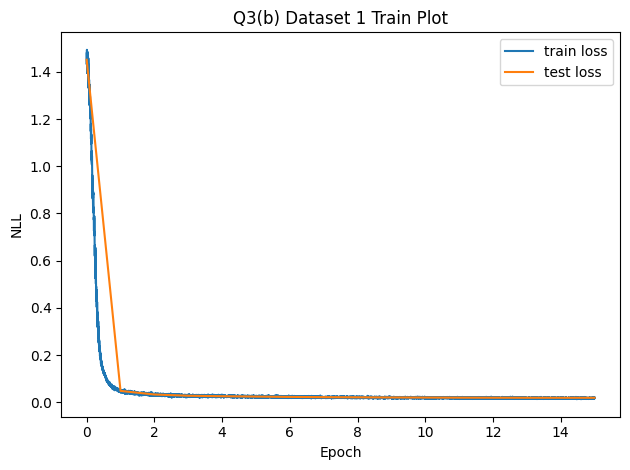

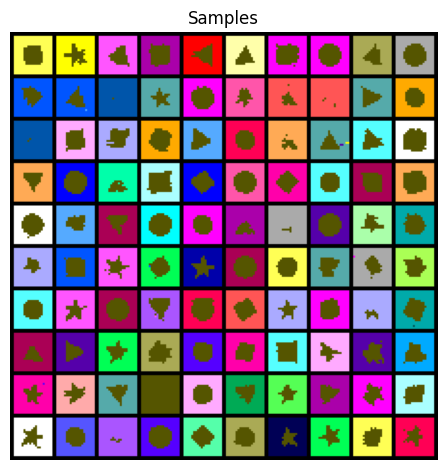

In [ ]:
q3ab_save_results(1, 'b', q3_b)

In [ ]:
q3ab_save_results(2, 'b', q3_b)

Dataset ID: 2
Image shape: (28, 28, 3)
Vocabulary size: 64
BOS token: 64
Sequence length: 784
Device: cuda
Train tokens shape: torch.Size([60000, 784])
Test tokens shape: torch.Size([10000, 784])


KeyboardInterrupt: 

## Part (c) K, V Caching for Improved Inference
You may have noticed that generation from the transformer is quite slow. Part of this is just due to the autoregressive nature. However, another part is due to some computational inefficiency. At each forward pass of the model, we are performing repeat computation of the past sequence. Specifically, we can cache the key and values at the multi attention layer to more quickly predict at each step.

In self-attention, a sequence is processed by generating three vectors for each element in the sequence: a Query (Q), a Key (K), and a Value (V). These vectors are then used to compute attention scores and subsequently the output of the attention layer.
Mathematically, this can be represented as:
 * For each index $i$, compute $Q_i$, $K_i$, $V_i$ for the current element
 * Retrieve $K_{<i}$ and $V_{<i}$ from the cache (where $<i$ denotes all indices before the current one)
 * Compute the attention output using $Q_i$, $[K_{<i}, K_i]$, $[V_{<i}, V_i]$


Next implement caching for your transformer to make inference more efficient by modifying your self attention. Use caching for inference in the future problems for faster generation! (Note caching is only used during inference). You will use the same dataset as in part B, dataset 2 of this question (colored mnist). No training is required in this section, feel free to reuse the model you trained in part B, dataset 2.

**You will provide these deliverables**

1. Over the course of inference, measure the time for the forward pass over the total sequence length with and without caching.
3. 100 samples from the final trained model using the caching inference pipeline.



In [ ]:
def q3_c(train_data, test_data, image_shape, dset_id):
  """
  train_data: A (n_train, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  test_data: A (n_test, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  image_shape: (H, W, C), height, width, and # of channels of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# sampling steps,) numpy array of time per sampling iteration, without caching
  - a (# sampling steps,) numpy array of time per sampling iteration, with without caching
  - a numpy array of size (100, H, C, W) of samples with values in {0, 1, 2, 3} (sample generated without caching)
  - a numpy array of size (100, H, C, W) of samples with values in {0, 1, 2, 3} (sample generated with caching)
  """
  # understand, ignore this question
  return time_list_no_cache, time_list_with_cache, samples_no_cache, samples_with_cache

### Results

Once you've implemented `q3_c`, execute the cells below to visualize and save your results



In [ ]:
q3c_save_results(2, q3_c)

# Question 4: Causal Transformer: Tokenized Images

## Image Tokenization with Vector Quanization

## Part (a) Image Quantization

Above, we implemented iGPT, which autoregressivly predicts raw pixels. Transformers have quadratic complexity in the sequence length which prevents this naive approach from scaling well to large images.

The space of natural images often contains very correlated information. This suggests we can learn a reduced representation. VQVAE is a method that does just that, learning to map images to a more compact discrete set of tokens. We will cover this method in more detail in future lectures. The only thing you need to know now is that we can learn an encoder (and corresponding decoder), which can extract a discrete representation from an image.

If you are curious, checkout the VQVAE paper to learn more: https://arxiv.org/abs/1711.00937 (we will cover this in a future lecture though!)

In this part, we provide a pre-trained VQVAE model, which consists of:
 * encoder to tokenize the images
 * the decoder to recover the image
 * a token vocabulary of VQVAE_MODEL.n_embeddings

Below is the code for loading the VQ model. Note that VQVAE encoding process is lossy, so the decoded images will not be the exact same as the input. Some blurriness in the recovered image is to be expected. The docstrings of the relevant methods you will need for the VQVAE_MODEL are provided below for your convenience.

We will use 2 colored mnist datasets in this part. The first is the same dataset used in previous parts. The second, hads a colored digit on a differently colored background. We will call these datasets Colored MNIST and Colored MNIST v2. Note that the vqvae is trained per dataset.

**You will provide these deliverables**

1. Use the provided encoder model to quantize the images then inspect the recovered images by applying the decoder for each of the two datasets

In [ ]:
# @property
# def n_embeddings(self) -> int:
#     """The size of the token vocabulary"""
#
# def quantize(self, x: np.ndarray) -> np.ndarray:
#     """Quantize an image x.
#
#     Args:
#         x (np.ndarray, dtype=int): Image to quantize. shape=(batch_size, 28, 28, 3). Values in [0, 3].
#
#     Returns:
#         np.ndarray: Quantized image. shape=(batch_size, 7, 7). Values in [0, n_embeddings]
#     """
#
# def decode(self, z_index: np.ndarray) -> np.ndarray:
#     """Decode a quantized image.
#
#     Args:
#         z_index (np.ndarray, dtype=int): Quantized image. shape=(batch_size, 7, 7). Values in [0, n_embeddings].
#
#     Returns:
#         np.ndarray: Decoded image. shape=(batch_size, 28, 28, 3). Values in [0, 3].
#     """
#

In [ ]:
def q4_a(images, vqvae):
  """
  images: (B, H, W, C), the images to pass through the encoder and decoder of the vqvae
  vqvae: a vqvae model, trained on the relevant dataset

  Returns
  - a numpy array of size (2, H, W, C) of the decoded image
  """
  # Convert the input into a Numpy array
  images = np.asarray(images)

  # Check the input dimension
  assert images.ndim == 4
  assert images.shape[0] >= 2

  # Select the first two images
  images = images[:2].astype(np.int64, copy=False)

  # Check the image value range
  assert images.min() >= 0
  assert images.max() <= 3

  # Quantize the images into discrete token indices
  z_index = vqvae.quantize(images)

  # Decoder the quantized token indices into reconstructed images
  autoencoded_images = vqvae.decode(z_index)

  # Convert the output into a NumPy array
  autoencoded_images = np.asarray(autoencoded_images)

  # Check the reconstructed image shape
  assert autoencoded_images.shape == images.shape

  return autoencoded_images

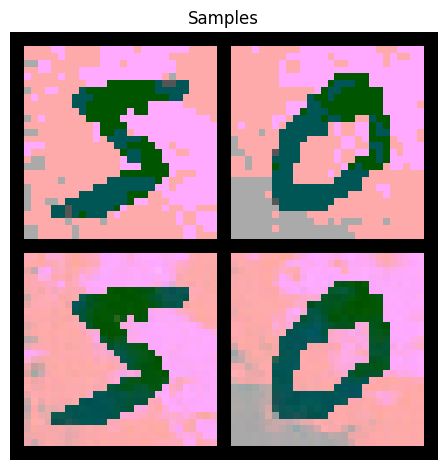

In [ ]:
q4a_save_results(1, q4_a)

In [ ]:
q4a_save_results(2, q4_a)

## Part (b) Autoregressive Transformer on Colored Shapes and MNIST with Vector Quantization

We can use the VQVAE to tokenize an image dataset. This will result in a much smaller sequence length than the approach we tried in Question 3(b). For this part, train a transformer on the dataset tokenized by the VQVAE.

This is a simplified version of the approach used in VQGAN [VQGAN](https://arxiv.org/abs/2012.09841) -> Section 3.2: Learning the Composition of Images with Transformers (Again, we will cover this in more detail in a future lecture!)

Update the following hyperparameters:
* layers: 4 (we can train a bigger transformer now since less memory is used per input!)
* 30 epochs

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. 100 samples from the final trained model

In [ ]:
import numpy as np
import torch

def tokenize_images(images, vqvae, batch_size=128):
    """
    Convert images into flattened VQ-VAE token sequences.

    Args:
        images: NumPy array with shape (N, H, W, C).
        vqvae: Pretrained VQ-VAE model for the corresponding dataset.
        batch_size: Number of images quantized in each batch.

    Returns:
        tokens: Long tensor with shape (N, L).
        token_grid_shape: Spatial shape of the quantized token grid.
    """

    # Convert input images to a Numpy array
    images = np.asarray(images)

    # Check input dimensions
    assert images.ndim == 4
    assert len(images) > 0
    assert images.min() >= 0
    assert images.max() <= 3

    token_batchs = []
    token_grid_shape = None

    # Process images in batches
    for start in range(0, len(images), batch_size):

      # Select the current image batch
      image_batch = images[start:start + batch_size].astype(np.int64, copy=False)

      # Quantize images using the pretrained VQ-VAE
      z_index = vqvae.quantize(image_batch)

      # Convert quantized indices to a NumPy array
      z_index = np.asarray(z_index)

      # Check quantized output dimensions
      assert z_index.ndim == 3
      assert z_index.shape[0] == len(image_batch)

      # Record the spatial shape of the token grid
      current_grid_shape = z_index.shape[1:]

      if token_grid_shape is None:
          token_grid_shape = current_grid_shape
      else:
          assert current_grid_shape == token_grid_shape

      # Flatten the spatial token grid
      z_index = z_index.reshape(
          len(image_batch),
          -1
      )

      # Convert token indices to PyTorch LongTensor
      z_index = torch.from_numpy(
          z_index.astype(np.int64, copy=True)
      )

      token_batches.append(z_index)

    # Concatenate all token batches
    tokens = torch.cat(
        token_batches,
        dim=0
    )

    # Check token vocabulary range
    vocab_size = int(vqvae.n_embeddings)

    assert tokens.min().item() >= 0
    assert tokens.max().item() < vocab_size

    return tokens, token_grid_shape





In [ ]:

import torch


def make_autoregressive_input(tokens, bos_token):
    """
    Construct autoregressive inputs and targets.

    Args:
        tokens: Token sequences with shape (B, L).
        bos_token: Beginning-of-sequence token ID.

    Returns:
        input_ids: Shifted input sequences with shape (B, L).
        targets: Original token sequences with shape (B, L).
    """

    # Convert tokens to LongTensor
    tokens = tokens.to(dtype=torch.long)

    # Get batch size and sequence length
    batch_size, seq_len = tokens.shape

    # Create BOS tokens
    bos = torch.full(
        (batch_size, 1),
        bos_token,
        dtype=torch.long,
        device=tokens.device
    )

    # Shift tokens to the right and prepend BOS
    input_ids = torch.cat(
        [bos, tokens[:, :-1]],
        dim=1
    )

    # The original tokens are the prediction targets
    targets = tokens

    return input_ids, targets


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import math


class CausalSelfAttentionVQ(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        max_seq_len=49
    ):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        # Query, Key and Value projections
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)

        # Output projection
        self.out_proj = nn.Linear(d_model, d_model)

        # Create the causal attention mask
        mask = torch.triu(
            torch.ones(
                max_seq_len,
                max_seq_len,
                dtype=torch.bool
            ),
            diagonal=1
        )

        self.register_buffer(
            "causal_mask",
            mask
        )

    def forward(self, x):
        """
        Compute causal multi-head self-attention.

        Args:
            x: Input tensor with shape (B, L, D).

        Returns:
            out: Attention output with shape (B, L, D).
        """

        B, L, D = x.shape

        assert L <= self.causal_mask.shape[0]

        # 1. Compute Q, K, V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # 2. Split into multiple attention heads
        q = q.view(
            B, L, self.num_heads, self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B, L, self.num_heads, self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B, L, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # 3. Calculate attention scores
        scores = torch.matmul(
            q,
            k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        # 4. Apply causal mask
        mask = self.causal_mask[:L, :L]

        scores = scores.masked_fill(
            mask,
            float("-inf")
        )

        # 5. Calculate attention weights
        attn_weights = torch.softmax(
            scores,
            dim=-1
        )

        # 6. Weighted sum of values
        out = torch.matmul(
            attn_weights,
            v
        )

        # 7. Merge attention heads
        out = out.transpose(1, 2).contiguous()

        out = out.view(B, L, D)

        # 8. Output projection
        out = self.out_proj(out)

        return out


In [ ]:

class TransformerBlockVQ(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        max_seq_len=49
    ):
        super().__init__()

        # First LayerNorm
        self.ln1 = nn.LayerNorm(d_model)

        # Causal Multi-Head Self-Attention
        self.attention = CausalSelfAttentionVQ(
            d_model=d_model,
            num_heads=num_heads,
            max_seq_len=max_seq_len
        )

        # Second LayerNorm
        self.ln2 = nn.LayerNorm(d_model)

        # Feed Forward Network
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model)
        )

    def forward(self, x):
        """
        Apply pre-normalization Transformer operations.

        Args:
            x: Input tensor with shape (B, L, D).

        Returns:
            x: Output tensor with shape (B, L, D).
        """

        # Apply attention with residual connection
        x = x + self.attention(
            self.ln1(x)
        )

        # Apply MLP with residual connection
        x = x + self.mlp(
            self.ln2(x)
        )

        return x


In [ ]:

class AutoregressiveTransformerVQ(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len=49,
        d_model=128,
        num_heads=4,
        num_layers=4
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.max_seq_len = max_seq_len
        self.d_model = d_model

        # Token embedding includes one additional BOS token
        self.token_embedding = nn.Embedding(
            num_embeddings=vocab_size + 1,
            embedding_dim=d_model
        )

        # Learnable positional embedding
        self.position_embedding = nn.Embedding(
            num_embeddings=max_seq_len,
            embedding_dim=d_model
        )

        # Transformer blocks
        self.blocks = nn.ModuleList([
            TransformerBlockVQ(
                d_model=d_model,
                num_heads=num_heads,
                max_seq_len=max_seq_len
            )
            for _ in range(num_layers)
        ])

        # Final LayerNorm
        self.ln_f = nn.LayerNorm(d_model)

        # Output head predicts normal VQ tokens only
        self.head = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, input_ids):
        """
        Perform autoregressive Transformer forward propagation.

        Args:
            input_ids: Input token IDs with shape (B, L).

        Returns:
            logits: Prediction logits with shape (B, L, vocab_size).
        """

        B, L = input_ids.shape

        assert L <= self.max_seq_len

        # 1. Token embedding
        token_emb = self.token_embedding(input_ids)

        # 2. Position embedding
        positions = torch.arange(
            L,
            device=input_ids.device
        )

        pos_emb = self.position_embedding(positions)

        # 3. Combine token and position embeddings
        x = token_emb + pos_emb

        # 4. Transformer blocks
        for block in self.blocks:
            x = block(x)

        # 5. Final LayerNorm
        x = self.ln_f(x)

        # 6. Predict VQ token logits
        logits = self.head(x)

        return logits


In [ ]:

def compute_vq_nll_per_dim(
    logits,
    targets,
    vocab_size,
    image_shape
):
    """
    Compute the average negative log-likelihood per image dimension.

    Args:
        logits: Prediction logits with shape (B, L, V).
        targets: Target token IDs with shape (B, L).
        vocab_size: Size of the VQ token vocabulary.
        image_shape: Original image shape (H, W, C).

    Returns:
        loss: Average NLL per image dimension in nats/dim.
    """

    # Get batch size and sequence length
    batch_size, seq_len = targets.shape

    # Check tensor dimensions
    assert logits.shape == (
        batch_size,
        seq_len,
        vocab_size
    )

    # Calculate the number of original image dimensions
    num_image_dims = math.prod(image_shape)

    # Calculate the number of image dimensions per token
    dims_per_token = num_image_dims / seq_len

    # Flatten batch and sequence dimensions
    logits = logits.reshape(
        -1,
        vocab_size
    )

    targets = targets.reshape(-1)

    # Calculate average cross entropy per token
    loss = F.cross_entropy(
        logits,
        targets,
        reduction="mean"
    )

    # Normalize by the number of image dimensions per token
    loss = loss / dims_per_token

    return loss


In [ ]:

@torch.no_grad()
def evaluate_vq_nll(
    model,
    test_loader,
    device,
    vocab_size,
    image_shape
):
    """
    Evaluate the average NLL per image dimension on the entire test set.

    Args:
        model: Autoregressive Transformer model.
        test_loader: DataLoader containing VQ token sequences.
        device: Computation device.
        vocab_size: Size of the VQ token vocabulary.
        image_shape: Original image shape (H, W, C).

    Returns:
        test_nll: Average test NLL in nats/dim.
    """

    # Set the model to evaluation mode
    model.eval()

    # Initialize total negative log-likelihood
    total_nll = 0.0

    # Initialize total number of image dimensions
    total_dims = 0

    # Calculate the number of original image dimensions
    num_image_dims = math.prod(image_shape)

    # Evaluate all test batches
    for (tokens,) in test_loader:

        # Move tokens to the selected device
        tokens = tokens.to(
            device=device,
            dtype=torch.long
        )

        # Construct autoregressive inputs and targets
        input_ids, targets = make_autoregressive_input(
            tokens,
            bos_token=vocab_size
        )

        # Forward propagation
        logits = model(input_ids)

        # Calculate the total NLL for this batch
        loss_sum = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            targets.reshape(-1),
            reduction="sum"
        )

        # Accumulate total NLL
        total_nll += loss_sum.item()

        # Accumulate the original image dimensions
        total_dims += targets.shape[0] * num_image_dims

    # Calculate average NLL per image dimension
    test_nll = total_nll / total_dims

    return test_nll


In [ ]:

from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import torch
import torch.nn.functional as F
import math


def train_vq_transformer(
    train_tokens,
    test_tokens,
    image_shape,
    vocab_size,
    num_epochs=30,
    batch_size=16,
    lr=1e-3,
    d_model=128,
    num_heads=4,
    num_layers=4
):
    """
    Train an autoregressive Transformer on VQ-VAE token sequences.

    Args:
        train_tokens: Training token sequences with shape (N_train, L).
        test_tokens: Test token sequences with shape (N_test, L).
        image_shape: Original image shape (H, W, C).
        vocab_size: Size of the VQ token vocabulary.
        num_epochs: Number of training epochs.
        batch_size: Training batch size.
        lr: Initial maximum learning rate.
        d_model: Transformer hidden dimension.
        num_heads: Number of attention heads.
        num_layers: Number of Transformer layers.

    Returns:
        model: Trained autoregressive Transformer.
        train_losses: Minibatch training NLL/dim values.
        test_losses: Initial and per-epoch test NLL/dim values.
    """

    # 1. Select computation device
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device:", device)

    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    # 2. Convert token sequences to CPU LongTensors
    train_tokens = torch.as_tensor(
        train_tokens,
        dtype=torch.long
    ).detach().cpu()

    test_tokens = torch.as_tensor(
        test_tokens,
        dtype=torch.long
    ).detach().cpu()

    # 3. Validate token sequences
    assert train_tokens.ndim == 2
    assert test_tokens.ndim == 2

    assert train_tokens.shape[0] > 0
    assert test_tokens.shape[0] > 0

    assert train_tokens.shape[1] == test_tokens.shape[1]

    assert train_tokens.min() >= 0
    assert train_tokens.max() < vocab_size

    assert test_tokens.min() >= 0
    assert test_tokens.max() < vocab_size

    # 4. Determine sequence length
    max_seq_len = train_tokens.shape[1]

    # 5. Construct DataLoaders
    train_loader = DataLoader(
        TensorDataset(train_tokens),
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(test_tokens),
        batch_size=batch_size,
        shuffle=False
    )

    # 6. Initialize Transformer
    model = AutoregressiveTransformerVQ(
        vocab_size=vocab_size,
        max_seq_len=max_seq_len,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    ).to(device)

    # 7. Initialize Adam optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # 8. Calculate total training steps
    total_steps = num_epochs * len(train_loader)

    # 9. Calculate warmup steps
    warmup_steps = min(
        1000,
        max(1, total_steps // 10)
    )

    # 10. Define learning rate schedule
    def lr_lambda(current_step):

        # Linear warmup
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)

        # Cosine decay
        progress = (
            current_step - warmup_steps
        ) / max(
            1,
            total_steps - warmup_steps
        )

        progress = min(
            max(progress, 0.0),
            1.0
        )

        return 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda
    )

    # 11. Evaluate before training
    test_losses = []

    initial_test_loss = evaluate_vq_nll(
        model=model,
        test_loader=test_loader,
        device=device,
        vocab_size=vocab_size,
        image_shape=image_shape
    )

    test_losses.append(initial_test_loss)

    print(
        f"Initial Test NLL/dim: {initial_test_loss:.6f}"
    )

    # 12. Initialize training loss records
    train_losses = []

    # 13. Training loop
    for epoch in range(num_epochs):

        model.train()

        epoch_losses = []

        for (tokens,) in train_loader:

            # Move tokens to the selected device
            tokens = tokens.to(
                device=device,
                dtype=torch.long
            )

            # Construct autoregressive inputs and targets
            input_ids, targets = make_autoregressive_input(
                tokens,
                bos_token=vocab_size
            )

            # Clear previous gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward propagation
            logits = model(input_ids)

            # Calculate NLL per image dimension
            loss = compute_vq_nll_per_dim(
                logits=logits,
                targets=targets,
                vocab_size=vocab_size,
                image_shape=image_shape
            )

            # Backpropagation
            loss.backward()

            # Update model parameters
            optimizer.step()

            # Update learning rate
            scheduler.step()

            # Record minibatch loss
            loss_value = loss.item()

            train_losses.append(loss_value)
            epoch_losses.append(loss_value)

        # 14. Evaluate after each epoch
        test_loss = evaluate_vq_nll(
            model=model,
            test_loader=test_loader,
            device=device,
            vocab_size=vocab_size,
            image_shape=image_shape
        )

        test_losses.append(test_loss)

        # 15. Print training progress
        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Train NLL/dim: {np.mean(epoch_losses):.6f} "
            f"Test NLL/dim: {test_loss:.6f} "
            f"LR: {optimizer.param_groups[0]['lr']:.8f}"
        )

    # 16. Convert loss records to NumPy arrays
    train_losses = np.asarray(
        train_losses,
        dtype=np.float32
    )

    test_losses = np.asarray(
        test_losses,
        dtype=np.float32
    )

    return model, train_losses, test_losses


In [ ]:

@torch.no_grad()
def generate_vq_token_grids(
    model,
    num_samples,
    token_grid_shape,
    sample_batch_size=8,
    temperature=1.0
):
    """
    Generate VQ token grids using autoregressive sampling.

    Args:
        model: Trained autoregressive Transformer.
        num_samples: Number of token grids to generate.
        token_grid_shape: Spatial shape of the VQ token grid.
        sample_batch_size: Number of samples generated per batch.
        temperature: Sampling temperature.

    Returns:
        token_grids: Generated token grids with shape
                     (num_samples, grid_height, grid_width).
    """

    # Set the model to evaluation mode
    model.eval()

    # Get the model device
    device = next(model.parameters()).device

    # Get the vocabulary size
    vocab_size = model.vocab_size

    # Define the BOS token
    bos_token = vocab_size

    # Calculate sequence length
    seq_len = math.prod(token_grid_shape)

    # Validate generation parameters
    assert num_samples > 0
    assert sample_batch_size > 0
    assert temperature > 0
    assert seq_len <= model.max_seq_len

    generated_batches = []

    # Generate samples in batches
    for start in range(0, num_samples, sample_batch_size):

        # Determine the current batch size
        current_batch = min(
            sample_batch_size,
            num_samples - start
        )

        # Allocate the generation buffer
        generated = torch.empty(
            current_batch,
            seq_len + 1,
            dtype=torch.long,
            device=device
        )

        # Place BOS at the beginning
        generated[:, 0] = bos_token

        # Generate tokens autoregressively
        for step in range(seq_len):

            # Get the previously generated prefix
            input_ids = generated[:, :step + 1]

            # Forward propagation
            logits = model(input_ids)

            # Get logits of the last position
            next_logits = logits[:, -1, :]

            # Apply temperature scaling
            next_logits = next_logits / temperature

            # Convert logits into probabilities
            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            # Sample the next token
            next_token = torch.multinomial(
                probs,
                num_samples=1
            )

            # Store the sampled token
            generated[:, step + 1] = next_token.squeeze(1)

        # Remove BOS and restore the spatial grid
        token_grids = generated[:, 1:].reshape(
            current_batch,
            *token_grid_shape
        )

        generated_batches.append(
            token_grids.cpu()
        )

    # Concatenate all generated batches
    token_grids = torch.cat(
        generated_batches,
        dim=0
    )

    return token_grids


In [ ]:

def decode_vq_token_grids(
    token_grids,
    vqvae,
    image_shape,
    batch_size=8
):
    """
    Decode generated VQ token grids into images.

    Args:
        token_grids: Token grids with shape (N, grid_height, grid_width).
        vqvae: Pretrained VQ-VAE model.
        image_shape: Expected output image shape (H, W, C).
        batch_size: Number of token grids decoded per batch.

    Returns:
        images: Reconstructed images with shape (N, H, W, C).
    """

    # Convert token grids to NumPy
    if isinstance(token_grids, torch.Tensor):
        token_grids = token_grids.detach().cpu().numpy()

    token_grids = np.asarray(token_grids)

    # Check input dimensions
    assert token_grids.ndim == 3
    assert len(token_grids) > 0

    decoded_batches = []

    # Decode token grids in batches
    for start in range(0, len(token_grids), batch_size):

        # Select the current batch
        token_batch = token_grids[
            start:start + batch_size
        ].astype(np.int64, copy=False)

        # Decode tokens using the pretrained VQ-VAE
        decoded = vqvae.decode(token_batch)

        # Convert the output to NumPy if necessary
        if isinstance(decoded, torch.Tensor):
            decoded = decoded.detach().cpu().numpy()

        decoded = np.asarray(decoded)

        # Check decoded image shape
        expected_shape = (
            len(token_batch),
            *image_shape
        )
        assert decoded.shape == expected_shape

        # Check for invalid numerical values
        assert np.isfinite(decoded).all()

        # Clip continuous outputs to the valid pixel range
        decoded = np.clip(decoded, 0.0, 3.0)

        # Quantize continuous values to discrete pixel levels
        decoded = np.rint(decoded)

        # Convert images to uint8
        decoded = decoded.astype(np.uint8, copy=False)

        # Verify the final pixel values
        assert decoded.min() >= 0
        assert decoded.max() <= 3
        assert np.isin(decoded, [0, 1, 2, 3]).all()

        decoded_batches.append(decoded)

    # Concatenate decoded image batches
    images = np.concatenate(
        decoded_batches,
        axis=0
    )

    return images

In [ ]:

@torch.no_grad()
def sample_vq_images(
    model,
    vqvae,
    num_samples,
    token_grid_shape,
    image_shape,
    sample_batch_size=8,
    temperature=1.0
):
    """
    Generate images using an autoregressive Transformer and VQ-VAE.

    Args:
        model: Trained autoregressive Transformer.
        vqvae: Pretrained VQ-VAE model.
        num_samples: Number of images to generate.
        token_grid_shape: Spatial shape of the VQ token grid.
        image_shape: Original image shape (H, W, C).
        sample_batch_size: Sampling batch size.
        temperature: Sampling temperature.

    Returns:
        samples: Generated images with shape (N, H, W, C).
    """

    # Generate autoregressive VQ token grids
    token_grids = generate_vq_token_grids(
        model=model,
        num_samples=num_samples,
        token_grid_shape=token_grid_shape,
        sample_batch_size=sample_batch_size,
        temperature=temperature
    )

    # Decode generated token grids into images
    samples = decode_vq_token_grids(
        token_grids=token_grids,
        vqvae=vqvae,
        image_shape=image_shape,
        batch_size=sample_batch_size
    )

    return samples


In [ ]:

def quantize_images_in_batches(
    images,
    vqvae,
    vocab_size,
    batch_size=128
):
    """
    Quantize images into VQ token grids in batches.

    Args:
        images: Images with shape (N, H, W, C).
        vqvae: Pretrained VQ-VAE model.
        vocab_size: Size of the VQ token vocabulary.
        batch_size: Number of images quantized per batch.

    Returns:
        token_grids: Quantized token grids with shape (N, h, w).
    """

    # Convert images to NumPy
    images = np.asarray(images)

    # Validate input images
    assert images.ndim == 4
    assert len(images) > 0
    assert images.min() >= 0
    assert images.max() <= 3

    token_batches = []

    # Quantize images in batches
    for start in range(0, len(images), batch_size):

        # Select the current image batch
        image_batch = images[
            start:start + batch_size
        ].astype(np.int64, copy=False)

        # Apply VQ-VAE quantization
        tokens = vqvae.quantize(image_batch)

        # Move tensor outputs to CPU if necessary
        if isinstance(tokens, torch.Tensor):
            tokens = tokens.detach().cpu().numpy()

        tokens = np.asarray(tokens)

        # Validate quantized token grids
        assert tokens.ndim == 3
        assert tokens.shape[0] == len(image_batch)

        # Ensure token IDs are integers
        assert np.allclose(tokens, np.round(tokens))

        tokens = np.round(tokens).astype(np.int64)

        # Validate token vocabulary range
        assert tokens.min() >= 0
        assert tokens.max() < vocab_size

        token_batches.append(tokens)

    # Concatenate all token batches
    token_grids = np.concatenate(
        token_batches,
        axis=0
    )

    return token_grids


In [ ]:

def q4_b(train_data, test_data, image_shape, dset_id, vqvae):
    """
    Train an autoregressive Transformer on VQ-VAE tokenized images.

    Args:
        train_data: Training images with shape (N_train, H, W, C).
        test_data: Test images with shape (N_test, H, W, C).
        image_shape: Original image shape (H, W, C).
        dset_id: Dataset identifier (1 or 2).
        vqvae: Pretrained VQ-VAE model for the corresponding dataset.

    Returns:
        train_losses: Minibatch training NLL/dim values.
        test_losses: Initial and per-epoch test NLL/dim values.
        samples: Generated images with shape (100, H, W, C).
    """

    # =====================================
    # 1. Validate input data
    # =====================================

    assert dset_id in (1, 2)

    train_data = np.asarray(train_data)
    test_data = np.asarray(test_data)

    image_shape = tuple(image_shape)

    assert train_data.ndim == 4
    assert test_data.ndim == 4

    assert train_data.shape[1:] == image_shape
    assert test_data.shape[1:] == image_shape

    assert len(train_data) > 0
    assert len(test_data) > 0

    # =====================================
    # 2. Define hyperparameters
    # =====================================

    num_epochs = 30
    batch_size = 16

    d_model = 128
    num_heads = 4
    num_layers = 4

    lr = 1e-3

    vocab_size = int(vqvae.n_embeddings)

    print("=====================================")
    print(f"Dataset ID: {dset_id}")
    print(f"Image shape: {image_shape}")
    print(f"Vocabulary size: {vocab_size}")
    print(f"Training epochs: {num_epochs}")
    print(f"Transformer layers: {num_layers}")
    print("=====================================")

    # =====================================
    # 3. Quantize training images
    # =====================================

    train_token_grids = quantize_images_in_batches(
        images=train_data,
        vqvae=vqvae,
        vocab_size=vocab_size,
        batch_size=128
    )

    # =====================================
    # 4. Quantize test images
    # =====================================

    test_token_grids = quantize_images_in_batches(
        images=test_data,
        vqvae=vqvae,
        vocab_size=vocab_size,
        batch_size=128
    )

    # =====================================
    # 5. Validate token grid shapes
    # =====================================

    token_grid_shape = tuple(
        train_token_grids.shape[1:]
    )

    assert len(token_grid_shape) == 2

    assert test_token_grids.shape[1:] == token_grid_shape

    seq_len = math.prod(token_grid_shape)

    print("=====================================")
    print("Tokenization completed")
    print("Train token grids:", train_token_grids.shape)
    print("Test token grids:", test_token_grids.shape)
    print("Token grid shape:", token_grid_shape)
    print("Sequence length:", seq_len)
    print("=====================================")

    # =====================================
    # 6. Flatten token grids into sequences
    # =====================================

    train_tokens = train_token_grids.reshape(
        len(train_token_grids),
        seq_len
    )

    test_tokens = test_token_grids.reshape(
        len(test_token_grids),
        seq_len
    )

    # =====================================
    # 7. Train autoregressive Transformer
    # =====================================

    model, train_losses, test_losses = train_vq_transformer(
        train_tokens=train_tokens,
        test_tokens=test_tokens,
        image_shape=image_shape,
        vocab_size=vocab_size,
        num_epochs=num_epochs,
        batch_size=batch_size,
        lr=lr,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    )

    # =====================================
    # 8. Generate 100 images
    # =====================================

    samples = sample_vq_images(
        model=model,
        vqvae=vqvae,
        num_samples=100,
        token_grid_shape=token_grid_shape,
        image_shape=image_shape,
        sample_batch_size=8,
        temperature=1.0
    )

    # =====================================
    # 9. Validate final results
    # =====================================

    assert train_losses.ndim == 1
    assert test_losses.shape == (num_epochs + 1,)

    assert samples.shape == (
        100,
        *image_shape
    )

    assert samples.dtype == np.uint8

    assert samples.min() >= 0
    assert samples.max() <= 3

    # =====================================
    # 10. Report final performance
    # =====================================

    print("=====================================")
    print("Part 4(b) completed")
    print("=====================================")

    print("Training iterations:", len(train_losses))
    print("Test evaluations:", len(test_losses))

    print(
        f"Final Test NLL/dim: {test_losses[-1]:.6f}"
    )

    print("Generated samples:", samples.shape)

    print("=====================================")

    return train_losses, test_losses, samples


### Results

Once you've implemented `q4_b`, execute the cells below to visualize and save your results



Dataset ID: 1
Image shape: (28, 28, 3)
Vocabulary size: 1024
Training epochs: 30
Transformer layers: 4
Tokenization completed
Train token grids: (60000, 7, 7)
Test token grids: (10000, 7, 7)
Token grid shape: (7, 7)
Sequence length: 49
Device: cuda
GPU: Tesla T4
Initial Test NLL/dim: 0.148034
Epoch [1/30] Train NLL/dim: 0.094000 Test NLL/dim: 0.081444 LR: 0.00099850
Epoch [2/30] Train NLL/dim: 0.077418 Test NLL/dim: 0.074180 LR: 0.00099164
Epoch [3/30] Train NLL/dim: 0.071784 Test NLL/dim: 0.070509 LR: 0.00097929
Epoch [4/30] Train NLL/dim: 0.068539 Test NLL/dim: 0.068336 LR: 0.00096160
Epoch [5/30] Train NLL/dim: 0.066423 Test NLL/dim: 0.067043 LR: 0.00093876
Epoch [6/30] Train NLL/dim: 0.064879 Test NLL/dim: 0.066002 LR: 0.00091103
Epoch [7/30] Train NLL/dim: 0.063632 Test NLL/dim: 0.065179 LR: 0.00087871
Epoch [8/30] Train NLL/dim: 0.062609 Test NLL/dim: 0.064582 LR: 0.00084217
Epoch [9/30] Train NLL/dim: 0.061732 Test NLL/dim: 0.063986 LR: 0.00080181
Epoch [10/30] Train NLL/dim: 0.

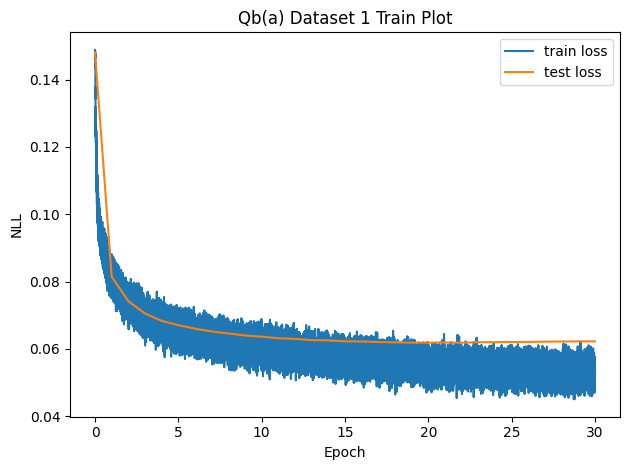

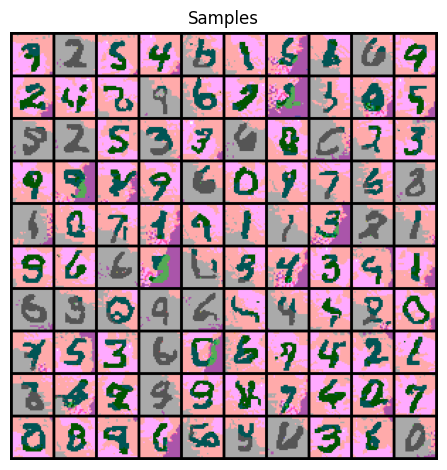

In [ ]:
q4b_save_results(1, q4_b)

In [ ]:
q4b_save_results(2, q4_b)

# Question 5: Causal Transformer: Text

Now lets consider text! You are probably already fimilar with autoregressive transformers for text, now more commonly known as Large Language Modesl (LLMs).
We will now implement a simplified version.

We will be detailing with a [small poetry dataset](https://huggingface.co/datasets/merve/poetry). See some of the data below.

In [ ]:
data = visualize_q5_data()

Sample 1
Conrad Aiken, When You Are Not Surprised from Collected Poems. Copyright  1953 by Conrad Aiken. Reprinted with the permission of Brandt & Hochman Literary Agents, Inc.
--------------------------------------------------------------------------------

Sample 2
"Not Ideas About the Thing but the Thing Itself", from The Collected Poems of Wallace Stevens, copyright 1954 by Wallace Stevens and renewed 1982 by Holly Stevens. Used by permission of Alfred A. Knopf, a division of Random House, Inc.
--------------------------------------------------------------------------------

Sample 3
PIERCE       &         CUDDIE
Cuddie, for shame hold up thy heavye head,
And let us cast with what delight to chace,
And weary thys long lingring Phoebus race.
Whilome thou wont the shepheards laddes to leade,
In rymes, in ridles, and in bydding base:
Now they in thee, and thou in sleepe art dead.

CUDDY
Piers, I have pyped erst so long with payne,
That all mine Oten reedes bene rent and wore:
And my p

## Part (a) Modeling Text
Train a transformer on the poetry dataset.

Data Preprocessing:
* We will use a simple method to tokenize the data. We will convert each unique character into a token. (Current LLMs use more sophisticated tokenizers, most commonly, [byte-pair encoding](https://huggingface.co/learn/nlp-course/chapter6/5?fw=pt))
* Previously we have leveraged a **\<bos\>** as part of the model, just like iGPT. For text, we may not always sample a sequence that starts at the beginning. Instead, we will add the **\<bos\>** token to the beginning of every sequence in the dataset, and remove the **\<bos\>** token from the model.
* Another problem is that the model must know when to stop sampling. This is done by appending an **\<eos\>**, or end of sequence token at the end of every sequence in the dataset.
* We can now convert the sequence into subsequences of size context_length, for training!

We recommend the following hyperparameters:
* Sequence length: 128
* 5 epochs

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. Provide **5 unconditional samples** of **128 characters** showcasing the model text generation capabilities (text samples should stop after **\<eos\>**. Text after **\<eos\>** can be removed in post processing)

In [ ]:
import torch.utils.data as data
def q5_a(train_text, test_text):
  """
  train_text: list[str] Train text sequences.
  test_text: list[str] Test text sequences.

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a list of 5 (str), 5 generated samples from the model.
  """
  return train_losses, test_losses, text_samples

### Results

Once you've implemented `q5_a`, execute the cells below to visualize and save your results



In [ ]:
q5a_save_results(q5_a)

# Question 6: Causal Transformer: Multimodal

So far, we have been dealing only with autoregressive generation of a single modality. Now we will train a model that operates on multiple modalities!

We will use the text labeled colored MNIST dataset, which has a text description of the MNIST image. Run the cell below to visualize the data along with the text annotation. This is the Colored MNIST v2 dataset, which also comes with these text labels.

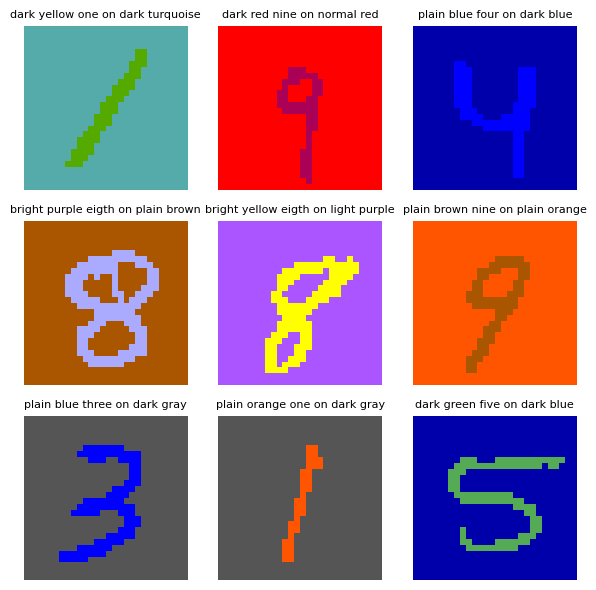

In [ ]:
visualize_q6_data()

## Part (a) Multimodal Text and Image Generation
Implement and train an autoregressive (AR) model capable of handling both text and image data. The model should be designed to process sequences composed of concatenated text and image tokens in both orders (text followed by images and images followed by text). Additionally, the model should be capable of generating unconditional text and image samples.

Data Preprocessing:
* Text Tokens: Map each unique word in the text data to a unique token. (Note that all text descriptions contain the exact same amount of words. This simplifies text processing, as you won't have to deal with sequences of different lengths as in Question 5)
* Image Tokens: Quantize the image data into tokens using the VQVAE tokenizer from Problem 4.
* In this problem, we have 2 modalities. Introduce an **\<end of text\>** token and an **\<end of image\>** token. After seeing such a token, the model should switch to sampling the next modality.
* Formulate batches as sequences of concat([**\<end of image\>**, text_tokens, **\<end of text\>**, image_tokens]) and concat([**\<end of text\>**, image_tokens, **\<end of image\>**, text_tokens]). With a 50/50 split between each ordering.

Inference:
* During inference, we cannot mix modality tokens. During sampling we can restrict the logits to only be within the relevant modality.
* After **\<end of image\>**, only allow the model to sample text tokens (including **\<end of text\>**)
* After **\<end of text\>**, only allow the model to sample image tokens (including **\<end of image\>**)
* At the very start (conditioned on the **\<bos\>** token, only allow the model to sample one of (**\<end of image\>** or **\<end of text\>**))
* As the model may not always correctly sample the **\<end of image\>** token before the image ends, you may add a rule to force the model to always sample the correct number of image tokens (49 tokens).

You can use the same hyperparameters as in 4(b) (but of course, feel free to tune your model to achieve better performance)

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. 9 conditional samples based on provided text.
4. 9 conditional samples based on provided images.
5. 9 unconditional samples showcasing the model's capability in generating standalone text and images.

In [5]:

import numpy as np


def tokenize_words(text):
    """
    Split a text description into word tokens.

    Args:
        text: Input text string.

    Returns:
        words: List of word tokens.
    """

    return text.strip().split()


def build_text_vocabulary(train_texts):
    """
    Build a word-level vocabulary from training texts.

    Args:
        train_texts: List of training text descriptions.

    Returns:
        word_to_id: Dictionary mapping words to token IDs.
        id_to_word: List mapping token IDs back to words.
    """

    # Reserve ID 0 for unknown words
    word_to_id = {
        "<unk>": 0
    }

    # Add unique words in order of appearance
    for text in train_texts:

        words = tokenize_words(text)

        for word in words:

            if word not in word_to_id:

                word_to_id[word] = len(word_to_id)

    # Build reverse vocabulary
    id_to_word = [
        None
    ] * len(word_to_id)

    for word, token_id in word_to_id.items():

        id_to_word[token_id] = word

    return word_to_id, id_to_word


In [6]:

def encode_texts(texts, word_to_id):
    """
    Convert text descriptions into word-level token IDs.

    Args:
        texts: List of text descriptions.
        word_to_id: Word-to-token-ID dictionary.

    Returns:
        token_ids: Integer array with shape (N, T).
    """

    # Get the unknown token ID
    unk_id = word_to_id["<unk>"]

    encoded_texts = []

    # Encode each text description
    for text in texts:

        words = tokenize_words(text)

        token_ids = [
            word_to_id.get(word, unk_id)
            for word in words
        ]

        encoded_texts.append(token_ids)

    # Convert encoded sequences to NumPy
    token_ids = np.asarray(
        encoded_texts,
        dtype=np.int64
    )

    # Check that all sequences have the same length
    assert token_ids.ndim == 2

    assert token_ids.shape[1] > 0

    return token_ids


In [7]:

import numpy as np
import torch


def quantize_images_in_batches(
    images,
    vqvae,
    batch_size=128
):
    """
    Quantize images into discrete VQ token sequences in batches.

    Args:
        images: Input images with shape (N, H, W, C).
        vqvae: Pretrained VQ-VAE model.
        batch_size: Number of images processed per batch.

    Returns:
        token_sequences: Quantized image tokens with shape (N, L).
        token_grid_shape: Spatial shape of the quantized token grids.
    """

    # Convert images to NumPy
    images = np.asarray(images)

    # Validate input dimensions
    assert images.ndim == 4
    assert len(images) > 0
    assert batch_size > 0

    # Validate image values
    assert np.issubdtype(images.dtype, np.integer)
    assert images.min() >= 0
    assert images.max() <= 3

    # Get the VQ-VAE vocabulary size
    vocab_size = int(vqvae.n_embeddings)

    assert vocab_size > 0

    token_batches = []

    token_grid_shape = None

    # Process images in batches
    for start in range(0, len(images), batch_size):

        # Select the current image batch
        image_batch = images[
            start:start + batch_size
        ].astype(np.int64, copy=False)

        # Quantize images using the pretrained VQ-VAE
        tokens = vqvae.quantize(image_batch)

        # Move tensor outputs to CPU if necessary
        if isinstance(tokens, torch.Tensor):
            tokens = tokens.detach().cpu().numpy()

        tokens = np.asarray(tokens)

        # Validate token dimensions
        assert tokens.ndim == 3

        assert tokens.shape[0] == len(image_batch)

        # Validate token values
        assert np.isfinite(tokens).all()

        assert np.all(tokens == np.round(tokens))

        # Convert token IDs to integers
        tokens = tokens.astype(np.int64, copy=False)

        # Validate vocabulary range
        assert tokens.min() >= 0
        assert tokens.max() < vocab_size

        # Record the spatial token grid shape
        current_grid_shape = tuple(tokens.shape[1:])

        if token_grid_shape is None:
            token_grid_shape = current_grid_shape

        else:
            assert current_grid_shape == token_grid_shape

        token_batches.append(tokens)

    # Concatenate all token batches
    token_grids = np.concatenate(
        token_batches,
        axis=0
    )

    # Flatten token grids into sequences
    token_sequences = token_grids.reshape(
        len(images),
        -1
    )

    return token_sequences, token_grid_shape


In [8]:

def prepare_image_tokens(
    train_images,
    test_images,
    vqvae,
    batch_size=128
):
    """
    Prepare VQ-VAE image tokens for training and testing.

    Args:
        train_images: Training images with shape (N_train, H, W, C).
        test_images: Test images with shape (N_test, H, W, C).
        vqvae: Pretrained VQ-VAE model.
        batch_size: Number of images processed per batch.

    Returns:
        train_image_tokens: Training tokens with shape (N_train, L).
        test_image_tokens: Test tokens with shape (N_test, L).
        token_grid_shape: Spatial shape of the VQ token grids.
        vocab_size: Size of the image token vocabulary.
    """

    # Convert inputs to NumPy
    train_images = np.asarray(train_images)
    test_images = np.asarray(test_images)

    # Validate image shapes
    assert train_images.ndim == 4
    assert test_images.ndim == 4

    assert train_images.shape[1:] == test_images.shape[1:]

    # Get image vocabulary size
    vocab_size = int(vqvae.n_embeddings)

    # Quantize training images
    train_image_tokens, train_grid_shape = (
        quantize_images_in_batches(
            images=train_images,
            vqvae=vqvae,
            batch_size=batch_size
        )
    )

    # Quantize test images
    test_image_tokens, test_grid_shape = (
        quantize_images_in_batches(
            images=test_images,
            vqvae=vqvae,
            batch_size=batch_size
        )
    )

    # Ensure consistent token grid shapes
    assert train_grid_shape == test_grid_shape

    # Ensure consistent sequence lengths
    assert train_image_tokens.shape[1] == test_image_tokens.shape[1]

    # Validate token vocabulary range
    assert train_image_tokens.min() >= 0
    assert train_image_tokens.max() < vocab_size

    assert test_image_tokens.min() >= 0
    assert test_image_tokens.max() < vocab_size

    print("=====================================")
    print("Image Tokenization Completed")
    print("=====================================")

    print("Train image tokens:", train_image_tokens.shape)
    print("Test image tokens:", test_image_tokens.shape)

    print("Token grid shape:", train_grid_shape)
    print("Sequence length:", train_image_tokens.shape[1])

    print("Image vocabulary size:", vocab_size)

    print("=====================================")

    return (
        train_image_tokens,
        test_image_tokens,
        train_grid_shape,
        vocab_size
    )


In [9]:

def build_unified_vocabulary(
    word_to_id,
    image_vocab_size
):
    """
    Build a unified vocabulary for text, image, and special tokens.

    Args:
        word_to_id: Dictionary mapping words to text token IDs.
        image_vocab_size: Number of entries in the VQ-VAE codebook.

    Returns:
        vocab_info: Dictionary containing vocabulary sizes,
                    token offsets, and special token IDs.
    """

    # Validate vocabulary size
    assert len(word_to_id) > 0
    assert image_vocab_size > 0

    # Validate that text token IDs are unique and contiguous
    text_ids = sorted(word_to_id.values())

    assert text_ids == list(range(len(word_to_id)))

    # Check reserved special token names
    reserved_tokens = {
        "<bos>",
        "<eoi>",
        "<eot>"
    }

    assert not reserved_tokens.intersection(word_to_id.keys())

    # Calculate text vocabulary size
    text_vocab_size = len(word_to_id)

    # Assign the image token offset
    image_offset = text_vocab_size

    # Assign special token IDs
    bos_id = text_vocab_size + image_vocab_size

    eoi_id = bos_id + 1

    eot_id = bos_id + 2

    # Calculate total vocabulary size
    total_vocab_size = text_vocab_size + image_vocab_size + 3

    # Build reverse unified vocabulary
    id_to_token = [None] * total_vocab_size

    # Add text tokens
    for word, token_id in word_to_id.items():

        id_to_token[token_id] = word

    # Add image token labels
    for image_id in range(image_vocab_size):

        global_id = image_offset + image_id

        id_to_token[global_id] = f"<image_{image_id}>"

    # Add special tokens
    id_to_token[bos_id] = "<bos>"
    id_to_token[eoi_id] = "<eoi>"
    id_to_token[eot_id] = "<eot>"

    # Validate the complete vocabulary
    assert all(token is not None for token in id_to_token)

    # Store vocabulary information
    vocab_info = {
        "text_vocab_size": text_vocab_size,
        "image_vocab_size": image_vocab_size,
        "image_offset": image_offset,
        "bos_id": bos_id,
        "eoi_id": eoi_id,
        "eot_id": eot_id,
        "total_vocab_size": total_vocab_size,
        "id_to_token": id_to_token
    }

    return vocab_info


In [10]:

def convert_image_tokens_to_global_ids(
    image_tokens,
    vocab_info
):
    """
    Convert local VQ-VAE token IDs into global vocabulary IDs.

    Args:
        image_tokens: Local image token IDs with shape (N, L).
        vocab_info: Unified vocabulary information.

    Returns:
        global_image_tokens: Global image token IDs with shape (N, L).
    """

    # Convert input to NumPy
    image_tokens = np.asarray(image_tokens)

    # Validate input dimensions
    assert image_tokens.ndim == 2

    assert image_tokens.shape[0] > 0
    assert image_tokens.shape[1] > 0

    # Validate integer token IDs
    assert np.issubdtype(
        image_tokens.dtype,
        np.integer
    )

    # Get vocabulary information
    image_vocab_size = vocab_info["image_vocab_size"]

    image_offset = vocab_info["image_offset"]

    # Validate local image token range
    assert image_tokens.min() >= 0

    assert image_tokens.max() < image_vocab_size

    # Convert local IDs to global IDs
    global_image_tokens = (
        image_tokens.astype(np.int64, copy=False)
        + image_offset
    )

    # Validate global image token range
    assert global_image_tokens.min() >= image_offset

    assert global_image_tokens.max() < (
        image_offset + image_vocab_size
    )

    return global_image_tokens


In [11]:

def build_multimodal_sequences(
    text_tokens,
    image_tokens,
    vocab_info,
    seed=42
):
    """
    Build multimodal sequences with two different modality orders.

    Args:
        text_tokens: Text token IDs with shape (N, T).
        image_tokens: Global image token IDs with shape (N, L).
        vocab_info: Unified vocabulary information.
        seed: Random seed for sequence order assignment.

    Returns:
        sequences: Multimodal sequences with shape (N, T + L + 3).
        order_labels: Sequence order labels (0 for text-first, 1 for image-first).
    """

    # Convert inputs to NumPy arrays
    text_tokens = np.asarray(text_tokens)
    image_tokens = np.asarray(image_tokens)

    # Validate input dimensions
    assert text_tokens.ndim == 2
    assert image_tokens.ndim == 2

    assert len(text_tokens) > 0
    assert len(text_tokens) == len(image_tokens)

    # Validate integer token IDs
    assert np.issubdtype(text_tokens.dtype, np.integer)
    assert np.issubdtype(image_tokens.dtype, np.integer)

    # Get sequence dimensions
    num_samples, text_len = text_tokens.shape
    image_len = image_tokens.shape[1]

    # Get vocabulary information
    text_vocab_size = vocab_info["text_vocab_size"]
    image_offset = vocab_info["image_offset"]
    image_vocab_size = vocab_info["image_vocab_size"]

    bos_id = vocab_info["bos_id"]
    eoi_id = vocab_info["eoi_id"]
    eot_id = vocab_info["eot_id"]

    total_vocab_size = vocab_info["total_vocab_size"]

    # Validate text token IDs
    assert text_tokens.min() >= 0
    assert text_tokens.max() < text_vocab_size

    # Validate image token IDs
    assert image_tokens.min() >= image_offset
    assert image_tokens.max() < image_offset + image_vocab_size

    # Validate special token IDs
    assert len({bos_id, eoi_id, eot_id}) == 3

    assert max(bos_id, eoi_id, eot_id) < total_vocab_size

    # Calculate the total sequence length
    seq_len = 1 + 1 + text_len + 1 + image_len

    # Preallocate sequence storage
    sequences = np.empty(
        (num_samples, seq_len),
        dtype=np.int64
    )

    # Store sequence order labels
    order_labels = np.empty(
        num_samples,
        dtype=np.int64
    )

    # Randomly assign sequence orders
    rng = np.random.default_rng(seed)

    shuffled_indices = rng.permutation(num_samples)

    # Split samples into two groups
    num_text_first = num_samples // 2

    text_first_indices = shuffled_indices[:num_text_first]

    image_first_indices = shuffled_indices[num_text_first:]

    # =====================================
    # 1. Text followed by Image
    # =====================================

    for idx in text_first_indices:

        sequences[idx, 0] = bos_id

        sequences[idx, 1] = eoi_id

        sequences[idx, 2:2 + text_len] = text_tokens[idx]

        eot_position = 2 + text_len

        sequences[idx, eot_position] = eot_id

        sequences[idx, eot_position + 1:] = image_tokens[idx]

        order_labels[idx] = 0

    # =====================================
    # 2. Image followed by Text
    # =====================================

    for idx in image_first_indices:

        sequences[idx, 0] = bos_id

        sequences[idx, 1] = eot_id

        image_start = 2

        image_end = image_start + image_len

        sequences[idx, image_start:image_end] = image_tokens[idx]

        sequences[idx, image_end] = eoi_id

        sequences[idx, image_end + 1:] = text_tokens[idx]

        order_labels[idx] = 1

    # Shuffle the completed sequences
    final_indices = rng.permutation(num_samples)

    sequences = sequences[final_indices]

    order_labels = order_labels[final_indices]

    # Validate final sequence shape
    assert sequences.shape == (
        num_samples,
        seq_len
    )

    # Validate all token IDs
    assert sequences.min() >= 0
    assert sequences.max() < total_vocab_size

    # Validate the 50/50 distribution
    assert np.sum(order_labels == 0) == num_text_first

    assert np.sum(order_labels == 1) == num_samples - num_text_first

    print("=====================================")
    print("Multimodal Sequence Construction")
    print("=====================================")

    print("Number of samples:", num_samples)

    print("Text sequence length:", text_len)

    print("Image sequence length:", image_len)

    print("Total sequence length:", seq_len)

    print("Text -> Image:", np.sum(order_labels == 0))

    print("Image -> Text:", np.sum(order_labels == 1))

    print("Sequence shape:", sequences.shape)

    print("=====================================")

    return sequences, order_labels


In [12]:

def make_multimodal_lm_inputs(sequences):
    """
    Construct autoregressive inputs and targets from multimodal sequences.

    Args:
        sequences: Multimodal token sequences with shape (N, L).

    Returns:
        input_ids: Input token IDs with shape (N, L - 1).
        targets: Target token IDs with shape (N, L - 1).
    """

    # Convert sequences to NumPy
    sequences = np.asarray(sequences)

    # Validate input dimensions
    assert sequences.ndim == 2

    assert sequences.shape[0] > 0
    assert sequences.shape[1] >= 2

    # Validate integer token IDs
    assert np.issubdtype(
        sequences.dtype,
        np.integer
    )

    # Shift sequences to construct inputs and targets
    input_ids = sequences[:, :-1]

    targets = sequences[:, 1:]

    # Validate output shapes
    assert input_ids.shape == targets.shape

    return input_ids, targets


In [14]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import math


class MultimodalCausalSelfAttention(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        max_seq_len=512
    ):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.max_seq_len = max_seq_len

        # Query, Key, and Value projections
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)

        # Output projection
        self.out_proj = nn.Linear(d_model, d_model)

        # Create the causal attention mask
        causal_mask = torch.triu(
            torch.ones(
                max_seq_len,
                max_seq_len,
                dtype=torch.bool
            ),
            diagonal=1
        )

        self.register_buffer(
            "causal_mask",
            causal_mask
        )

    def forward(self, x):

        B, L, D = x.shape

        assert L <= self.max_seq_len

        # Compute Q, K, and V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # Split the embedding dimension into multiple heads
        q = q.view(
            B, L, self.num_heads, self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B, L, self.num_heads, self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B, L, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # Compute attention scores
        scores = torch.matmul(
            q,
            k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        # Apply causal masking
        mask = self.causal_mask[:L, :L]

        scores = scores.masked_fill(
            mask,
            float("-inf")
        )

        # Compute attention probabilities
        attn_weights = torch.softmax(
            scores,
            dim=-1
        )

        # Compute attention output
        out = torch.matmul(
            attn_weights,
            v
        )

        # Merge attention heads
        out = out.transpose(1, 2).contiguous()

        out = out.view(
            B,
            L,
            self.d_model
        )

        # Apply output projection
        out = self.out_proj(out)

        return out


In [15]:

class MultimodalTransformerBlock(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        max_seq_len=512
    ):
        super().__init__()

        # First LayerNorm
        self.ln1 = nn.LayerNorm(d_model)

        # Causal Multi-Head Self-Attention
        self.attention = MultimodalCausalSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            max_seq_len=max_seq_len
        )

        # Second LayerNorm
        self.ln2 = nn.LayerNorm(d_model)

        # Feed-Forward Network
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model)
        )

    def forward(self, x):

        # Apply pre-normalized attention with residual connection
        x = x + self.attention(self.ln1(x))

        # Apply pre-normalized MLP with residual connection
        x = x + self.mlp(self.ln2(x))

        return x


In [16]:

class MultimodalARTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        d_model=128,
        num_heads=4,
        num_layers=4
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.max_seq_len = max_seq_len
        self.d_model = d_model

        # Shared token embedding
        self.token_embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=d_model
        )

        # Learned positional embedding
        self.position_embedding = nn.Embedding(
            num_embeddings=max_seq_len,
            embedding_dim=d_model
        )

        # Transformer blocks
        self.blocks = nn.ModuleList([
            MultimodalTransformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                max_seq_len=max_seq_len
            )
            for _ in range(num_layers)
        ])

        # Final LayerNorm
        self.ln_f = nn.LayerNorm(d_model)

        # Language modeling head
        self.lm_head = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, input_ids):

        B, L = input_ids.shape

        assert L <= self.max_seq_len

        # Token embeddings
        token_emb = self.token_embedding(input_ids)

        # Position embeddings
        positions = torch.arange(
            L,
            device=input_ids.device
        )

        pos_emb = self.position_embedding(positions)

        # Combine token and position embeddings
        x = token_emb + pos_emb

        # Apply Transformer blocks
        for block in self.blocks:
            x = block(x)

        # Final normalization
        x = self.ln_f(x)

        # Predict logits over the unified vocabulary
        logits = self.lm_head(x)

        return logits


In [17]:

from torch.utils.data import DataLoader, TensorDataset


def create_multimodal_dataloaders(
    train_inputs,
    train_targets,
    train_order_labels,
    test_inputs,
    test_targets,
    test_order_labels,
    batch_size=16
):
    """
    Create DataLoaders for multimodal autoregressive training and evaluation.

    Args:
        train_inputs: Training input sequences.
        train_targets: Training target sequences.
        train_order_labels: Training sequence order labels.
        test_inputs: Testing input sequences.
        test_targets: Testing target sequences.
        test_order_labels: Testing sequence order labels.
        batch_size: Number of sequences per minibatch.

    Returns:
        train_loader: Training DataLoader.
        test_loader: Testing DataLoader.
    """

    # Convert NumPy arrays to PyTorch tensors
    train_inputs = torch.as_tensor(
        train_inputs,
        dtype=torch.long
    )

    train_targets = torch.as_tensor(
        train_targets,
        dtype=torch.long
    )

    train_order_labels = torch.as_tensor(
        train_order_labels,
        dtype=torch.long
    )

    test_inputs = torch.as_tensor(
        test_inputs,
        dtype=torch.long
    )

    test_targets = torch.as_tensor(
        test_targets,
        dtype=torch.long
    )

    test_order_labels = torch.as_tensor(
        test_order_labels,
        dtype=torch.long
    )

    # Validate training data
    assert train_inputs.shape == train_targets.shape

    assert train_inputs.shape[0] == len(train_order_labels)

    # Validate testing data
    assert test_inputs.shape == test_targets.shape

    assert test_inputs.shape[0] == len(test_order_labels)

    # Validate sequence lengths
    assert train_inputs.shape[1] == test_inputs.shape[1]

    # Validate order labels
    assert torch.all(
        (train_order_labels == 0) |
        (train_order_labels == 1)
    )

    assert torch.all(
        (test_order_labels == 0) |
        (test_order_labels == 1)
    )

    # Build training dataset
    train_dataset = TensorDataset(
        train_inputs,
        train_targets,
        train_order_labels
    )

    # Build testing dataset
    test_dataset = TensorDataset(
        test_inputs,
        test_targets,
        test_order_labels
    )

    # Configure memory transfer
    pin_memory = torch.cuda.is_available()

    # Build training DataLoader
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=pin_memory
    )

    # Build testing DataLoader
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=pin_memory
    )

    print("=====================================")
    print("DataLoader Preparation")
    print("=====================================")

    print("Training samples:", len(train_dataset))

    print("Testing samples:", len(test_dataset))

    print("Batch size:", batch_size)

    print("Training minibatches:", len(train_loader))

    print("Testing minibatches:", len(test_loader))

    print("=====================================")

    return train_loader, test_loader


In [19]:

@torch.no_grad()
def evaluate_multimodal_nll(
    model,
    test_loader,
    device,
    vocab_info
):
    """
    Evaluate multimodal autoregressive NLL over the entire test dataset.

    Args:
        model: Trained multimodal autoregressive Transformer.
        test_loader: Testing DataLoader.
        device: CPU or CUDA device.
        vocab_info: Unified vocabulary information.

    Returns:
        metrics: Dictionary containing overall and category-specific NLL.
    """

    model.eval()

    # Get vocabulary information
    vocab_size = vocab_info["total_vocab_size"]

    text_vocab_size = vocab_info["text_vocab_size"]

    image_offset = vocab_info["image_offset"]

    image_vocab_size = vocab_info["image_vocab_size"]

    eoi_id = vocab_info["eoi_id"]

    eot_id = vocab_info["eot_id"]

    # Initialize total loss statistics
    total_loss = 0.0
    total_tokens = 0

    category_loss = {
        "text": 0.0,
        "image": 0.0,
        "special": 0.0
    }

    category_count = {
        "text": 0,
        "image": 0,
        "special": 0
    }

    order_loss = {
        "text_to_image": 0.0,
        "image_to_text": 0.0
    }

    order_count = {
        "text_to_image": 0,
        "image_to_text": 0
    }

    # Iterate over the entire test dataset
    for input_ids, targets, order_labels in test_loader:

        input_ids = input_ids.to(
            device,
            non_blocking=True
        )

        targets = targets.to(
            device,
            non_blocking=True
        )

        order_labels = order_labels.to(
            device,
            non_blocking=True
        )

        # Forward pass
        logits = model(input_ids)

        assert logits.shape[:2] == targets.shape

        assert logits.shape[-1] == vocab_size

        # Calculate unreduced token-level cross entropy
        token_losses = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            targets.reshape(-1),
            reduction="none"
        ).view_as(targets)

        # Accumulate overall NLL
        total_loss += token_losses.sum().item()

        total_tokens += targets.numel()

        # Identify token categories
        text_mask = targets < text_vocab_size

        image_mask = (
            (targets >= image_offset) &
            (targets < image_offset + image_vocab_size)
        )

        special_mask = (
            (targets == eoi_id) |
            (targets == eot_id)
        )

        # Accumulate category-specific NLL
        masks = {
            "text": text_mask,
            "image": image_mask,
            "special": special_mask
        }

        for name, mask in masks.items():

            category_loss[name] += (
                token_losses[mask].sum().item()
            )

            category_count[name] += mask.sum().item()

        # Separate the two sequence ordering directions
        for order_id, name in [
            (0, "text_to_image"),
            (1, "image_to_text")
        ]:

            sample_mask = (
                order_labels == order_id
            ).unsqueeze(1)

            token_mask = sample_mask.expand_as(targets)

            order_loss[name] += (
                token_losses[token_mask].sum().item()
            )

            order_count[name] += token_mask.sum().item()

    # Calculate average NLL safely
    def safe_average(loss_sum, count):

        if count == 0:
            return float("nan")

        return loss_sum / count

    # Build evaluation metrics
    metrics = {
        "overall": safe_average(
            total_loss,
            total_tokens
        )
    }

    for name in category_loss:

        metrics[name] = safe_average(
            category_loss[name],
            category_count[name]
        )

    for name in order_loss:

        metrics[name] = safe_average(
            order_loss[name],
            order_count[name]
        )

    return metrics


In [20]:

def train_multimodal_transformer(
    model,
    train_loader,
    test_loader,
    vocab_info,
    num_epochs=30,
    learning_rate=1e-3
):
    """
    Train a multimodal autoregressive Transformer.

    Args:
        model: Multimodal autoregressive Transformer.
        train_loader: Training DataLoader.
        test_loader: Testing DataLoader.
        vocab_info: Unified vocabulary information.
        num_epochs: Number of training epochs.
        learning_rate: Initial learning rate.

    Returns:
        model: Trained Transformer.
        train_losses: Training NLL recorded per minibatch.
        test_losses: Test NLL recorded before training and after each epoch.
        test_metrics_history: Detailed test metrics for each evaluation.
    """

    # Get the model device
    device = next(model.parameters()).device

    # Get the vocabulary size
    vocab_size = vocab_info["total_vocab_size"]

    assert model.vocab_size == vocab_size

    # Validate the model and training configuration
    assert len(train_loader) > 0
    assert len(test_loader) > 0

    # Initialize the optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    # Calculate the total number of optimization steps
    total_steps = num_epochs * len(train_loader)

    # Configure warmup steps
    warmup_steps = min(
        1000,
        max(1, total_steps // 10)
    )

    # Define the learning rate schedule
    def lr_lambda(current_step):

        # Linear warmup
        if current_step < warmup_steps:

            return float(current_step + 1) / warmup_steps

        # Cosine decay
        progress = (
            current_step - warmup_steps
        ) / max(
            1,
            total_steps - warmup_steps
        )

        progress = min(
            max(progress, 0.0),
            1.0
        )

        return 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    # Initialize the scheduler
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda
    )

    # Initialize training history
    train_losses = []

    test_losses = []

    test_metrics_history = []

    # =====================================
    # Initial evaluation
    # =====================================

    initial_metrics = evaluate_multimodal_nll(
        model=model,
        test_loader=test_loader,
        device=device,
        vocab_info=vocab_info
    )

    test_losses.append(
        initial_metrics["overall"]
    )

    test_metrics_history.append(
        initial_metrics
    )

    print("=====================================")
    print("Multimodal Transformer Training")
    print("=====================================")

    print("Device:", device)

    print("Vocabulary size:", vocab_size)

    print("Training epochs:", num_epochs)

    print("Training minibatches per epoch:", len(train_loader))

    print(
        f"Initial Test NLL: "
        f"{initial_metrics['overall']:.6f}"
    )

    print("=====================================")

    # =====================================
    # Training loop
    # =====================================

    for epoch in range(num_epochs):

        model.train()

        epoch_loss_sum = 0.0

        epoch_token_count = 0

        for input_ids, targets, order_labels in train_loader:

            # Move data to the model device
            input_ids = input_ids.to(
                device,
                non_blocking=True
            )

            targets = targets.to(
                device,
                non_blocking=True
            )

            # Clear previous gradients
            optimizer.zero_grad(
                set_to_none=True
            )

            # Forward pass
            logits = model(input_ids)

            # Calculate mean cross entropy
            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1),
                reduction="mean"
            )

            # Backward pass
            loss.backward()

            # Update model parameters
            optimizer.step()

            # Update learning rate
            scheduler.step()

            # Record minibatch loss
            train_losses.append(
                loss.item()
            )

            # Accumulate epoch statistics
            epoch_loss_sum += (
                loss.item() * targets.numel()
            )

            epoch_token_count += targets.numel()

        # Calculate epoch training NLL
        epoch_train_loss = (
            epoch_loss_sum / epoch_token_count
        )

        # =====================================
        # Evaluation after each epoch
        # =====================================

        test_metrics = evaluate_multimodal_nll(
            model=model,
            test_loader=test_loader,
            device=device,
            vocab_info=vocab_info
        )

        epoch_test_loss = test_metrics["overall"]

        test_losses.append(
            epoch_test_loss
        )

        test_metrics_history.append(
            test_metrics
        )

        # Get the current learning rate
        current_lr = optimizer.param_groups[0]["lr"]

        # Print epoch statistics
        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Train NLL: {epoch_train_loss:.6f} "
            f"Test NLL: {epoch_test_loss:.6f} "
            f"LR: {current_lr:.8f}"
        )

        print(
            f"    Text: {test_metrics['text']:.6f} | "
            f"Image: {test_metrics['image']:.6f} | "
            f"Special: {test_metrics['special']:.6f}"
        )

        print(
            f"    Text-first: {test_metrics['text_to_image']:.6f} | "
            f"Image-first: {test_metrics['image_to_text']:.6f}"
        )

    # Convert training history to NumPy arrays
    train_losses = np.asarray(
        train_losses,
        dtype=np.float64
    )

    test_losses = np.asarray(
        test_losses,
        dtype=np.float64
    )

    print("=====================================")
    print("Training Completed")
    print("=====================================")

    print(
        f"Final Test NLL: "
        f"{test_losses[-1]:.6f}"
    )

    print(
        "Total optimization steps:",
        len(train_losses)
    )

    print(
        "Number of test evaluations:",
        len(test_losses)
    )

    print("=====================================")

    return (
        model,
        train_losses,
        test_losses,
        test_metrics_history
    )


In [21]:

@torch.no_grad()
def sample_next_token(
    model,
    prefix,
    allowed_token_ids,
    temperature=1.0,
    top_k=None
):
    """
    Sample one token from a restricted vocabulary.

    Args:
        model: Trained autoregressive Transformer.
        prefix: Current token sequence with shape (1, L).
        allowed_token_ids: Token IDs allowed for sampling.
        temperature: Sampling temperature.
        top_k: Optional number of highest-scoring candidates.

    Returns:
        next_token: Sampled token with shape (1, 1).
    """

    model.eval()

    # Get the model device
    device = next(model.parameters()).device

    prefix = prefix.to(
        device=device,
        dtype=torch.long
    )

    assert prefix.ndim == 2
    assert prefix.shape[0] == 1

    assert prefix.shape[1] <= model.max_seq_len

    assert temperature >= 0

    # Convert allowed token IDs to a tensor
    allowed_ids = torch.as_tensor(
        allowed_token_ids,
        dtype=torch.long,
        device=device
    ).flatten()

    assert allowed_ids.numel() > 0

    # Forward pass
    logits = model(prefix)

    # Get the logits of the last position
    next_logits = logits[:, -1, :]

    # Restrict logits to allowed tokens
    candidate_logits = next_logits.index_select(
        dim=-1,
        index=allowed_ids
    )

    # Greedy decoding
    if temperature == 0:

        sampled_index = candidate_logits.argmax(
            dim=-1,
            keepdim=True
        )

    else:

        # Apply temperature
        candidate_logits = candidate_logits / temperature

        # Optional top-k filtering
        if top_k is not None:

            k = min(
                top_k,
                candidate_logits.shape[-1]
            )

            top_values, top_indices = torch.topk(
                candidate_logits,
                k=k,
                dim=-1
            )

            probabilities = torch.softmax(
                top_values,
                dim=-1
            )

            sampled_top_index = torch.multinomial(
                probabilities,
                num_samples=1
            )

            sampled_index = top_indices.gather(
                -1,
                sampled_top_index
            )

        else:

            probabilities = torch.softmax(
                candidate_logits,
                dim=-1
            )

            sampled_index = torch.multinomial(
                probabilities,
                num_samples=1
            )

    # Convert the sampled local index to its global token ID
    next_token = allowed_ids[sampled_index]

    return next_token.reshape(1, 1)


In [22]:

@torch.no_grad()
def generate_fixed_segment(
    model,
    prefix,
    allowed_token_ids,
    num_tokens,
    temperature=1.0,
    top_k=None
):
    """
    Generate a fixed-length token segment autoregressively.

    Args:
        model: Trained autoregressive Transformer.
        prefix: Initial token sequence with shape (1, L).
        allowed_token_ids: Token IDs allowed during generation.
        num_tokens: Number of tokens to generate.
        temperature: Sampling temperature.
        top_k: Optional top-k filtering parameter.

    Returns:
        prefix: Updated sequence including generated tokens.
        generated_tokens: Newly generated tokens with shape (1, num_tokens).
    """

    model.eval()

    generated_tokens = []

    for _ in range(num_tokens):

        # Sample the next token
        next_token = sample_next_token(
            model=model,
            prefix=prefix,
            allowed_token_ids=allowed_token_ids,
            temperature=temperature,
            top_k=top_k
        )

        # Append the sampled token to the prefix
        prefix = torch.cat(
            [prefix, next_token],
            dim=1
        )

        generated_tokens.append(next_token)

    # Concatenate generated tokens
    generated_tokens = torch.cat(
        generated_tokens,
        dim=1
    )

    return prefix, generated_tokens


In [23]:

@torch.no_grad()
def generate_image_to_text(
    model,
    local_image_tokens,
    id_to_word,
    vocab_info,
    text_length,
    num_samples=9,
    temperature=1.0,
    top_k=None
):
    """
    Generate text descriptions conditioned on image tokens.

    Args:
        model: Trained multimodal autoregressive Transformer.
        local_image_tokens: Local VQ-VAE token IDs, shape (N, 49) or (N, 7, 7).
        id_to_word: Mapping from text token IDs to words.
        vocab_info: Unified vocabulary information.
        text_length: Number of text tokens to generate.
        num_samples: Number of conditional samples.
        temperature: Sampling temperature.
        top_k: Optional top-k sampling parameter.

    Returns:
        generated_text_tokens: Generated text IDs, shape (N, T).
        generated_texts: List of generated text descriptions.
    """

    model.eval()

    device = next(model.parameters()).device

    # Read vocabulary information
    text_vocab_size = vocab_info["text_vocab_size"]

    image_vocab_size = vocab_info["image_vocab_size"]

    image_offset = vocab_info["image_offset"]

    bos_id = vocab_info["bos_id"]

    eot_id = vocab_info["eot_id"]

    eoi_id = vocab_info["eoi_id"]

    # Convert input to NumPy
    local_image_tokens = np.asarray(
        local_image_tokens,
        dtype=np.int64
    )

    # Flatten image token grids
    if local_image_tokens.ndim == 3:

        local_image_tokens = local_image_tokens.reshape(
            len(local_image_tokens),
            -1
        )

    assert local_image_tokens.ndim == 2

    assert len(local_image_tokens) >= num_samples

    local_image_tokens = local_image_tokens[:num_samples]

    # Validate local image token IDs
    assert local_image_tokens.min() >= 0

    assert local_image_tokens.max() < image_vocab_size

    # Convert local IDs to global IDs
    global_image_tokens = (
        local_image_tokens + image_offset
    )

    generated_sequences = []

    generated_texts = []

    # Generate text for each image
    for image_row in global_image_tokens:

        # Construct the conditional prefix
        prefix_ids = np.concatenate([
            np.array([bos_id, eot_id]),
            image_row,
            np.array([eoi_id])
        ])

        prefix = torch.as_tensor(
            prefix_ids,
            dtype=torch.long,
            device=device
        ).unsqueeze(0)

        generated_tokens = []

        # Autoregressive text generation
        for step in range(text_length):

            # Forward pass
            logits = model(prefix)

            # Get next-token logits
            next_logits = logits[:, -1, :].clone()

            # Restrict sampling to text vocabulary
            next_logits[:, text_vocab_size:] = float("-inf")

            # Apply temperature
            assert temperature > 0

            next_logits = next_logits / temperature

            # Apply top-k filtering
            if top_k is not None:

                k = min(int(top_k), text_vocab_size)

                assert k >= 1

                top_values, top_indices = torch.topk(
                    next_logits,
                    k=k,
                    dim=-1
                )

                filtered_logits = torch.full_like(
                    next_logits,
                    float("-inf")
                )

                filtered_logits.scatter_(
                    1,
                    top_indices,
                    top_values
                )

                next_logits = filtered_logits

            # Convert logits into probabilities
            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            # Sample next token
            next_token = torch.multinomial(
                probs,
                num_samples=1
            )

            generated_tokens.append(next_token)

            # Append generated token to prefix
            prefix = torch.cat(
                [prefix, next_token],
                dim=1
            )

        # Combine generated tokens
        generated_tokens = torch.cat(
            generated_tokens,
            dim=1
        )

        generated_sequences.append(
            generated_tokens.squeeze(0).cpu().numpy()
        )

        # Decode token IDs into words
        token_ids = generated_tokens.squeeze(0).tolist()

        words = []

        for token_id in token_ids:

            if isinstance(id_to_word, dict):

                word = id_to_word.get(
                    int(token_id),
                    "<unk>"
                )

            else:

                word = id_to_word[int(token_id)]

            words.append(str(word))

        generated_texts.append(
            " ".join(words)
        )

    generated_text_tokens = np.stack(
        generated_sequences,
        axis=0
    )

    return generated_text_tokens, generated_texts


In [24]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

from torch.utils.data import DataLoader, TensorDataset


def q6_a_smoke_test():
    """
    Run a self-contained smoke test for multimodal autoregressive modeling.

    Synthetic images, text descriptions, and a mock VQ-VAE are created
    internally. The function tests training, conditional generation,
    unconditional generation, and image decoding.

    Returns:
        train_losses: Training losses per minibatch.
        test_losses: Initial and final test losses.
        samples_image_conditioned: Nine (image, generated_text) pairs.
        samples_text_conditioned: Nine (generated_image, text) pairs.
        samples_unconditioned: Nine (generated_image, generated_text) pairs.
    """

    # =====================================
    # 1. Reproducibility
    # =====================================

    np.random.seed(42)
    torch.manual_seed(42)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("=====================================")
    print("Q6(a) Independent Smoke Test")
    print("=====================================")
    print("Device:", device)

    # =====================================
    # 2. Create Synthetic Dataset
    # =====================================

    image_shape = (28, 28, 3)

    phrases = [
        "red circle on blue field",
        "green square on black field",
        "blue cross on red field",
        "yellow stripe on green field"
    ]

    def make_synthetic_image(label):

        image = np.zeros(image_shape, dtype=np.uint8)

        backgrounds = [
            [0, 0, 2],
            [0, 0, 0],
            [3, 0, 0],
            [0, 2, 0]
        ]

        foregrounds = [
            [3, 0, 0],
            [0, 3, 0],
            [0, 0, 3],
            [3, 3, 0]
        ]

        image[:] = backgrounds[label]

        yy, xx = np.mgrid[:28, :28]

        if label == 0:
            mask = (
                (xx - 14) ** 2 +
                (yy - 14) ** 2 <= 7 ** 2
            )

        elif label == 1:
            mask = (
                (xx >= 7) &
                (xx <= 20) &
                (yy >= 7) &
                (yy <= 20)
            )

        elif label == 2:
            mask = (
                (np.abs(xx - 14) <= 2) |
                (np.abs(yy - 14) <= 2)
            )

        else:
            mask = (
                (yy >= 10) &
                (yy <= 17)
            )

        image[mask] = foregrounds[label]

        return image

    train_labels = np.arange(64) % 4
    test_labels = np.arange(16) % 4

    train_data = np.stack([
        make_synthetic_image(int(label))
        for label in train_labels
    ])

    test_data = np.stack([
        make_synthetic_image(int(label))
        for label in test_labels
    ])

    train_text = [
        phrases[label] for label in train_labels
    ]

    test_text = [
        phrases[label] for label in test_labels
    ]

    image_test_prompt = test_data[:9].copy()

    text_test_prompt = test_text[:9]

    print("Training images:", train_data.shape)
    print("Testing images:", test_data.shape)
    print("Training descriptions:", len(train_text))

    # =====================================
    # 3. Create Mock VQ-VAE
    # =====================================

    class MockVQVAE:

        """
        A deterministic mock VQ-VAE used only for testing.

        Each 4x4 RGB patch is converted into one discrete token.
        """

        n_embeddings = 64

        def quantize(self, images):

            images = np.asarray(images)

            assert images.shape[1:] == (28, 28, 3)

            patches = images.reshape(
                len(images), 7, 4, 7, 4, 3
            ).mean(axis=(2, 4))

            rgb = np.clip(
                np.rint(patches),
                0,
                3
            ).astype(np.int64)

            tokens = (
                16 * rgb[..., 0] +
                4 * rgb[..., 1] +
                rgb[..., 2]
            )

            return tokens

        def decode(self, z_index):

            z_index = np.asarray(
                z_index,
                dtype=np.int64
            )

            assert z_index.ndim == 3
            assert z_index.shape[1:] == (7, 7)

            r = (z_index // 16) % 4
            g = (z_index // 4) % 4
            b = z_index % 4

            rgb = np.stack(
                [r, g, b],
                axis=-1
            )

            images = np.repeat(
                np.repeat(rgb, 4, axis=1),
                4,
                axis=2
            )

            return images.astype(np.uint8)

    vqvae = MockVQVAE()

    # =====================================
    # 4. Text Tokenization
    # =====================================

    vocabulary = sorted(set(
        word
        for sentence in train_text
        for word in sentence.split()
    ))

    word_to_id = {
        word: i
        for i, word in enumerate(vocabulary)
    }

    id_to_word = {
        i: word
        for word, i in word_to_id.items()
    }

    def encode_texts(texts):

        return np.asarray([
            [word_to_id[word] for word in sentence.split()]
            for sentence in texts
        ], dtype=np.int64)

    def decode_texts(tokens):

        if torch.is_tensor(tokens):
            tokens = tokens.detach().cpu().numpy()

        return [
            " ".join(
                id_to_word[int(token)]
                for token in row
            )
            for row in tokens
        ]

    train_text_tokens = encode_texts(train_text)

    test_text_tokens = encode_texts(test_text)

    text_length = train_text_tokens.shape[1]

    text_vocab_size = len(word_to_id)

    print("Text vocabulary:", text_vocab_size)
    print("Text sequence length:", text_length)

    # =====================================
    # 5. Image Tokenization
    # =====================================

    train_image_tokens = vqvae.quantize(
        train_data
    ).reshape(64, -1)

    test_image_tokens = vqvae.quantize(
        test_data
    ).reshape(16, -1)

    image_vocab_size = vqvae.n_embeddings

    image_length = train_image_tokens.shape[1]

    print("Image vocabulary:", image_vocab_size)
    print("Image sequence length:", image_length)

    # =====================================
    # 6. Build Unified Vocabulary
    # =====================================

    image_offset = text_vocab_size

    bos_id = image_offset + image_vocab_size

    eoi_id = bos_id + 1

    eot_id = bos_id + 2

    vocab_size = eot_id + 1

    vocab_info = {
        "text_vocab_size": text_vocab_size,
        "image_vocab_size": image_vocab_size,
        "image_offset": image_offset,
        "bos_id": bos_id,
        "eoi_id": eoi_id,
        "eot_id": eot_id,
        "total_vocab_size": vocab_size
    }

    print("Unified vocabulary size:", vocab_size)

    # =====================================
    # 7. Construct Multimodal Sequences
    # =====================================

    def build_sequences(text_tokens, image_tokens, seed):

        rng = np.random.default_rng(seed)

        n = len(text_tokens)

        order = np.array(
            [0] * (n // 2) +
            [1] * (n - n // 2)
        )

        rng.shuffle(order)

        sequences = []

        for i in range(n):

            text = text_tokens[i].tolist()

            image = (
                image_tokens[i] + image_offset
            ).tolist()

            if order[i] == 0:

                sequence = (
                    [bos_id, eoi_id] +
                    text +
                    [eot_id] +
                    image
                )

            else:

                sequence = (
                    [bos_id, eot_id] +
                    image +
                    [eoi_id] +
                    text
                )

            sequences.append(sequence)

        return np.asarray(
            sequences,
            dtype=np.int64
        )

    train_sequences = build_sequences(
        train_text_tokens,
        train_image_tokens,
        seed=42
    )

    test_sequences = build_sequences(
        test_text_tokens,
        test_image_tokens,
        seed=43
    )

    train_inputs = train_sequences[:, :-1]
    train_targets = train_sequences[:, 1:]

    test_inputs = test_sequences[:, :-1]
    test_targets = test_sequences[:, 1:]

    sequence_length = train_inputs.shape[1]

    print("Training sequence shape:", train_inputs.shape)
    print("Testing sequence shape:", test_inputs.shape)

    # =====================================
    # 8. DataLoader
    # =====================================

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(train_inputs, dtype=torch.long),
            torch.tensor(train_targets, dtype=torch.long)
        ),
        batch_size=16,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(
            torch.tensor(test_inputs, dtype=torch.long),
            torch.tensor(test_targets, dtype=torch.long)
        ),
        batch_size=8,
        shuffle=False
    )

    # =====================================
    # 9. Define Transformer
    # =====================================

    class CausalBlock(nn.Module):

        def __init__(self, d_model, num_heads, max_seq_len):

            super().__init__()

            self.ln1 = nn.LayerNorm(d_model)

            self.attention = nn.MultiheadAttention(
                d_model,
                num_heads,
                batch_first=True
            )

            self.ln2 = nn.LayerNorm(d_model)

            self.mlp = nn.Sequential(
                nn.Linear(d_model, 4 * d_model),
                nn.GELU(),
                nn.Linear(4 * d_model, d_model)
            )

            mask = torch.triu(
                torch.ones(
                    max_seq_len,
                    max_seq_len,
                    dtype=torch.bool
                ),
                diagonal=1
            )

            self.register_buffer(
                "causal_mask",
                mask
            )

        def forward(self, x):

            length = x.shape[1]

            z = self.ln1(x)

            attn_out, _ = self.attention(
                z,
                z,
                z,
                attn_mask=self.causal_mask[:length, :length],
                need_weights=False
            )

            x = x + attn_out

            x = x + self.mlp(self.ln2(x))

            return x

    class MiniMultimodalTransformer(nn.Module):

        def __init__(self, vocab_size, max_seq_len):

            super().__init__()

            d_model = 64

            self.max_seq_len = max_seq_len

            self.token_embedding = nn.Embedding(
                vocab_size,
                d_model
            )

            self.position_embedding = nn.Embedding(
                max_seq_len,
                d_model
            )

            self.blocks = nn.ModuleList([
                CausalBlock(d_model, 4, max_seq_len)
                for _ in range(2)
            ])

            self.ln_f = nn.LayerNorm(d_model)

            self.head = nn.Linear(
                d_model,
                vocab_size
            )

        def forward(self, input_ids):

            B, L = input_ids.shape

            assert L <= self.max_seq_len

            positions = torch.arange(
                L,
                device=input_ids.device
            )

            x = (
                self.token_embedding(input_ids) +
                self.position_embedding(positions)
            )

            for block in self.blocks:
                x = block(x)

            return self.head(self.ln_f(x))

    model = MiniMultimodalTransformer(
        vocab_size,
        sequence_length
    ).to(device)

    print("Transformer initialized.")

    # =====================================
    # 10. Training
    # =====================================

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=3e-4
    )

    @torch.no_grad()
    def evaluate():

        model.eval()

        total_loss = 0.0

        total_tokens = 0

        for inputs, targets in test_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = model(inputs)

            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1),
                reduction="sum"
            )

            total_loss += loss.item()

            total_tokens += targets.numel()

        return total_loss / total_tokens

    initial_test_loss = evaluate()

    test_losses = [initial_test_loss]

    train_losses = []

    print("Initial Test NLL:", initial_test_loss)

    for epoch in range(1):

        model.train()

        for inputs, targets in train_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(inputs)

            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1)
            )

            loss.backward()

            optimizer.step()

            train_losses.append(loss.item())

        test_loss = evaluate()

        test_losses.append(test_loss)

        print(
            f"Epoch {epoch + 1}: "
            f"Train NLL={np.mean(train_losses):.4f}, "
            f"Test NLL={test_loss:.4f}"
        )

    model.eval()

    # =====================================
    # 11. Sampling Helper
    # =====================================

    @torch.no_grad()
    def sample_segment(prefix, low, high, steps):

        generated = []

        for _ in range(steps):

            logits = model(prefix)

            next_logits = logits[:, -1, low:high]

            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            next_token = (
                torch.multinomial(probs, 1) + low
            )

            prefix = torch.cat(
                [prefix, next_token],
                dim=1
            )

            generated.append(next_token)

        generated = torch.cat(
            generated,
            dim=1
        )

        return prefix, generated

    # =====================================
    # 12. Image-Conditioned Text Generation
    # =====================================

    prompt_local_images = vqvae.quantize(
        image_test_prompt
    ).reshape(9, -1)

    prompt_global_images = (
        prompt_local_images + image_offset
    )

    prefix = np.concatenate([
        np.full((9, 1), bos_id),
        np.full((9, 1), eot_id),
        prompt_global_images,
        np.full((9, 1), eoi_id)
    ], axis=1)

    prefix = torch.tensor(
        prefix,
        dtype=torch.long,
        device=device
    )

    _, generated_text_tokens = sample_segment(
        prefix,
        0,
        text_vocab_size,
        text_length
    )

    generated_texts = decode_texts(
        generated_text_tokens
    )

    samples_image_conditioned = [
        (image_test_prompt[i], generated_texts[i])
        for i in range(9)
    ]

    print("Image-to-Text generation passed.")

    # =====================================
    # 13. Text-Conditioned Image Generation
    # =====================================

    prompt_text_tokens = encode_texts(
        text_test_prompt
    )

    prefix = np.concatenate([
        np.full((9, 1), bos_id),
        np.full((9, 1), eoi_id),
        prompt_text_tokens,
        np.full((9, 1), eot_id)
    ], axis=1)

    prefix = torch.tensor(
        prefix,
        dtype=torch.long,
        device=device
    )

    _, generated_image_tokens = sample_segment(
        prefix,
        image_offset,
        image_offset + image_vocab_size,
        image_length
    )

    generated_local_images = (
        generated_image_tokens.cpu().numpy() - image_offset
    )

    generated_images = vqvae.decode(
        generated_local_images.reshape(9, 7, 7)
    )

    samples_text_conditioned = [
        (generated_images[i], text_test_prompt[i])
        for i in range(9)
    ]

    print("Text-to-Image generation passed.")

    # =====================================
    # 14. Unconditional Generation
    # =====================================

    samples_unconditioned = [
        None for _ in range(9)
    ]

    # Split samples into two generation orders
    text_first_indices = np.array([0, 2, 4, 6, 8])

    image_first_indices = np.array([1, 3, 5, 7])

    # Text -> Image
    prefix = torch.tensor(
        [[bos_id, eoi_id]] * len(text_first_indices),
        dtype=torch.long,
        device=device
    )

    prefix, text_gen = sample_segment(
        prefix,
        0,
        text_vocab_size,
        text_length
    )

    eot_column = torch.full(
        (len(text_first_indices), 1),
        eot_id,
        dtype=torch.long,
        device=device
    )

    prefix = torch.cat(
        [prefix, eot_column],
        dim=1
    )

    _, image_gen = sample_segment(
        prefix,
        image_offset,
        image_offset + image_vocab_size,
        image_length
    )

    local_images = (
        image_gen.cpu().numpy() - image_offset
    )

    decoded_images = vqvae.decode(
        local_images.reshape(-1, 7, 7)
    )

    decoded_texts = decode_texts(text_gen)

    for j, index in enumerate(text_first_indices):

        samples_unconditioned[index] = (
            decoded_images[j],
            decoded_texts[j]
        )

    # Image -> Text
    prefix = torch.tensor(
        [[bos_id, eot_id]] * len(image_first_indices),
        dtype=torch.long,
        device=device
    )

    prefix, image_gen = sample_segment(
        prefix,
        image_offset,
        image_offset + image_vocab_size,
        image_length
    )

    eoi_column = torch.full(
        (len(image_first_indices), 1),
        eoi_id,
        dtype=torch.long,
        device=device
    )

    prefix = torch.cat(
        [prefix, eoi_column],
        dim=1
    )

    _, text_gen = sample_segment(
        prefix,
        0,
        text_vocab_size,
        text_length
    )

    local_images = (
        image_gen.cpu().numpy() - image_offset
    )

    decoded_images = vqvae.decode(
        local_images.reshape(-1, 7, 7)
    )

    decoded_texts = decode_texts(text_gen)

    for j, index in enumerate(image_first_indices):

        samples_unconditioned[index] = (
            decoded_images[j],
            decoded_texts[j]
        )

    print("Unconditional generation passed.")

    # =====================================
    # 15. Validate Deliverables
    # =====================================

    assert len(train_losses) == len(train_loader)

    assert len(test_losses) == 2

    assert len(samples_image_conditioned) == 9

    assert len(samples_text_conditioned) == 9

    assert len(samples_unconditioned) == 9

    all_samples = (
        samples_image_conditioned +
        samples_text_conditioned +
        samples_unconditioned
    )

    for image, text in all_samples:

        assert image.shape == image_shape

        assert image.min() >= 0

        assert image.max() <= 3

        assert isinstance(text, str)

    print("=====================================")
    print("SMOKE TEST PASSED")
    print("=====================================")

    print("Training iterations:", len(train_losses))

    print("Test evaluations:", len(test_losses))

    print("Image-conditioned samples:", len(samples_image_conditioned))

    print("Text-conditioned samples:", len(samples_text_conditioned))

    print("Unconditional samples:", len(samples_unconditioned))

    print("Final Test NLL:", test_losses[-1])

    print("All output assertions passed.")

    return (
        np.asarray(train_losses),
        np.asarray(test_losses),
        samples_image_conditioned,
        samples_text_conditioned,
        samples_unconditioned
    )


In [25]:
(
    smoke_train_losses,
    smoke_test_losses,
    smoke_image_conditioned,
    smoke_text_conditioned,
    smoke_unconditioned
) = q6_a_smoke_test()

Q6(a) Independent Smoke Test
Device: cuda
Training images: (64, 28, 28, 3)
Testing images: (16, 28, 28, 3)
Training descriptions: 64
Text vocabulary: 11
Text sequence length: 5
Image vocabulary: 64
Image sequence length: 49
Unified vocabulary size: 78
Training sequence shape: (64, 56)
Testing sequence shape: (16, 56)
Transformer initialized.
Initial Test NLL: 4.590783527919224
Epoch 1: Train NLL=4.4932, Test NLL=4.3425
Image-to-Text generation passed.
Text-to-Image generation passed.
Unconditional generation passed.
SMOKE TEST PASSED
Training iterations: 4
Test evaluations: 2
Image-conditioned samples: 9
Text-conditioned samples: 9
Unconditional samples: 9
Final Test NLL: 4.342467716761997
All output assertions passed.


In [35]:

@torch.no_grad()
def q6_sample_tokens(
    model,
    prefix,
    token_start,
    token_end,
    num_tokens,
    temperature=1.0,
    top_k=None
):
    """
    Autoregressively sample tokens from a restricted vocabulary range.

    Args:
        model: Trained multimodal Transformer.
        prefix: Input token sequence, shape (B, L).
        token_start: Inclusive lower bound of allowed token IDs.
        token_end: Exclusive upper bound of allowed token IDs.
        num_tokens: Number of tokens to generate.
        temperature: Sampling temperature.
        top_k: Optional top-k sampling parameter.

    Returns:
        generated_tokens: Generated global token IDs, shape (B, num_tokens).
    """

    assert temperature > 0
    assert token_start < token_end
    assert num_tokens >= 0

    model.eval()

    generated_tokens = []

    for _ in range(num_tokens):

        # Forward pass
        logits = model(prefix)

        # Get logits at the last position
        next_logits = logits[:, -1, :]

        # Restrict the vocabulary to the specified modality
        next_logits = next_logits[
            :, token_start:token_end
        ].clone()

        # Apply temperature
        next_logits = next_logits / temperature

        # Apply top-k filtering
        if top_k is not None:

            k = min(int(top_k), token_end - token_start)

            assert k >= 1

            values, indices = torch.topk(
                next_logits,
                k=k,
                dim=-1
            )

            filtered_logits = torch.full_like(
                next_logits,
                float("-inf")
            )

            filtered_logits.scatter_(
                -1,
                indices,
                values
            )

            next_logits = filtered_logits

        # Convert logits into probabilities
        probs = torch.softmax(
            next_logits,
            dim=-1
        )

        # Sample the next token
        next_token = torch.multinomial(
            probs,
            num_samples=1
        )

        # Convert local sampling index to global token ID
        next_token = next_token + token_start

        # Append the generated token to the prefix
        prefix = torch.cat(
            [prefix, next_token],
            dim=1
        )

        generated_tokens.append(next_token)

    if num_tokens == 0:

        return torch.empty(
            prefix.shape[0],
            0,
            dtype=torch.long,
            device=prefix.device
        )

    return torch.cat(
        generated_tokens,
        dim=1
    )


@torch.no_grad()
def q6_decode_image_tokens(
    global_image_tokens,
    vqvae,
    vocab_info,
    image_shape
):
    """
    Convert global image token IDs into reconstructed RGB images.

    Args:
        global_image_tokens: Global image token IDs, shape (B, L).
        vqvae: Pretrained VQ-VAE model.
        vocab_info: Unified vocabulary information.
        image_shape: Original image shape (H, W, C).

    Returns:
        local_image_tokens: Local VQ-VAE token grids.
        decoded_images: Reconstructed images with values in [0, 3].
    """

    # Convert tensors into NumPy arrays
    if torch.is_tensor(global_image_tokens):

        global_image_tokens = (
            global_image_tokens.detach().cpu().numpy()
        )

    global_image_tokens = np.asarray(
        global_image_tokens,
        dtype=np.int64
    )

    # Read vocabulary information
    image_offset = vocab_info["image_offset"]

    image_vocab_size = vocab_info["image_vocab_size"]

    # Convert global IDs into local VQ-VAE IDs
    local_image_tokens = (
        global_image_tokens - image_offset
    )

    # Validate local token IDs
    assert local_image_tokens.min() >= 0

    assert local_image_tokens.max() < image_vocab_size

    # Recover the spatial token grid
    height, width, channels = image_shape

    grid_h = height // 4

    grid_w = width // 4

    assert grid_h * grid_w == local_image_tokens.shape[1]

    local_image_tokens = local_image_tokens.reshape(
        len(local_image_tokens),
        grid_h,
        grid_w
    )

    # Decode using the pretrained VQ-VAE
    decoded_images = vqvae.decode(
        local_image_tokens
    )

    decoded_images = np.asarray(decoded_images)

    # Validate reconstructed image shape
    assert decoded_images.shape == (
        len(local_image_tokens),
        height,
        width,
        channels
    )

    # Clamp and discretize decoder outputs
    decoded_images = np.rint(
        np.clip(decoded_images, 0, 3)
    ).astype(np.uint8)

    return local_image_tokens, decoded_images


In [34]:

@torch.no_grad()
def generate_text_to_image(
    model,
    text_tokens,
    vqvae,
    vocab_info,
    image_shape,
    num_samples=9,
    temperature=1.0,
    top_k=None
):
    """
    Generate images conditioned on text descriptions.

    Args:
        model: Trained multimodal Transformer.
        text_tokens: Text token IDs, shape (N, T).
        vqvae: Pretrained VQ-VAE model.
        vocab_info: Unified vocabulary information.
        image_shape: Original image shape (H, W, C).
        num_samples: Number of images to generate.
        temperature: Sampling temperature.
        top_k: Optional top-k sampling parameter.

    Returns:
        generated_image_tokens: Local VQ-VAE token grids, shape (N, 7, 7).
        generated_images: Reconstructed images, shape (N, H, W, C).
    """

    model.eval()

    device = next(model.parameters()).device

    # Convert text tokens into NumPy
    if torch.is_tensor(text_tokens):

        text_tokens = text_tokens.detach().cpu().numpy()

    text_tokens = np.asarray(
        text_tokens,
        dtype=np.int64
    )

    # Validate text input
    assert text_tokens.ndim == 2

    assert len(text_tokens) >= num_samples

    text_tokens = text_tokens[:num_samples]

    # Read vocabulary information
    text_vocab_size = vocab_info["text_vocab_size"]

    image_vocab_size = vocab_info["image_vocab_size"]

    image_offset = vocab_info["image_offset"]

    bos_id = vocab_info["bos_id"]

    eoi_id = vocab_info["eoi_id"]

    eot_id = vocab_info["eot_id"]

    # Validate text token IDs
    assert text_tokens.min() >= 0

    assert text_tokens.max() < text_vocab_size

    # Construct conditional prefixes
    special_tokens = np.tile(
        np.array([bos_id, eoi_id]),
        (num_samples, 1)
    )

    eot_tokens = np.full(
        (num_samples, 1),
        eot_id,
        dtype=np.int64
    )

    prefix_ids = np.concatenate(
        [
            special_tokens,
            text_tokens,
            eot_tokens
        ],
        axis=1
    )

    prefix = torch.as_tensor(
        prefix_ids,
        dtype=torch.long,
        device=device
    )

    # Calculate image token sequence length
    height, width, channels = image_shape

    image_length = (
        (height // 4) *
        (width // 4)
    )

    # Generate image tokens
    generated_global_tokens = q6_sample_tokens(
        model=model,
        prefix=prefix,
        token_start=image_offset,
        token_end=image_offset + image_vocab_size,
        num_tokens=image_length,
        temperature=temperature,
        top_k=top_k
    )

    # Decode global image tokens using VQ-VAE
    generated_local_tokens, generated_images = (
        q6_decode_image_tokens(
            global_image_tokens=generated_global_tokens,
            vqvae=vqvae,
            vocab_info=vocab_info,
            image_shape=image_shape
        )
    )

    print("Text-to-Image generation completed.")

    print("Generated token grids:", generated_local_tokens.shape)

    print("Generated images:", generated_images.shape)

    return generated_local_tokens, generated_images


In [33]:

@torch.no_grad()
def generate_unconditional_multimodal(
    model,
    vqvae,
    id_to_word,
    vocab_info,
    image_shape,
    text_length,
    num_samples=9,
    temperature=1.0,
    top_k=None
):
    """
    Generate unconditional text-image pairs.

    The generation order is determined by sampling EOI or EOT
    after the BOS token.

    Args:
        model: Trained multimodal Transformer.
        vqvae: Pretrained VQ-VAE model.
        id_to_word: Mapping from text token IDs to words.
        vocab_info: Unified vocabulary information.
        image_shape: Original image shape (H, W, C).
        text_length: Number of text tokens to generate.
        num_samples: Number of unconditional samples.
        temperature: Sampling temperature.
        top_k: Optional top-k sampling parameter.

    Returns:
        results: Dictionary containing generated images,
                 texts, local image tokens, and generation orders.
    """

    model.eval()

    device = next(model.parameters()).device

    # Read vocabulary information
    text_vocab_size = vocab_info["text_vocab_size"]

    image_vocab_size = vocab_info["image_vocab_size"]

    image_offset = vocab_info["image_offset"]

    bos_id = vocab_info["bos_id"]

    eoi_id = vocab_info["eoi_id"]

    eot_id = vocab_info["eot_id"]

    # EOI and EOT must be consecutive IDs
    assert eot_id == eoi_id + 1

    # Calculate image token sequence length
    height, width, channels = image_shape

    image_length = (
        (height // 4) *
        (width // 4)
    )

    all_global_image_tokens = []

    all_text_tokens = []

    generation_orders = []

    # =====================================
    # Generate each sample independently
    # =====================================

    for sample_idx in range(num_samples):

        # Start with BOS
        prefix = torch.tensor(
            [[bos_id]],
            dtype=torch.long,
            device=device
        )

        # =================================
        # Sample the first modality marker
        # =================================

        first_marker = q6_sample_tokens(
            model=model,
            prefix=prefix,
            token_start=eoi_id,
            token_end=eot_id + 1,
            num_tokens=1,
            temperature=temperature,
            top_k=top_k
        )

        prefix = torch.cat(
            [prefix, first_marker],
            dim=1
        )

        first_marker_id = int(
            first_marker.item()
        )

        # =================================
        # Case 1: Text -> Image
        # =================================

        if first_marker_id == eoi_id:

            generation_orders.append("text_to_image")

            # Generate text tokens
            text_tokens = q6_sample_tokens(
                model=model,
                prefix=prefix,
                token_start=0,
                token_end=text_vocab_size,
                num_tokens=text_length,
                temperature=temperature,
                top_k=top_k
            )

            prefix = torch.cat(
                [prefix, text_tokens],
                dim=1
            )

            all_text_tokens.append(
                text_tokens.squeeze(0).cpu().numpy()
            )

            # Append EOT
            eot_tensor = torch.tensor(
                [[eot_id]],
                dtype=torch.long,
                device=device
            )

            prefix = torch.cat(
                [prefix, eot_tensor],
                dim=1
            )

            # Generate image tokens
            image_tokens = q6_sample_tokens(
                model=model,
                prefix=prefix,
                token_start=image_offset,
                token_end=image_offset + image_vocab_size,
                num_tokens=image_length,
                temperature=temperature,
                top_k=top_k
            )

            all_global_image_tokens.append(
                image_tokens.squeeze(0).cpu().numpy()
            )

        # =================================
        # Case 2: Image -> Text
        # =================================

        else:

            generation_orders.append("image_to_text")

            # Generate image tokens
            image_tokens = q6_sample_tokens(
                model=model,
                prefix=prefix,
                token_start=image_offset,
                token_end=image_offset + image_vocab_size,
                num_tokens=image_length,
                temperature=temperature,
                top_k=top_k
            )

            prefix = torch.cat(
                [prefix, image_tokens],
                dim=1
            )

            all_global_image_tokens.append(
                image_tokens.squeeze(0).cpu().numpy()
            )

            # Append EOI
            eoi_tensor = torch.tensor(
                [[eoi_id]],
                dtype=torch.long,
                device=device
            )

            prefix = torch.cat(
                [prefix, eoi_tensor],
                dim=1
            )

            # Generate text tokens
            text_tokens = q6_sample_tokens(
                model=model,
                prefix=prefix,
                token_start=0,
                token_end=text_vocab_size,
                num_tokens=text_length,
                temperature=temperature,
                top_k=top_k
            )

            all_text_tokens.append(
                text_tokens.squeeze(0).cpu().numpy()
            )

    # =====================================
    # Decode generated text
    # =====================================

    all_text_tokens = np.stack(
        all_text_tokens,
        axis=0
    )

    generated_texts = []

    for row in all_text_tokens:

        words = []

        for token_id in row:

            if isinstance(id_to_word, dict):

                word = id_to_word.get(
                    int(token_id),
                    "<unk>"
                )

            else:

                word = id_to_word[int(token_id)]

            words.append(str(word))

        generated_texts.append(
            " ".join(words)
        )

    # =====================================
    # Decode generated images
    # =====================================

    all_global_image_tokens = np.stack(
        all_global_image_tokens,
        axis=0
    )

    generated_local_tokens, generated_images = (
        q6_decode_image_tokens(
            global_image_tokens=all_global_image_tokens,
            vqvae=vqvae,
            vocab_info=vocab_info,
            image_shape=image_shape
        )
    )

    # =====================================
    # Return results
    # =====================================

    results = {
        "images": generated_images,
        "texts": generated_texts,
        "image_tokens": generated_local_tokens,
        "text_tokens": all_text_tokens,
        "generation_orders": generation_orders
    }

    print("Unconditional generation completed.")

    print("Generated images:", generated_images.shape)

    print("Generated texts:", len(generated_texts))

    print("Generation orders:", generation_orders)

    return results


In [36]:

def q6_a(
    train_data,
    test_data,
    image_shape,
    train_text,
    test_text,
    image_test_prompt,
    text_test_prompt,
    vqvae
):
    """
    Train a multimodal autoregressive Transformer and generate
    image-conditioned, text-conditioned, and unconditional samples.

    Args:
        train_data: Training images with shape (N, H, W, C).
        test_data: Testing images with shape (N, H, W, C).
        image_shape: Original image shape (H, W, C).
        train_text: Training text descriptions.
        test_text: Testing text descriptions.
        image_test_prompt: Nine images for image-conditioned generation.
        text_test_prompt: Nine text prompts for image generation.
        vqvae: Pretrained VQ-VAE model.

    Returns:
        train_losses: Training NLL recorded per minibatch.
        test_losses: Testing NLL recorded before training and after each epoch.
        samples_image_conditioned: Nine (image, generated_text) pairs.
        samples_text_conditioned: Nine (generated_image, text) pairs.
        samples_unconditioned: Nine (generated_image, generated_text) pairs.
    """

    # =====================================
    # 1. Validate input data
    # =====================================

    train_data = np.asarray(train_data)

    test_data = np.asarray(test_data)

    image_test_prompt = np.asarray(image_test_prompt)

    train_text = list(train_text)

    test_text = list(test_text)

    text_test_prompt = list(text_test_prompt)

    assert train_data.ndim == 4

    assert test_data.ndim == 4

    assert train_data.shape[1:] == tuple(image_shape)

    assert test_data.shape[1:] == tuple(image_shape)

    assert len(train_data) == len(train_text)

    assert len(test_data) == len(test_text)

    assert image_test_prompt.shape == (
        9,
        *image_shape
    )

    assert len(text_test_prompt) == 9

    assert train_data.min() >= 0
    assert train_data.max() <= 3

    assert test_data.min() >= 0
    assert test_data.max() <= 3

    print("=====================================")
    print("Q6(a) Multimodal Autoregressive Model")
    print("=====================================")

    print("Image shape:", image_shape)

    print("Training samples:", len(train_data))

    print("Testing samples:", len(test_data))

    print("Conditional image prompts:", len(image_test_prompt))

    print("Conditional text prompts:", len(text_test_prompt))

    # =====================================
    # 2. Build text vocabulary
    # =====================================

    word_to_id, id_to_word = build_text_vocabulary(
        train_text
    )

    train_text_tokens = encode_texts(
        train_text,
        word_to_id
    )

    test_text_tokens = encode_texts(
        test_text,
        word_to_id
    )

    prompt_text_tokens = encode_texts(
        text_test_prompt,
        word_to_id
    )

    text_length = train_text_tokens.shape[1]

    assert test_text_tokens.shape[1] == text_length

    assert prompt_text_tokens.shape[1] == text_length

    print("=====================================")
    print("Text Tokenization Completed")
    print("=====================================")

    print("Text vocabulary size:", len(word_to_id))

    print("Text sequence length:", text_length)

    print("Training text shape:", train_text_tokens.shape)

    print("Testing text shape:", test_text_tokens.shape)

    # =====================================
    # 3. Quantize images using VQ-VAE
    # =====================================

    def quantize_images(images, batch_size=256):
        """
        Quantize images in batches using the pretrained VQ-VAE.
        """

        token_batches = []

        for start in range(0, len(images), batch_size):

            batch = images[
                start:start + batch_size
            ].astype(np.int64, copy=False)

            tokens = vqvae.quantize(batch)

            token_batches.append(
                np.asarray(tokens, dtype=np.int64)
            )

        return np.concatenate(
            token_batches,
            axis=0
        )

    # Quantize training images
    train_image_tokens = quantize_images(
        train_data
    )

    # Quantize testing images
    test_image_tokens = quantize_images(
        test_data
    )

    # Flatten spatial token grids
    train_image_tokens = train_image_tokens.reshape(
        len(train_image_tokens),
        -1
    )

    test_image_tokens = test_image_tokens.reshape(
        len(test_image_tokens),
        -1
    )

    # Validate image token sequences
    assert train_image_tokens.shape[1] == 49

    assert test_image_tokens.shape[1] == 49

    image_vocab_size = int(vqvae.n_embeddings)

    assert train_image_tokens.min() >= 0

    assert train_image_tokens.max() < image_vocab_size

    assert test_image_tokens.min() >= 0

    assert test_image_tokens.max() < image_vocab_size

    print("=====================================")
    print("Image Tokenization Completed")
    print("=====================================")

    print("Image vocabulary size:", image_vocab_size)

    print("Training image tokens:", train_image_tokens.shape)

    print("Testing image tokens:", test_image_tokens.shape)

    # =====================================
    # 4. Build unified vocabulary
    # =====================================

    vocab_info = build_unified_vocabulary(
        word_to_id,
        image_vocab_size
    )


    # =====================================
    # Convert Local Image IDs to Global IDs
    # =====================================

    image_offset = vocab_info["image_offset"]

    # Keep the original local image token IDs
    train_image_tokens_local = train_image_tokens.copy()

    test_image_tokens_local = test_image_tokens.copy()

    # Convert local IDs into global vocabulary IDs
    train_image_tokens_global = (
        train_image_tokens_local + image_offset
    )

    test_image_tokens_global = (
        test_image_tokens_local + image_offset
    )

    # Validate global image token IDs
    assert train_image_tokens_global.min() >= image_offset

    assert train_image_tokens_global.max() < (
        image_offset + image_vocab_size
    )

    assert test_image_tokens_global.min() >= image_offset

    assert test_image_tokens_global.max() < (
        image_offset + image_vocab_size
    )

    print("=====================================")
    print("Image Token ID Conversion")
    print("=====================================")

    print("Image offset:", image_offset)

    print("Local token range:",
          train_image_tokens_local.min(),
          train_image_tokens_local.max())

    print("Global token range:",
          train_image_tokens_global.min(),
          train_image_tokens_global.max())

    vocab_size = vocab_info["total_vocab_size"]

    print("=====================================")
    print("Unified Vocabulary")
    print("=====================================")

    print("Text vocabulary:", vocab_info["text_vocab_size"])

    print("Image vocabulary:", vocab_info["image_vocab_size"])

    print("Image offset:", vocab_info["image_offset"])

    print("BOS:", vocab_info["bos_id"])

    print("EOI:", vocab_info["eoi_id"])

    print("EOT:", vocab_info["eot_id"])

    print("Total vocabulary:", vocab_size)

    # =====================================
    # 5. Construct multimodal sequences
    # =====================================


    # =====================================
    # 5. Construct multimodal sequences
    # =====================================

    train_sequences, train_order_labels = (
        build_multimodal_sequences(
            train_text_tokens,
            train_image_tokens_global,
            vocab_info,
            seed=42
        )
    )

    test_sequences, test_order_labels = (
        build_multimodal_sequences(
            test_text_tokens,
            test_image_tokens_global,
            vocab_info,
            seed=43
        )
    )


    # Convert sequences into autoregressive inputs and targets
    train_inputs, train_targets = make_multimodal_lm_inputs(
        train_sequences
    )

    test_inputs, test_targets = make_multimodal_lm_inputs(
        test_sequences
    )

    assert train_inputs.shape == train_targets.shape

    assert test_inputs.shape == test_targets.shape

    assert train_inputs.shape[1] == test_inputs.shape[1]

    print("=====================================")
    print("Multimodal Sequence Construction")
    print("=====================================")

    print("Training sequences:", train_sequences.shape)

    print("Testing sequences:", test_sequences.shape)

    print("Training inputs:", train_inputs.shape)

    print("Training targets:", train_targets.shape)

    print("Training order labels:", train_order_labels.shape)

    print("Testing order labels:", test_order_labels.shape)

    # =====================================
    # 6. Configure device and hyperparameters
    # =====================================

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    batch_size = 16

    num_epochs = 30

    d_model = 128

    num_heads = 4

    num_layers = 4

    learning_rate = 1e-3

    max_seq_len = train_inputs.shape[1]

    print("=====================================")
    print("Model Configuration")
    print("=====================================")

    print("Device:", device)

    if device.type == "cuda":

        print("GPU:", torch.cuda.get_device_name(0))

    print("Vocabulary size:", vocab_size)

    print("Sequence length:", max_seq_len)

    print("Transformer layers:", num_layers)

    print("Attention heads:", num_heads)

    print("Embedding dimension:", d_model)

    print("Training epochs:", num_epochs)

    # =====================================
    # 7. Create DataLoaders
    # =====================================

    train_loader, test_loader = create_multimodal_dataloaders(
        train_inputs=train_inputs,
        train_targets=train_targets,
        train_order_labels=train_order_labels,
        test_inputs=test_inputs,
        test_targets=test_targets,
        test_order_labels=test_order_labels,
        batch_size=batch_size
    )

    # =====================================
    # 8. Initialize Transformer
    # =====================================

    model = MultimodalARTransformer(
        vocab_size=vocab_size,
        max_seq_len=max_seq_len,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    ).to(device)

    # =====================================
    # 9. Train Transformer
    # =====================================

    (
        model,
        train_losses,
        test_losses,
        test_metrics_history
    ) = train_multimodal_transformer(
        model=model,
        train_loader=train_loader,
        test_loader=test_loader,
        vocab_info=vocab_info,
        num_epochs=num_epochs,
        learning_rate=learning_rate
    )

    # =====================================
    # 10. Prepare image-conditioned prompts
    # =====================================

    image_prompt_tokens = quantize_images(
        image_test_prompt
    )

    image_prompt_tokens = image_prompt_tokens.reshape(
        9,
        -1
    )

    assert image_prompt_tokens.shape == (9, 49)

    # =====================================
    # 11. Image-conditioned text generation
    # =====================================

    image_cond_text_tokens, image_cond_texts = (
        generate_image_to_text(
            model=model,
            local_image_tokens=image_prompt_tokens,
            id_to_word=id_to_word,
            vocab_info=vocab_info,
            text_length=text_length,
            num_samples=9,
            temperature=1.0,
            top_k=None
        )
    )

    samples_image_conditioned = [
        (
            image_test_prompt[i],
            image_cond_texts[i]
        )
        for i in range(9)
    ]

    # =====================================
    # 12. Text-conditioned image generation
    # =====================================

    text_cond_image_tokens, text_cond_images = (
        generate_text_to_image(
            model=model,
            text_tokens=prompt_text_tokens,
            vqvae=vqvae,
            vocab_info=vocab_info,
            image_shape=image_shape,
            num_samples=9,
            temperature=1.0,
            top_k=None
        )
    )

    samples_text_conditioned = [
        (
            text_cond_images[i],
            text_test_prompt[i]
        )
        for i in range(9)
    ]

    # =====================================
    # 13. Unconditional multimodal generation
    # =====================================

    unconditional_results = (
        generate_unconditional_multimodal(
            model=model,
            vqvae=vqvae,
            id_to_word=id_to_word,
            vocab_info=vocab_info,
            image_shape=image_shape,
            text_length=text_length,
            num_samples=9,
            temperature=1.0,
            top_k=None
        )
    )

    unconditional_images = unconditional_results["images"]

    unconditional_texts = unconditional_results["texts"]

    samples_unconditioned = [
        (
            unconditional_images[i],
            unconditional_texts[i]
        )
        for i in range(9)
    ]

    # =====================================
    # 14. Validate final deliverables
    # =====================================

    assert len(train_losses) == num_epochs * len(train_loader)

    assert len(test_losses) == num_epochs + 1

    assert len(samples_image_conditioned) == 9

    assert len(samples_text_conditioned) == 9

    assert len(samples_unconditioned) == 9

    for image, text in (
        samples_image_conditioned +
        samples_text_conditioned +
        samples_unconditioned
    ):

        assert image.shape == tuple(image_shape)

        assert isinstance(text, str)

        assert image.min() >= 0

        assert image.max() <= 3

    print("=====================================")
    print("Q6(a) Completed Successfully")
    print("=====================================")

    print("Training iterations:", len(train_losses))

    print("Test evaluations:", len(test_losses))

    print("Final Test NLL:", test_losses[-1])

    print("Image-conditioned samples:", len(samples_image_conditioned))

    print("Text-conditioned samples:", len(samples_text_conditioned))

    print("Unconditional samples:", len(samples_unconditioned))

    print("=====================================")

    # =====================================
    # 15. Return deliverables
    # =====================================

    return (
        train_losses,
        test_losses,
        samples_image_conditioned,
        samples_text_conditioned,
        samples_unconditioned
    )


### Results

Once you've implemented `q6_a`, execute the cells below to visualize and save your results



Q6(a) Multimodal Autoregressive Model
Image shape: (28, 28, 3)
Training samples: 60000
Testing samples: 10000
Conditional image prompts: 9
Conditional text prompts: 9
Text Tokenization Completed
Text vocabulary size: 32
Text sequence length: 6
Training text shape: (60000, 6)
Testing text shape: (10000, 6)
Image Tokenization Completed
Image vocabulary size: 1024
Training image tokens: (60000, 49)
Testing image tokens: (10000, 49)
Image Token ID Conversion
Image offset: 32
Local token range: 0 1023
Global token range: 32 1055
Unified Vocabulary
Text vocabulary: 32
Image vocabulary: 1024
Image offset: 32
BOS: 1056
EOI: 1057
EOT: 1058
Total vocabulary: 1059
Multimodal Sequence Construction
Number of samples: 60000
Text sequence length: 6
Image sequence length: 49
Total sequence length: 58
Text -> Image: 30000
Image -> Text: 30000
Sequence shape: (60000, 58)
Multimodal Sequence Construction
Number of samples: 10000
Text sequence length: 6
Image sequence length: 49
Total sequence length: 58


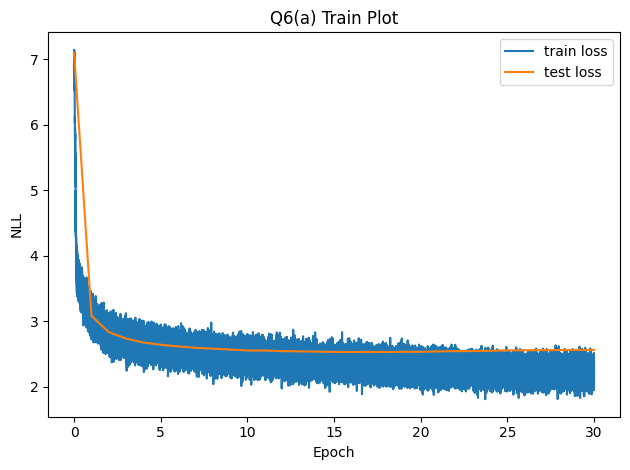

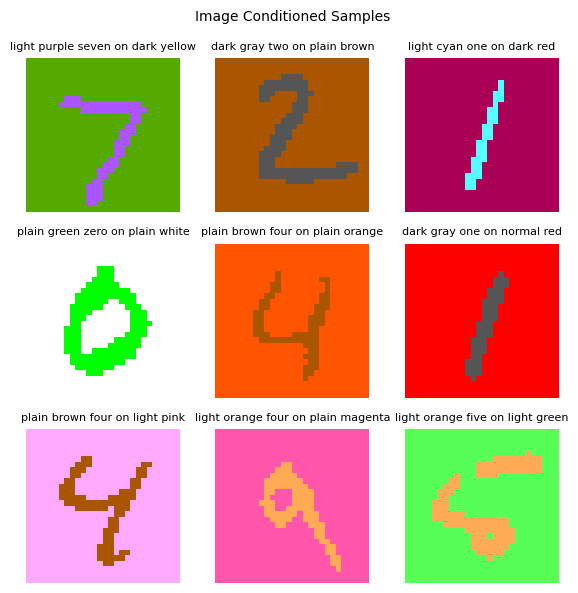

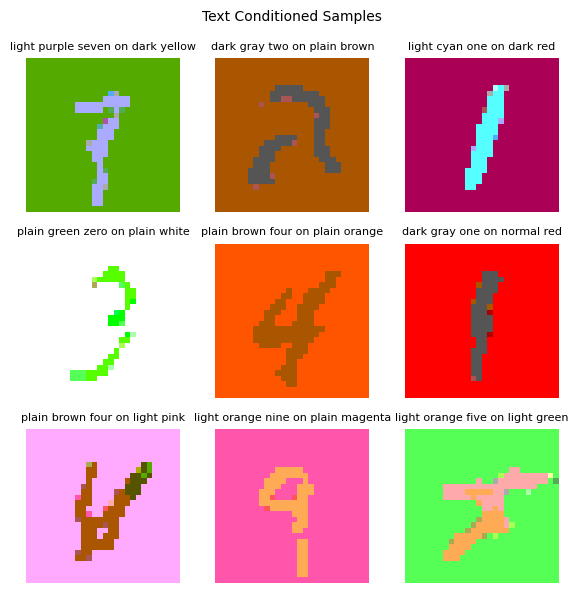

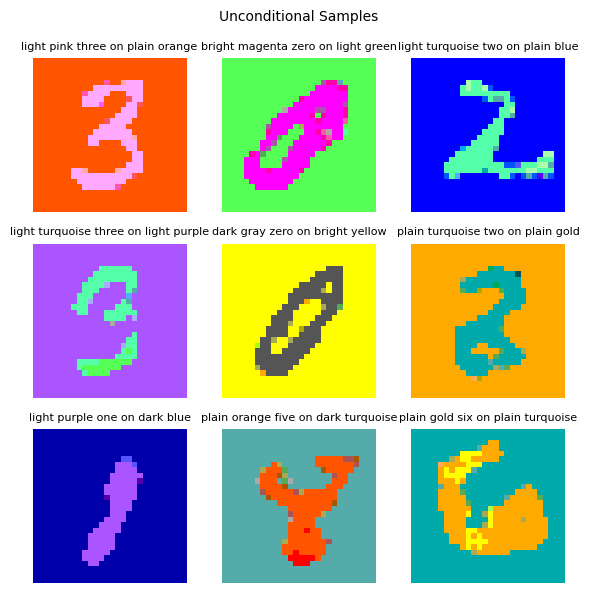

In [38]:
q6a_save_results(q6_a)

In [39]:

import sys
import torch
import numpy as np

# Retrieve the latest exception traceback
tb = getattr(sys, "last_traceback", None)

if tb is None:
    last_value = getattr(sys, "last_value", None)
    tb = getattr(last_value, "__traceback__", None)

if tb is None:
    try:
        error = get_ipython().last_execution_result.error_in_exec
        tb = error.__traceback__
    except Exception:
        tb = None

# Find the q6_a stack frame
q6a_locals = None

while tb is not None:

    if tb.tb_frame.f_code.co_name == "q6_a":
        q6a_locals = tb.tb_frame.f_locals.copy()
        break

    tb = tb.tb_next

if q6a_locals is None:

    print("Could not recover q6_a local variables.")

else:

    required_keys = [
        "model",
        "train_losses",
        "test_losses",
        "vocab_info",
        "id_to_word",
        "image_prompt_tokens",
        "prompt_text_tokens",
        "vqvae",
        "image_shape",
        "text_length"
    ]

    missing = [
        key for key in required_keys
        if key not in q6a_locals
    ]

    if missing:

        print("Missing variables:", missing)

    else:

        q6a_model = q6a_locals["model"]

        q6a_model.eval()

        q6a_vocab_info = q6a_locals["vocab_info"]

        q6a_id_to_word = q6a_locals["id_to_word"]

        q6a_image_prompt_tokens = q6a_locals["image_prompt_tokens"]

        q6a_prompt_text_tokens = q6a_locals["prompt_text_tokens"]

        q6a_vqvae = q6a_locals["vqvae"]

        q6a_image_shape = q6a_locals["image_shape"]

        q6a_text_length = q6a_locals["text_length"]

        torch.save(
            {
                "model_state_dict": q6a_model.state_dict(),
                "train_losses": np.asarray(q6a_locals["train_losses"]),
                "test_losses": np.asarray(q6a_locals["test_losses"]),
                "vocab_info": q6a_vocab_info,
                "id_to_word": q6a_id_to_word,
                "text_length": q6a_text_length
            },
            "q6a_recovered_checkpoint.pt"
        )

        print("=====================================")
        print("Training Model Recovered!")
        print("=====================================")
        print("Final Test NLL:", q6a_locals["test_losses"][-1])
        print("Checkpoint saved successfully.")


Missing variables: ['model', 'train_losses', 'test_losses', 'vocab_info', 'image_prompt_tokens']


In [40]:

import inspect

generation_functions = [
    "generate_image_to_text",
    "generate_text_to_image",
    "generate_unconditional_multimodal"
]

print("=====================================")
print("Q6(a) Generation Function Check")
print("=====================================")

for name in generation_functions:

    function = globals().get(name)

    if callable(function):

        print(f"[OK] {name}")

        print("     Signature:", inspect.signature(function))

    else:

        print(f"[MISSING] {name}")

print("=====================================")


Q6(a) Generation Function Check
[OK] generate_image_to_text
     Signature: (model, local_image_tokens, id_to_word, vocab_info, text_length, num_samples=9, temperature=1.0, top_k=None)
[OK] generate_text_to_image
     Signature: (model, text_tokens, vqvae, vocab_info, image_shape, num_samples=9, temperature=1.0, top_k=None)
[OK] generate_unconditional_multimodal
     Signature: (model, vqvae, id_to_word, vocab_info, image_shape, text_length, num_samples=9, temperature=1.0, top_k=None)
